# Project 1 — Color Recovery, Restoration, Edges and Matching

**Course:** CS-GY 6643 — Computer Vision  
**Team members:** Jim Lo, Ta-Chun Tai  


This notebook presents the implementations, executed results, quantitative
comparisons, and discussions for Questions 1–4. All four solutions use
classical computer vision methods and the instructor-provided data.
Q3 filtering, gradient computation, and edge selection are implemented
from scratch using basic NumPy operations. AI assistance and a summary
of the question chain are documented near the end of the notebook.

## Setup

Install numpy, pandas, matplotlib, Pillow, opencv-python and IPython. Place the course inputs in data/q1 through data/q4 under the notebook working directory. Run the cells in order. The notebook writes results under results/.

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display, Markdown
PROJECT = Path.cwd()
DATA = PROJECT / 'data'
RESULTS = PROJECT / 'results'
for q in ['q1', 'q2', 'q3', 'q4']:
    (RESULTS / q).mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)
print('Input data:', DATA)
print('Persistent results:', RESULTS)

In [ ]:
EXPECTED = {
    'q1': ['distorted_nebula.png', 'reference_rgb_histogram.csv', 'reference_rgb_histogram.png'],
    'q2': [f'observation_{i}.png' for i in range(1, 6)],
    'q3': ['degraded_spacecraft.png'],
    'q4': ['search_scene.jpg'] + [f'query_{i:02d}.png' for i in range(1, 6)],
}
def input_file(q, name):
    matches = list((DATA / q).rglob(name))
    if len(matches) != 1:
        raise FileNotFoundError(f'{q}/{name}: found {len(matches)} files; check downloads, permissions, or duplicate folders.')
    return matches[0]
for q, names in EXPECTED.items():
    for name in names:
        print(input_file(q, name).relative_to(DATA))

In [ ]:
def load_rgb(path):
    return np.asarray(Image.open(path).convert('RGB'))
def show_images(images, titles, figsize=(16, 5)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize, squeeze=False)
    for ax, im, title in zip(axes.ravel(), images, titles):
        ax.imshow(im, cmap='gray' if im.ndim == 2 else None)
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
def save_rgb(array, path):
    Image.fromarray(np.clip(np.rint(array), 0, 255).astype(np.uint8)).save(path)

## Q1 — Histogram Matching (5 points)

This section analyzes the distorted RGB image and supplied reference
histograms, compares upper-endpoint and midpoint CDF matching, and
selects midpoint matching for the final restoration. Original and
restored histograms, local comparisons, and saved-output checks are
included. CDF agreement is evaluated separately from reconstruction
accuracy against the unavailable clean image.

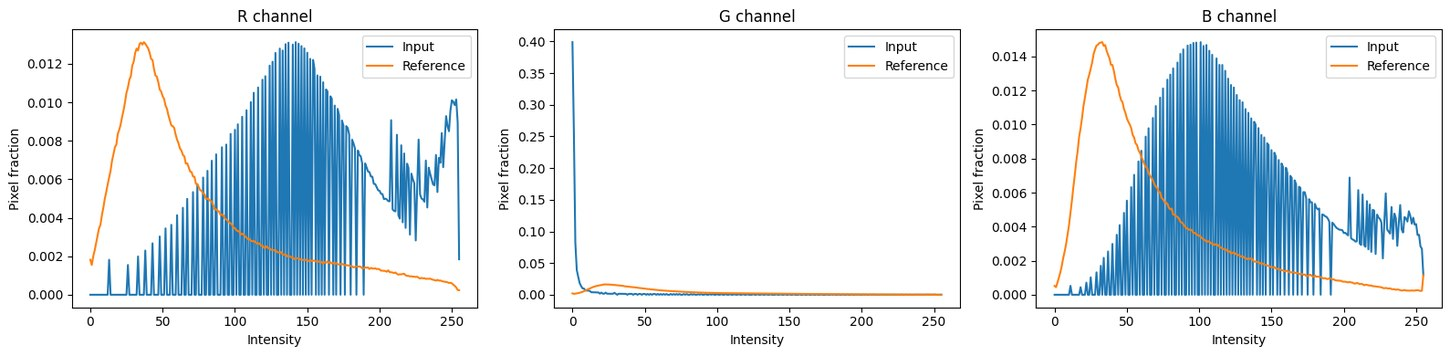

Image dimensions: 1672 x 941
Array shape: (941, 1672, 3)
Data type: uint8
Pixels per channel: 1,573,352


  channel  min  max      mean  unique_levels  zero_percent  \
0       R   13  255  172.5091            133        0.0000   
1       G    0  251    9.3718            133       39.8955   
2       B   11  255  144.1584            152        0.0000   

   full_scale_percent  most_common_level  most_common_percent  \
0              0.1841                142               1.3127   
1              0.0000                  0              39.8955   
2              0.1149                101               1.4844   

   reference_pixel_count  
0                1573352  
1                1573352  
2                1573352  

In [ ]:
# Q1 — Inspect the input image and reference histogram

q1_path = input_file("q1", "distorted_nebula.png")
q1_input = load_rgb(q1_path)

reference = (
    pd.read_csv(input_file("q1", "reference_rgb_histogram.csv"))
    .sort_values("intensity")
    .reset_index(drop=True)
)

assert q1_input.ndim == 3 and q1_input.shape[2] == 3
assert q1_input.dtype == np.uint8
assert np.array_equal(reference["intensity"].to_numpy(), np.arange(256))

ref_hist = reference[["red", "green", "blue"]].to_numpy(dtype=float)

assert np.isfinite(ref_hist).all()
assert (ref_hist >= 0).all()

height, width, channels = q1_input.shape
pixel_count = height * width

assert np.allclose(ref_hist.sum(axis=0), pixel_count)

print(f"Image dimensions: {width} x {height}")
print(f"Array shape: {q1_input.shape}")
print(f"Data type: {q1_input.dtype}")
print(f"Pixels per channel: {pixel_count:,}")

channel_names = ["R", "G", "B"]
input_hist = np.stack(
    [
        np.bincount(q1_input[..., c].ravel(), minlength=256)
        for c in range(3)
    ],
    axis=1,
)

rows = []

for c, name in enumerate(channel_names):
    values = q1_input[..., c]
    counts = input_hist[:, c]
    most_common = int(np.argmax(counts))

    rows.append({
        "channel": name,
        "min": int(values.min()),
        "max": int(values.max()),
        "mean": float(values.mean()),
        "unique_levels": int(np.count_nonzero(counts)),
        "zero_percent": 100 * counts[0] / pixel_count,
        "full_scale_percent": 100 * counts[255] / pixel_count,
        "most_common_level": most_common,
        "most_common_percent": 100 * counts[most_common] / pixel_count,
        "reference_pixel_count": int(ref_hist[:, c].sum()),
    })

display(pd.DataFrame(rows).round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for c, name in enumerate(channel_names):
    axes[c].plot(
        np.arange(256),
        input_hist[:, c] / pixel_count,
        label="Input",
    )
    axes[c].plot(
        np.arange(256),
        ref_hist[:, c] / ref_hist[:, c].sum(),
        label="Reference",
    )
    axes[c].set_title(f"{name} channel")
    axes[c].set_xlabel("Intensity")
    axes[c].set_ylabel("Pixel fraction")
    axes[c].legend()

plt.tight_layout()
plt.show()

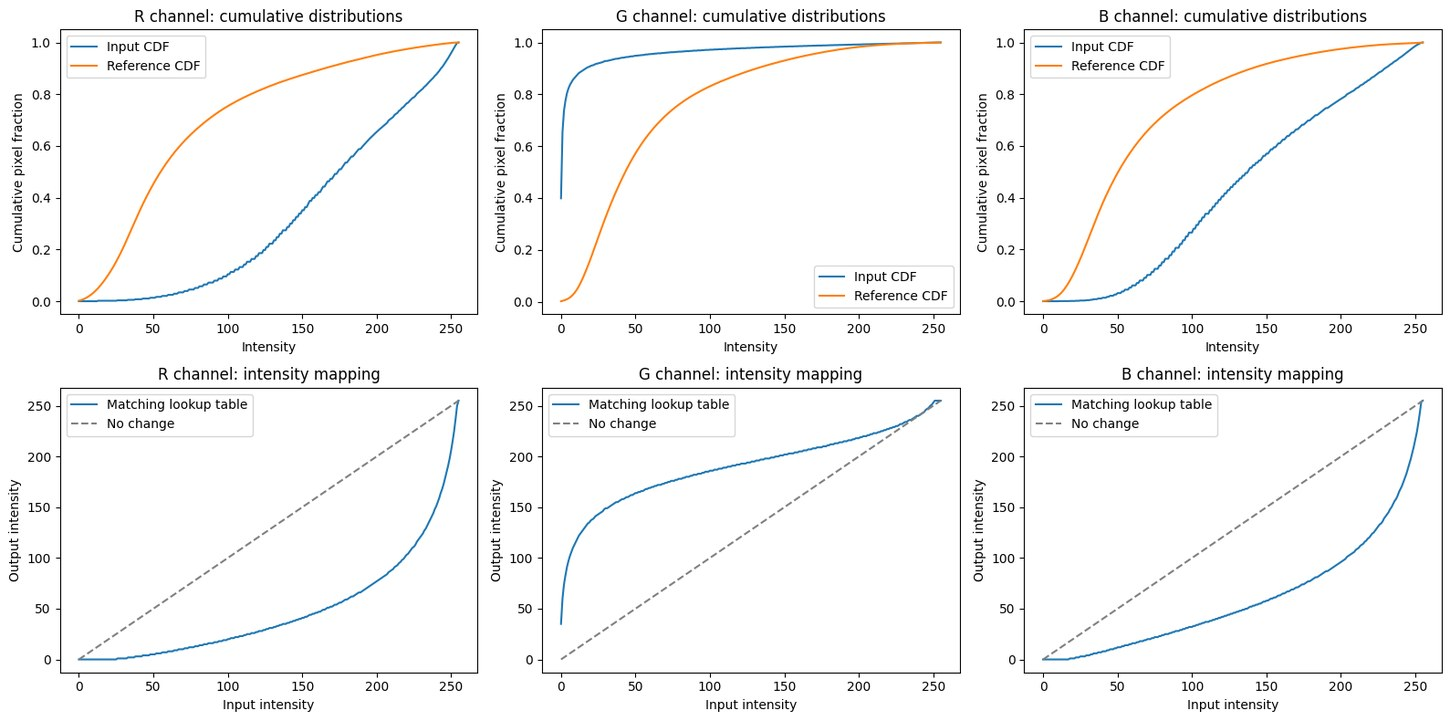

Green pixels at input intensity 0: 39.90%
Input green intensity 0 maps to: 35
Reference pixel fraction at that output intensity: 1.40%
All zero-valued green pixels map to that single output level; other input levels may map there as well.


In [ ]:
# Q1 — Inspect cumulative distributions and intensity mappings

input_cdf = np.cumsum(input_hist, axis=0) / input_hist.sum(
    axis=0, keepdims=True
)

reference_cdf = np.cumsum(ref_hist, axis=0) / ref_hist.sum(
    axis=0, keepdims=True
)

intensity_luts = np.zeros((256, 3), dtype=np.uint8)

for c in range(3):
    mapped_levels = np.searchsorted(
        reference_cdf[:, c],
        input_cdf[:, c],
        side="left",
    )
    intensity_luts[:, c] = np.clip(mapped_levels, 0, 255).astype(
        np.uint8
    )

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for c, name in enumerate(["R", "G", "B"]):
    axes[0, c].plot(input_cdf[:, c], label="Input CDF")
    axes[0, c].plot(reference_cdf[:, c], label="Reference CDF")
    axes[0, c].set_title(f"{name} channel: cumulative distributions")
    axes[0, c].set_xlabel("Intensity")
    axes[0, c].set_ylabel("Cumulative pixel fraction")
    axes[0, c].legend()

    axes[1, c].plot(
        np.arange(256),
        intensity_luts[:, c],
        label="Matching lookup table",
    )
    axes[1, c].plot(
        [0, 255], [0, 255], "--", color="gray", label="No change"
    )
    axes[1, c].set_title(f"{name} channel: intensity mapping")
    axes[1, c].set_xlabel("Input intensity")
    axes[1, c].set_ylabel("Output intensity")
    axes[1, c].legend()

plt.tight_layout()
plt.show()

green_zero_fraction = input_hist[0, 1] / input_hist[:, 1].sum()
green_zero_target = int(intensity_luts[0, 1])
target_bin_fraction = ref_hist[green_zero_target, 1] / ref_hist[:, 1].sum()

print(f"Green pixels at input intensity 0: {green_zero_fraction:.2%}")
print(f"Input green intensity 0 maps to: {green_zero_target}")
print(
    "Reference pixel fraction at that output intensity: "
    f"{target_bin_fraction:.2%}"
)
print(
    "All zero-valued green pixels map to that single output level; "
    "other input levels may map there as well."
)

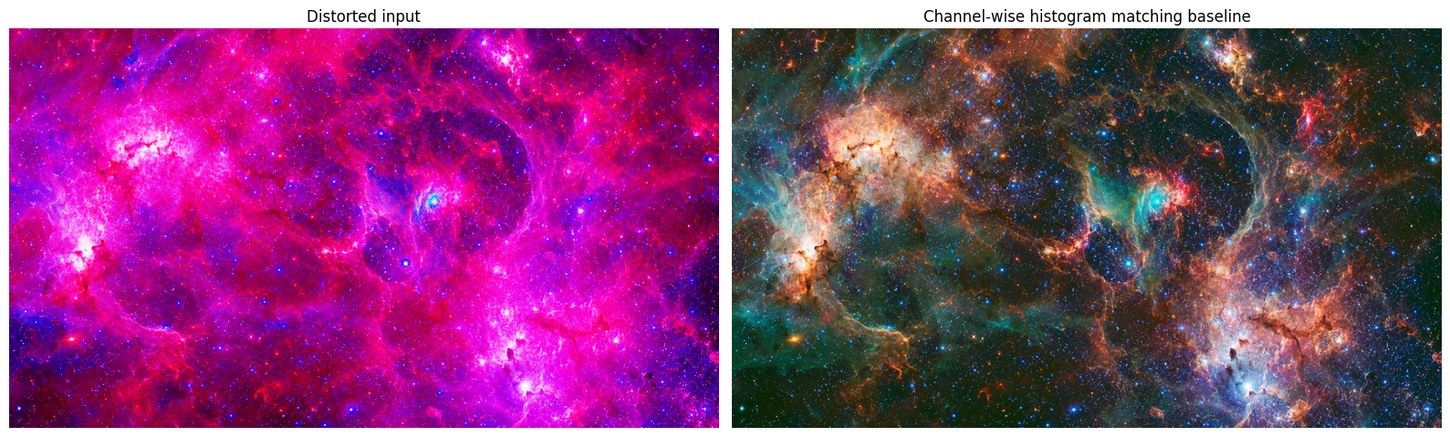

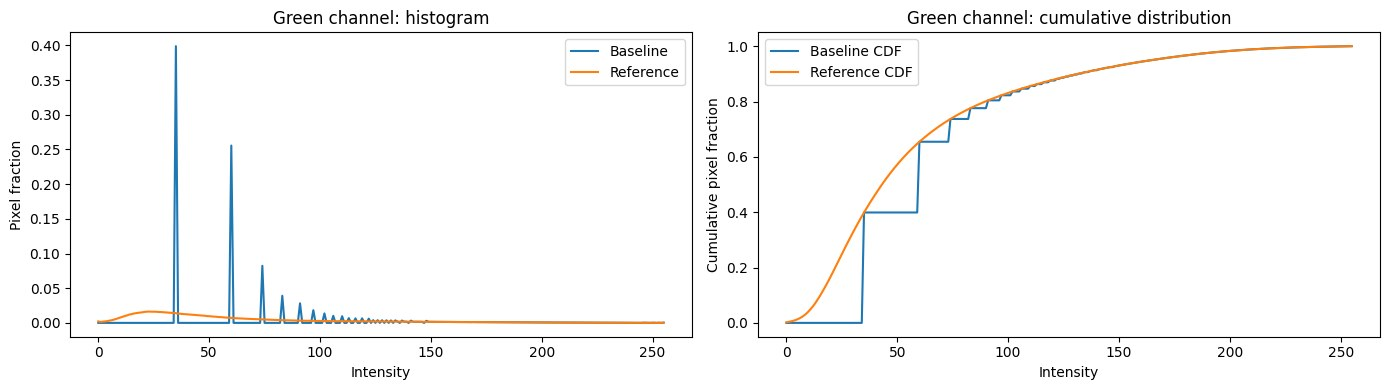

  channel  CDF_MAE_before  CDF_MAE_after
0       R        0.383896       0.001992
1       G        0.195154       0.037682
2       B        0.301684       0.000844

Minimum output green intensity: 35
Output green pixels at intensity 35: 39.90%
Reference green pixels below intensity 35: 38.50%


In [ ]:
# Q1 — Apply the lookup tables and inspect the baseline

q1_baseline = np.empty_like(q1_input)

for c in range(3):
    q1_baseline[..., c] = intensity_luts[:, c][q1_input[..., c]]

assert q1_baseline.shape == q1_input.shape
assert q1_baseline.dtype == np.uint8

baseline_hist = np.stack(
    [
        np.bincount(q1_baseline[..., c].ravel(), minlength=256)
        for c in range(3)
    ],
    axis=1,
)

baseline_cdf = np.cumsum(baseline_hist, axis=0) / baseline_hist.sum(
    axis=0, keepdims=True
)

display(pd.DataFrame({
    "channel": ["R", "G", "B"],
    "CDF_MAE_before": np.abs(input_cdf - reference_cdf).mean(axis=0),
    "CDF_MAE_after": np.abs(baseline_cdf - reference_cdf).mean(axis=0),
}))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(q1_input)
axes[0].set_title("Distorted input")
axes[1].imshow(q1_baseline)
axes[1].set_title("Channel-wise histogram matching baseline")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(
    baseline_hist[:, 1] / baseline_hist[:, 1].sum(),
    label="Baseline",
)
axes[0].plot(
    ref_hist[:, 1] / ref_hist[:, 1].sum(),
    label="Reference",
)
axes[0].set_title("Green channel: histogram")
axes[0].set_xlabel("Intensity")
axes[0].set_ylabel("Pixel fraction")
axes[0].legend()

axes[1].plot(baseline_cdf[:, 1], label="Baseline CDF")
axes[1].plot(reference_cdf[:, 1], label="Reference CDF")
axes[1].set_title("Green channel: cumulative distribution")
axes[1].set_xlabel("Intensity")
axes[1].set_ylabel("Cumulative pixel fraction")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Minimum output green intensity:", int(q1_baseline[..., 1].min()))
print(
    "Output green pixels at intensity 35:",
    f"{np.mean(q1_baseline[..., 1] == 35):.2%}",
)
print(
    "Reference green pixels below intensity 35:",
    f"{ref_hist[:35, 1].sum() / ref_hist[:, 1].sum():.2%}",
)

Image.fromarray(q1_baseline).save(
    RESULTS / "q1" / "histogram_matching_baseline.png"
)

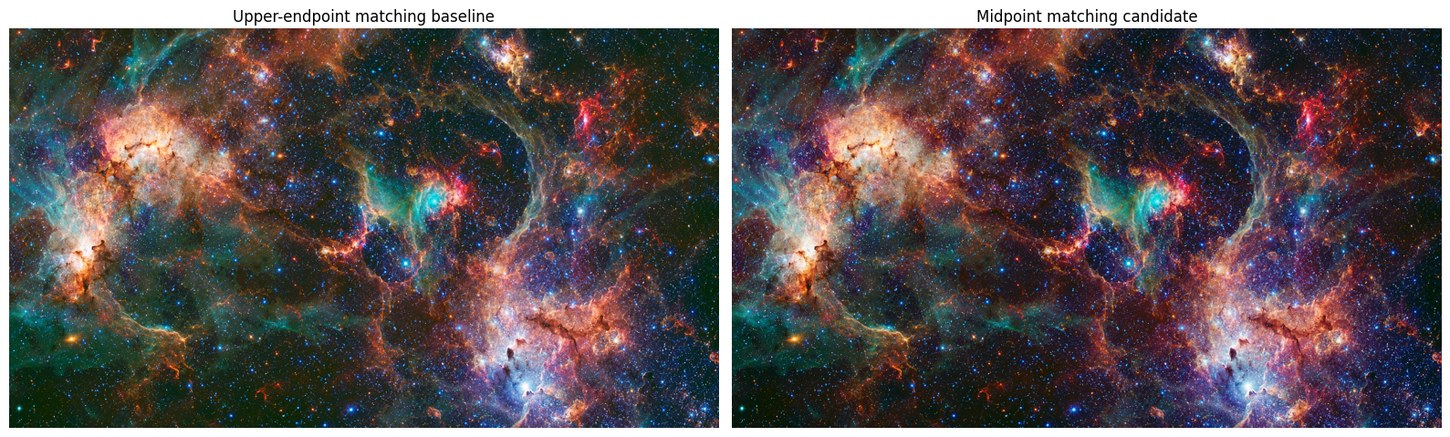

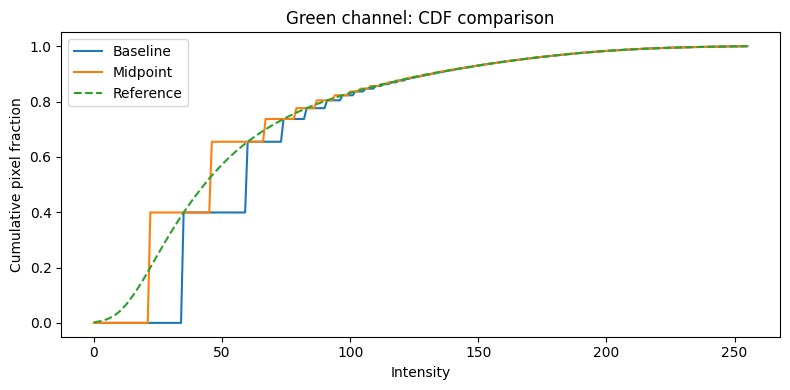

  channel  input_CDF_MAE  baseline_CDF_MAE  midpoint_CDF_MAE
0       R       0.383896          0.001992          0.001221
1       G       0.195154          0.037682          0.018956
2       B       0.301684          0.000844          0.000561

Green input 0: baseline output = 35
Green input 0: midpoint output = 22


In [ ]:
# Q1 — Compare upper-endpoint and midpoint CDF matching

input_prob = input_hist / input_hist.sum(axis=0, keepdims=True)

# Each input intensity occupies a percentile interval.
cdf_upper = np.cumsum(input_prob, axis=0)
cdf_lower = cdf_upper - input_prob
cdf_midpoint = (cdf_lower + cdf_upper) / 2.0

midpoint_luts = np.zeros((256, 3), dtype=np.uint8)

for c in range(3):
    mapped_levels = np.searchsorted(
        reference_cdf[:, c],
        cdf_midpoint[:, c],
        side="left",
    )
    midpoint_luts[:, c] = np.clip(
        mapped_levels, 0, 255
    ).astype(np.uint8)

q1_midpoint = np.empty_like(q1_input)

for c in range(3):
    q1_midpoint[..., c] = midpoint_luts[:, c][q1_input[..., c]]

assert q1_midpoint.shape == q1_input.shape
assert q1_midpoint.dtype == np.uint8

midpoint_hist = np.stack(
    [
        np.bincount(q1_midpoint[..., c].ravel(), minlength=256)
        for c in range(3)
    ],
    axis=1,
)

midpoint_cdf = np.cumsum(midpoint_hist, axis=0) / midpoint_hist.sum(
    axis=0, keepdims=True
)

display(pd.DataFrame({
    "channel": ["R", "G", "B"],
    "input_CDF_MAE": np.abs(
        input_cdf - reference_cdf
    ).mean(axis=0),
    "baseline_CDF_MAE": np.abs(
        baseline_cdf - reference_cdf
    ).mean(axis=0),
    "midpoint_CDF_MAE": np.abs(
        midpoint_cdf - reference_cdf
    ).mean(axis=0),
}))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(q1_baseline)
axes[0].set_title("Upper-endpoint matching baseline")

axes[1].imshow(q1_midpoint)
axes[1].set_title("Midpoint matching candidate")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(baseline_cdf[:, 1], label="Baseline")
plt.plot(midpoint_cdf[:, 1], label="Midpoint")
plt.plot(reference_cdf[:, 1], "--", label="Reference")
plt.title("Green channel: CDF comparison")
plt.xlabel("Intensity")
plt.ylabel("Cumulative pixel fraction")
plt.legend()
plt.tight_layout()
plt.show()

print("Green input 0: baseline output =", int(intensity_luts[0, 1]))
print("Green input 0: midpoint output =", int(midpoint_luts[0, 1]))

Image.fromarray(q1_midpoint).save(
    RESULTS / "q1" / "histogram_matching_midpoint.png"
)

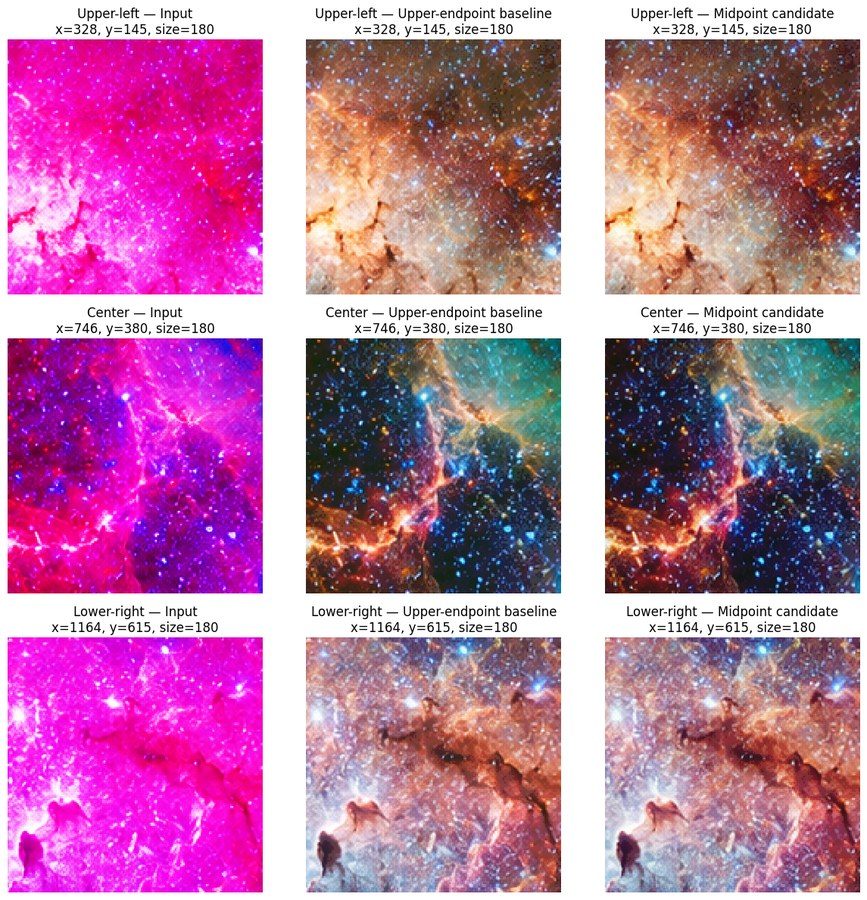

In [ ]:
# Q1 — Compare local details using identical crops

height, width = q1_input.shape[:2]
crop_size = min(180, height, width)

# Use fixed relative positions for reproducible inspection.
crop_positions = [
    ("Upper-left", 0.25, 0.25),
    ("Center", 0.50, 0.50),
    ("Lower-right", 0.75, 0.75),
]

versions = [
    ("Input", q1_input),
    ("Upper-endpoint baseline", q1_baseline),
    ("Midpoint candidate", q1_midpoint),
]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, (region_name, x_fraction, y_fraction) in enumerate(crop_positions):
    center_x = int(x_fraction * width)
    center_y = int(y_fraction * height)

    x0 = int(np.clip(center_x - crop_size // 2, 0, width - crop_size))
    y0 = int(np.clip(center_y - crop_size // 2, 0, height - crop_size))

    for col, (method_name, image) in enumerate(versions):
        crop = image[y0:y0 + crop_size, x0:x0 + crop_size]

        axes[row, col].imshow(crop, interpolation="nearest")
        axes[row, col].set_title(
            f"{region_name} — {method_name}\n"
            f"x={x0}, y={y0}, size={crop_size}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
fig.savefig(
    RESULTS / "q1" / "local_matching_comparison.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

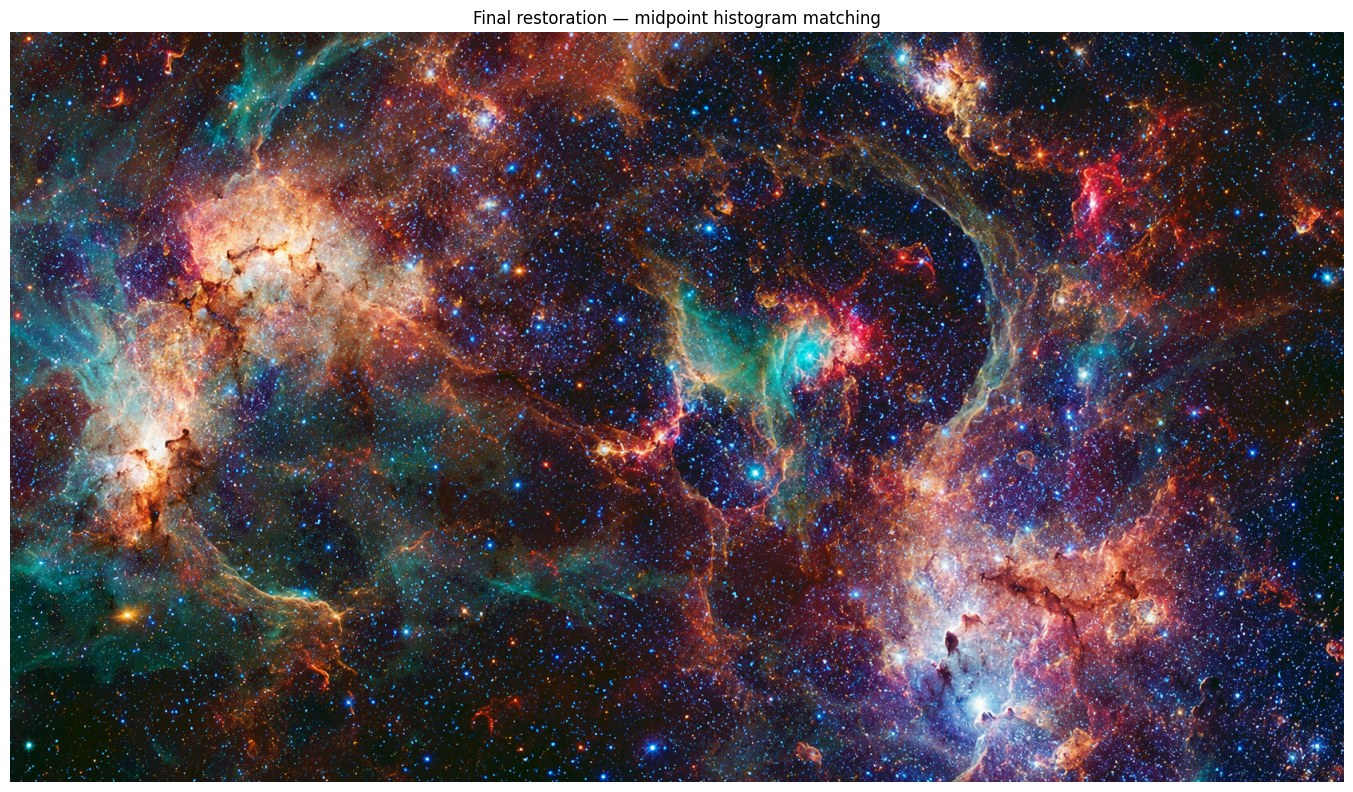

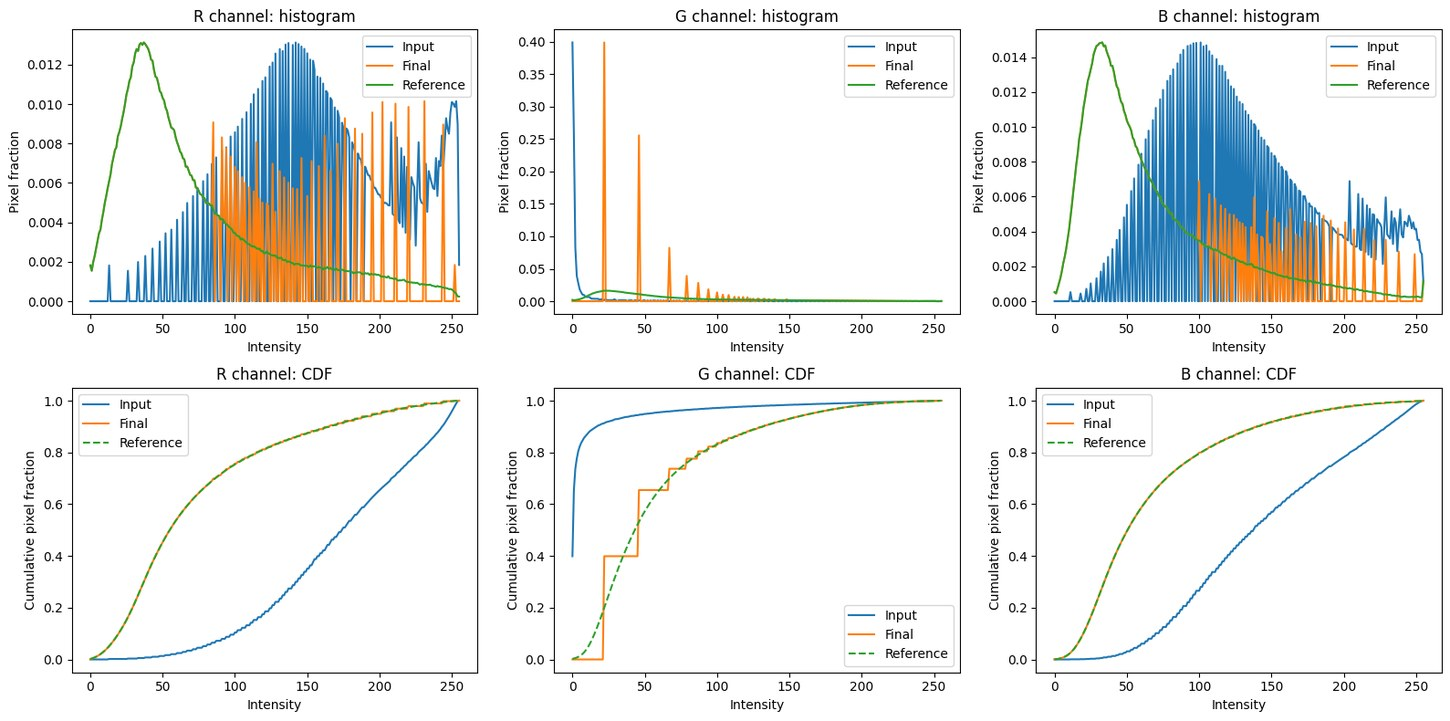

  channel  input_CDF_MAE  baseline_CDF_MAE  final_CDF_MAE
0       R       0.383896          0.001992       0.001221
1       G       0.195154          0.037682       0.018956
2       B       0.301684          0.000844       0.000561

In [ ]:
# Q1 — Final selection, required figures, and quantitative comparison

q1_final = q1_midpoint.copy()

assert q1_final.shape == q1_input.shape
assert q1_final.dtype == np.uint8

final_hist = np.stack(
    [
        np.bincount(q1_final[..., c].ravel(), minlength=256)
        for c in range(3)
    ],
    axis=1,
)

final_cdf = np.cumsum(final_hist, axis=0) / final_hist.sum(
    axis=0, keepdims=True
)

q1_metrics = pd.DataFrame({
    "channel": ["R", "G", "B"],
    "input_CDF_MAE": np.abs(
        input_cdf - reference_cdf
    ).mean(axis=0),
    "baseline_CDF_MAE": np.abs(
        baseline_cdf - reference_cdf
    ).mean(axis=0),
    "final_CDF_MAE": np.abs(
        final_cdf - reference_cdf
    ).mean(axis=0),
})

Image.fromarray(q1_final).save(RESULTS / "q1" / "restored.png")
q1_metrics.to_csv(RESULTS / "q1" / "cdf_metrics.csv", index=False)

# Display the final result directly below the code.
fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(q1_final)
ax.set_title("Final restoration — midpoint histogram matching")
ax.axis("off")
plt.tight_layout()
plt.show()

# Compare input, final, and reference histograms for all channels.
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for c, name in enumerate(["R", "G", "B"]):
    for counts, label in [
        (input_hist, "Input"),
        (final_hist, "Final"),
        (ref_hist, "Reference"),
    ]:
        probability = counts[:, c] / counts[:, c].sum()
        axes[0, c].plot(probability, label=label)

    axes[0, c].set_title(f"{name} channel: histogram")
    axes[0, c].set_xlabel("Intensity")
    axes[0, c].set_ylabel("Pixel fraction")
    axes[0, c].legend()

    axes[1, c].plot(input_cdf[:, c], label="Input")
    axes[1, c].plot(final_cdf[:, c], label="Final")
    axes[1, c].plot(
        reference_cdf[:, c], "--", label="Reference"
    )
    axes[1, c].set_title(f"{name} channel: CDF")
    axes[1, c].set_xlabel("Intensity")
    axes[1, c].set_ylabel("Cumulative pixel fraction")
    axes[1, c].legend()

plt.tight_layout()
fig.savefig(
    RESULTS / "q1" / "final_histogram_comparison.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

display(q1_metrics.round(6))

# Check the saved image, not just the in-memory array.
with Image.open(RESULTS / "q1" / "restored.png") as saved:
    assert saved.size == (q1_input.shape[1], q1_input.shape[0])
    assert saved.mode == "RGB"
    assert np.array_equal(np.asarray(saved), q1_final)
    print("Saved image dimensions:", saved.size)

print("Selected method: midpoint histogram matching")
print("Additional spatial filtering: none")
print("Final image saved to:", RESULTS / "q1" / "restored.png")

In [ ]:
# Q1 — Independently verify the saved image and its distributions

saved_path = RESULTS / "q1" / "restored.png"

with Image.open(saved_path) as image:
    verified_rgb = np.array(image.convert("RGB"))

verified_reference = (
    pd.read_csv(input_file("q1", "reference_rgb_histogram.csv"))
    .sort_values("intensity")
)
verified_ref_counts = verified_reference[
    ["red", "green", "blue"]
].to_numpy(dtype=np.float64)

verified_counts = np.stack(
    [
        np.bincount(verified_rgb[..., c].ravel(), minlength=256)
        for c in range(3)
    ],
    axis=1,
)

verified_prob = verified_counts / verified_counts.sum(
    axis=0, keepdims=True
)
verified_ref_prob = verified_ref_counts / verified_ref_counts.sum(
    axis=0, keepdims=True
)

verified_cdf = np.cumsum(verified_prob, axis=0)
verified_ref_cdf = np.cumsum(verified_ref_prob, axis=0)

print("Saved image equals q1_final:",
      np.array_equal(verified_rgb, q1_final))
print("Saved image equals q1_midpoint:",
      np.array_equal(verified_rgb, q1_midpoint))
print("Recomputed histogram equals final_hist:",
      np.array_equal(verified_counts, final_hist))
print("Recomputed CDF matches final_cdf:",
      np.allclose(verified_cdf, final_cdf))

display(pd.DataFrame({
    "channel": ["R", "G", "B"],
    "saved_image_CDF_MAE": np.abs(
        verified_cdf - verified_ref_cdf
    ).mean(axis=0),
    "fraction_at_or_below_100": verified_prob[:101].sum(axis=0),
    "CDF_at_100": verified_cdf[100],
}))

Saved image equals q1_final: True
Saved image equals q1_midpoint: True
Recomputed histogram equals final_hist: True
Recomputed CDF matches final_cdf: True


  channel  saved_image_CDF_MAE  fraction_at_or_below_100  CDF_at_100
0       R             0.001221                  0.757279    0.757279
1       G             0.018956                  0.836266    0.836266
2       B             0.000561                  0.799357    0.799357

### Q1 — Method, Results, and Limitations

#### Input analysis

The distorted image has dimensions of 1672 × 941 pixels and contains
three 8-bit RGB channels. Each reference histogram contains 1,573,352
counts, matching the number of pixels per channel.

The input red and blue distributions are shifted toward higher
intensities relative to the reference distributions, while the green
channel is concentrated at low intensities. Approximately 39.90% of
the input green pixels have intensity 0. This concentration is
consistent with information loss from clipping or another many-to-one
intensity transformation, although the exact degradation cannot be
determined from the histogram alone.

#### Restoration method

I compared two forms of independent channel-wise histogram matching.

The baseline maps each input intensity using the upper endpoint of
its cumulative probability interval. The final method instead uses
the midpoint of that interval.

For input intensity k, let p(k) be its pixel fraction and F(k) its
cumulative pixel fraction. The midpoint probability is:

q(k) = F(k) - p(k) / 2

The output intensity is the smallest reference intensity whose CDF
is greater than or equal to q(k). This produces a monotonic lookup
table for each RGB channel. The lookup tables change pixel values
without changing pixel locations or image dimensions.

For the green channel, the baseline maps input intensity 0 to 35,
whereas midpoint matching maps it to 22. Midpoint matching uses a
central percentile to represent each group of tied input values,
rather than the upper endpoint.

#### Quantitative results

CDF MAE is the mean absolute difference between the image CDF and
the reference CDF over the 256 intensity levels. Lower values indicate
closer agreement between the cumulative distributions.

| Channel | Input CDF MAE | Baseline CDF MAE | Final CDF MAE |
|---|---:|---:|---:|
| R | 0.383896 | 0.001992 | 0.001221 |
| G | 0.195154 | 0.037682 | 0.018956 |
| B | 0.301684 | 0.000844 | 0.000561 |

Midpoint matching reduced CDF MAE for all three channels compared
with the baseline. The green-channel CDF MAE decreased by approximately
49.7%, although it remained higher than the red and blue errors.

These measurements evaluate distribution agreement, not pixel-level
reconstruction accuracy.

#### Visual assessment and processing choices

The restored image shows a reduced magenta cast compared with the
distorted input. Identical local crops were used to compare the two
matching methods. The visible nebular structures and point-like
features remain at the same locations, while their colors and
intensities change.

Midpoint matching was selected because it improved the measured CDF
agreement and provided a more central representative value for tied
intensity groups. No additional spatial filtering was applied.
The small bright features could include real stars, and smoothing
could remove genuine fine structure without sufficient evidence that
those features are noise.

#### Limitations

A deterministic lookup table assigns the same output intensity to
every pixel with the same input intensity. Therefore, the large group
of zero-valued green pixels remains concentrated at a single output
intensity after matching. Midpoint matching changes the location of
this concentration but does not recover differences within the group.

Histogram matching can correct aspects of a global intensity or color
distribution when the available intensity ordering is informative.
It cannot uniquely recover information lost through clipping or
quantization, restore blurred spatial detail, or determine the correct
spatial arrangement from histograms alone. Independent RGB histograms
also do not specify the joint relationship between the color channels.

The clean reference image is unavailable, so reconstruction PSNR and
SSIM were not computed. A close histogram or CDF match does not
guarantee accurate recovery of the hidden original image.

#### Output verification

The final image was saved as `restored.png` at its original dimensions
of 1672 × 941 pixels. Reloading the saved PNG confirmed exact equality
with the selected midpoint result. Histograms and CDFs recomputed from
the saved file also matched the in-memory results.

## Q2 — Multi-observation Restoration (10 points)

This section analyzes all five observations, checks geometric consistency,
and compares intensity calibration and fusion methods. The selected
reconstruction uses calibrated, spatially varying agreement weights
and supported values from Observation 5. Raw averaging and calibrated
available-value averaging provide comparison baselines. Observation 1
provides a provisional intensity scale rather than ground truth.

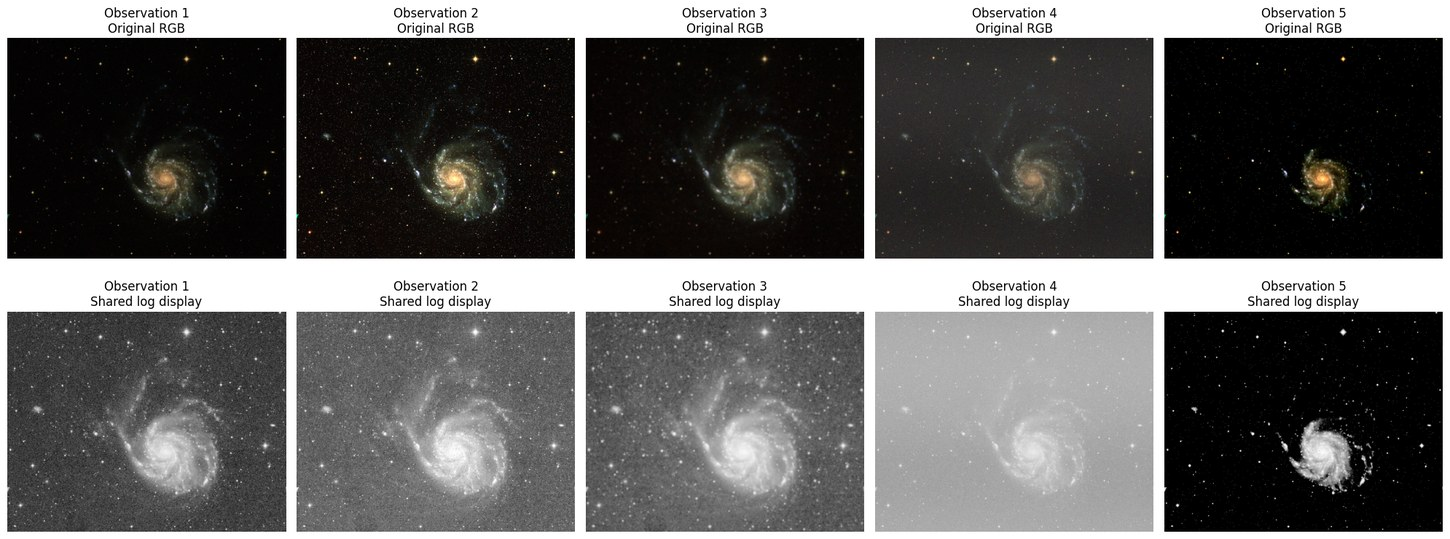

   observation  mean_gray  std_gray  p01_gray  median_gray  p99_gray  \
0            1     8.3517   16.5941    0.0000        4.120   93.8978   
1            2    17.9965   32.7317    1.2390        9.506  207.4596   
2            3    14.3652   21.7751    1.7940        7.902  123.9312   
3            4    44.6319   14.6300   21.8254       42.806  107.0690   
4            5     3.5569   20.4141    0.0000        0.000  107.3460   

   all_channels_zero_percent  any_channel_255_percent  
0                     4.3509                   0.0000  
1                     0.6057                   0.9145  
2                     0.0124                   0.0000  
3                     0.0000                   0.0001  
4                    93.4080                   0.2902  

In [ ]:
# Q2 — Inspect all five observations before fusion

q2_inputs = [
    load_rgb(input_file("q2", f"observation_{i}.png"))
    for i in range(1, 6)
]

for i, image in enumerate(q2_inputs, start=1):
    assert image.shape == (810, 1024, 3), (
        f"Unexpected shape for observation {i}: {image.shape}"
    )
    assert image.dtype == np.uint8

# Compute a grayscale intensity proxy for descriptive statistics.
q2_gray = [
    image.astype(np.float64) @ np.array([0.299, 0.587, 0.114])
    for image in q2_inputs
]

rows = []

for i, (image, gray) in enumerate(zip(q2_inputs, q2_gray), start=1):
    p01, p50, p99 = np.percentile(gray, [1, 50, 99])

    rows.append({
        "observation": i,
        "mean_gray": gray.mean(),
        "std_gray": gray.std(),
        "p01_gray": p01,
        "median_gray": p50,
        "p99_gray": p99,
        "all_channels_zero_percent": (
            100 * np.all(image == 0, axis=2).mean()
        ),
        "any_channel_255_percent": (
            100 * np.any(image == 255, axis=2).mean()
        ),
    })

q2_input_summary = pd.DataFrame(rows)
display(q2_input_summary.round(4))

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for c, (image, gray) in enumerate(zip(q2_inputs, q2_gray)):
    # Original RGB values; no per-image contrast adjustment.
    axes[0, c].imshow(image)
    axes[0, c].set_title(f"Observation {c + 1}\nOriginal RGB")
    axes[0, c].axis("off")

    # Apply the same display-only transform to every observation.
    display_gray = np.log1p(gray) / np.log1p(255.0)

    axes[1, c].imshow(
        display_gray,
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[1, c].set_title(f"Observation {c + 1}\nShared log display")
    axes[1, c].axis("off")

plt.tight_layout()
plt.show()

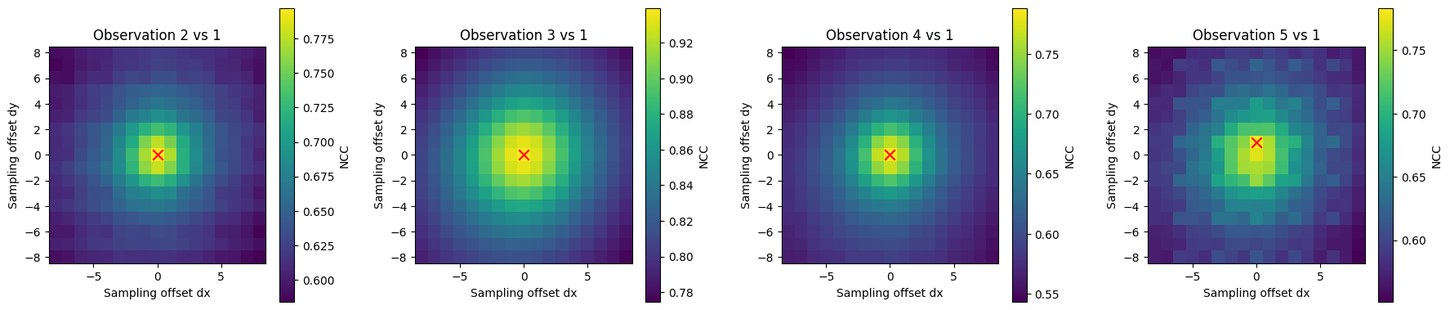

   observation  best_sampling_dx  best_sampling_dy  NCC_at_zero  best_NCC  \
0            2                 0                 0     0.797431  0.797431   
1            3                 0                 0     0.939622  0.939622   
2            4                 0                 0     0.788228  0.788228   
3            5                 0                 1     0.772068  0.783402   

   NCC_gain  peak_on_search_boundary  
0  0.000000                    False  
1  0.000000                    False  
2  0.000000                    False  
3  0.011333                    False  

This is a translation screening test, not a final registration.
Sampling offsets locate corresponding content in the moving image.
An actual alignment shift would have the opposite sign.


In [ ]:
# Q2 — Screen for small integer translations using normalized correlation

def normalized_correlation(a, b):
    a = a.astype(np.float64, copy=False)
    b = b.astype(np.float64, copy=False)

    a_centered = a - a.mean()
    b_centered = b - b.mean()

    denominator = np.sqrt(
        np.sum(a_centered ** 2) * np.sum(b_centered ** 2)
    )

    if denominator <= 1e-12:
        return np.nan

    return np.sum(a_centered * b_centered) / denominator


reference_gray = q2_gray[0]
height, width = reference_gray.shape

search_radius = 8
sample_step = 3
offsets = np.arange(-search_radius, search_radius + 1)

# Use a fixed interior region so all candidates use the same pixel count.
ys = np.arange(search_radius, height - search_radius, sample_step)
xs = np.arange(search_radius, width - search_radius, sample_step)

reference_samples = reference_gray[np.ix_(ys, xs)]

q2_translation_rows = []
q2_translation_maps = []

for observation_index, moving_gray in enumerate(q2_gray[1:], start=2):
    scores = np.empty((len(offsets), len(offsets)), dtype=float)

    for row, dy in enumerate(offsets):
        for col, dx in enumerate(offsets):
            moving_samples = moving_gray[np.ix_(ys + dy, xs + dx)]
            scores[row, col] = normalized_correlation(
                reference_samples, moving_samples
            )

    best_row, best_col = np.unravel_index(
        np.nanargmax(scores), scores.shape
    )

    best_dx = int(offsets[best_col])
    best_dy = int(offsets[best_row])
    zero_score = float(scores[search_radius, search_radius])
    best_score = float(scores[best_row, best_col])

    q2_translation_rows.append({
        "observation": observation_index,
        "best_sampling_dx": best_dx,
        "best_sampling_dy": best_dy,
        "NCC_at_zero": zero_score,
        "best_NCC": best_score,
        "NCC_gain": best_score - zero_score,
        "peak_on_search_boundary": (
            abs(best_dx) == search_radius
            or abs(best_dy) == search_radius
        ),
    })
    q2_translation_maps.append(scores)

q2_translation_summary = pd.DataFrame(q2_translation_rows)
display(q2_translation_summary.round(6))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, scores, result in zip(
    axes, q2_translation_maps, q2_translation_rows
):
    plot = ax.imshow(
        scores,
        origin="lower",
        extent=[
            -search_radius - 0.5, search_radius + 0.5,
            -search_radius - 0.5, search_radius + 0.5,
        ],
        cmap="viridis",
        aspect="equal",
    )

    ax.scatter(
        result["best_sampling_dx"],
        result["best_sampling_dy"],
        marker="x",
        color="red",
        s=80,
    )
    ax.set_title(f"Observation {result['observation']} vs 1")
    ax.set_xlabel("Sampling offset dx")
    ax.set_ylabel("Sampling offset dy")
    fig.colorbar(plot, ax=ax, label="NCC")

plt.tight_layout()
plt.show()

print("This is a translation screening test, not a final registration.")
print("Sampling offsets locate corresponding content in the moving image.")
print("An actual alignment shift would have the opposite sign.")

In [ ]:
# Q2 — Verify the candidate translation of observation 5

moving_gray = q2_gray[4]
height, width = moving_gray.shape
radius = 3
local_offsets = np.arange(-radius, radius + 1)

# Define reproducible regions using image dimensions.
regions = {
    "Full interior": (
        radius, height - radius,
        radius, width - radius,
    ),
    "Upper-left": (
        radius, height // 2,
        radius, width // 2,
    ),
    "Upper-right": (
        radius, height // 2,
        width // 2, width - radius,
    ),
    "Lower-left": (
        height // 2, height - radius,
        radius, width // 2,
    ),
    "Lower-right": (
        height // 2, height - radius,
        width // 2, width - radius,
    ),
}

verification_rows = []

for reference_index in [0, 1]:
    reference_gray = q2_gray[reference_index]

    for region_name, (y0, y1, x0, x1) in regions.items():
        reference_patch = reference_gray[y0:y1, x0:x1]

        scores = np.empty(
            (len(local_offsets), len(local_offsets)),
            dtype=float,
        )

        for row, dy in enumerate(local_offsets):
            for col, dx in enumerate(local_offsets):
                moving_patch = moving_gray[
                    y0 + dy:y1 + dy,
                    x0 + dx:x1 + dx,
                ]

                scores[row, col] = normalized_correlation(
                    reference_patch, moving_patch
                )

        if not np.isfinite(scores).any():
            raise ValueError(
                f"No valid correlation scores for {region_name}."
            )

        best_row, best_col = np.unravel_index(
            np.nanargmax(scores), scores.shape
        )

        best_dx = int(local_offsets[best_col])
        best_dy = int(local_offsets[best_row])

        zero_score = float(scores[radius, radius])
        candidate_score = float(scores[radius + 1, radius])
        best_score = float(scores[best_row, best_col])

        verification_rows.append({
            "reference": reference_index + 1,
            "region": region_name,
            "best_dx": best_dx,
            "best_dy": best_dy,
            "NCC_at_zero": zero_score,
            "NCC_at_dx0_dy1": candidate_score,
            "candidate_gain": candidate_score - zero_score,
            "best_NCC": best_score,
            "peak_on_boundary": (
                abs(best_dx) == radius
                or abs(best_dy) == radius
            ),
        })

q2_obs5_translation_check = pd.DataFrame(verification_rows)
display(q2_obs5_translation_check.round(6))

print("All pixels within each region were used; no spatial subsampling.")
print("Observation 5 has not been shifted.")

   reference         region  best_dx  best_dy  NCC_at_zero  NCC_at_dx0_dy1  \
0          1  Full interior        0        0     0.775720        0.759521   
1          1     Upper-left        0        0     0.376631        0.335120   
2          1    Upper-right        0        0     0.433825        0.400219   
3          1     Lower-left        0        0     0.581322        0.547466   
4          1    Lower-right        0        0     0.891646        0.881262   
5          2  Full interior        0        0     0.618448        0.604378   
6          2     Upper-left        0        0     0.196682        0.171240   
7          2    Upper-right        0        0     0.235718        0.216872   
8          2     Lower-left        0        0     0.379215        0.355754   
9          2    Lower-right        0        0     0.804859        0.794968   

   candidate_gain  best_NCC  peak_on_boundary  
0       -0.016199  0.775720             False  
1       -0.041512  0.376631             False

All pixels within each region were used; no spatial subsampling.
Observation 5 has not been shifted.


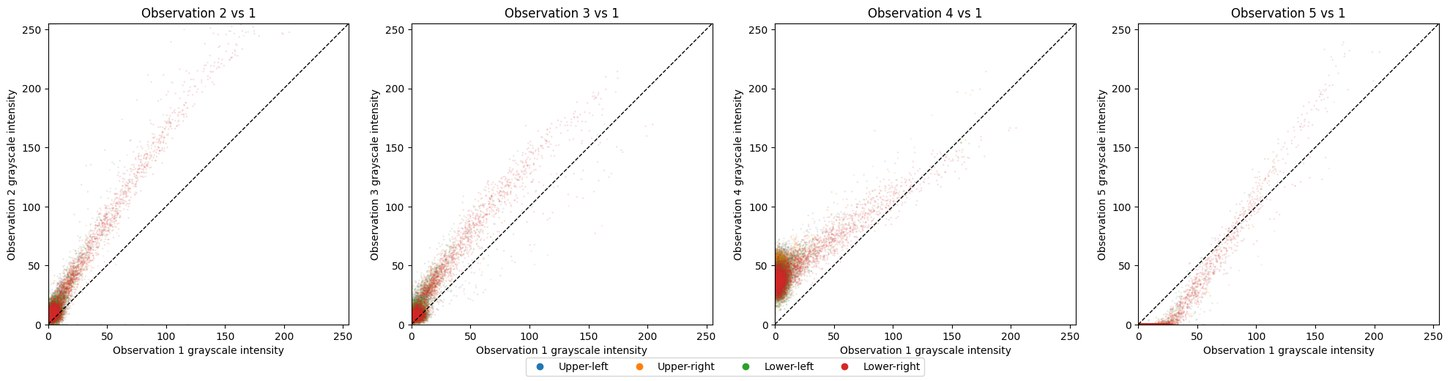

Compared 20,000 identical pixel locations.
Observation 1 is a comparison reference, not ground truth.
No intensity correction or spatial transformation was applied.


In [ ]:
# Q2 — Inspect intensity relationships at corresponding coordinates

rng = np.random.default_rng(42)

height, width = q2_gray[0].shape
sample_count = min(20000, height * width)

sample_indices = rng.choice(
    height * width,
    size=sample_count,
    replace=False,
)

reference_samples = q2_gray[0].ravel()[sample_indices]

# Color samples by their location in the image.
sample_y, sample_x = np.unravel_index(
    sample_indices, (height, width)
)
region_ids = (
    2 * (sample_y >= height // 2).astype(int)
    + (sample_x >= width // 2).astype(int)
)

region_names = [
    "Upper-left",
    "Upper-right",
    "Lower-left",
    "Lower-right",
]
region_colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, observation_index in zip(axes, range(1, 5)):
    moving_samples = q2_gray[observation_index].ravel()[sample_indices]

    for region_id, (name, color) in enumerate(
        zip(region_names, region_colors)
    ):
        mask = region_ids == region_id

        ax.scatter(
            reference_samples[mask],
            moving_samples[mask],
            s=3,
            alpha=0.15,
            color=color,
            edgecolors="none",
            rasterized=True,
        )

    ax.plot(
        [0, 255], [0, 255],
        "--", color="black", linewidth=1,
    )
    ax.set_xlim(0, 255)
    ax.set_ylim(0, 255)
    ax.set_aspect("equal")
    ax.set_xlabel("Observation 1 grayscale intensity")
    ax.set_ylabel(
        f"Observation {observation_index + 1} grayscale intensity"
    )
    ax.set_title(f"Observation {observation_index + 1} vs 1")

legend_handles = [
    plt.Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        color=color,
        label=name,
    )
    for name, color in zip(region_names, region_colors)
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=4,
)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

print(f"Compared {sample_count:,} identical pixel locations.")
print("Observation 1 is a comparison reference, not ground truth.")
print("No intensity correction or spatial transformation was applied.")

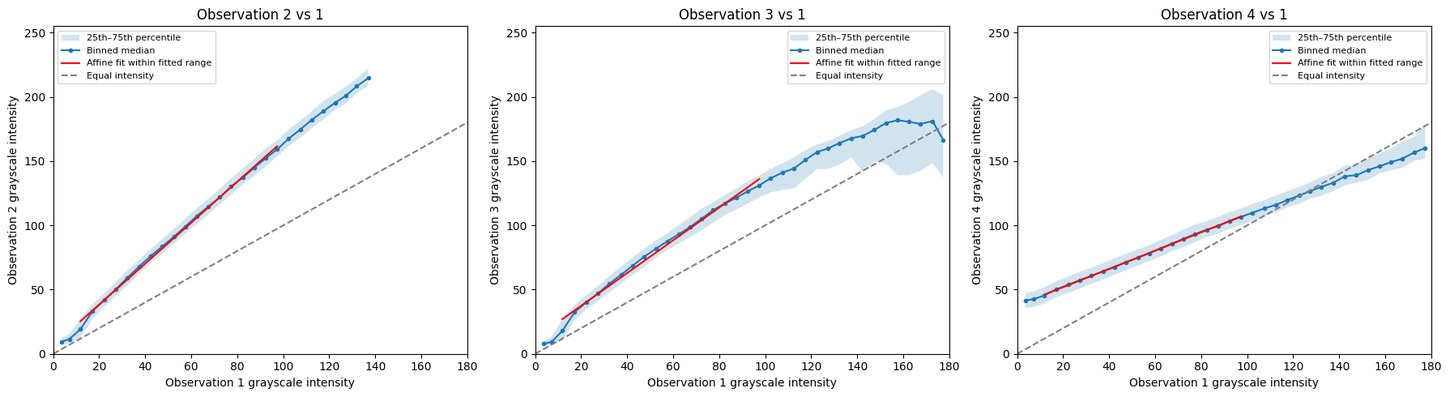

   observation  slope_a  offset_b  fitted_bin_MAE  number_of_fit_bins  \
0            2   1.5930    6.4744          1.3308                  18   
1            3   1.2733   11.9611          2.2737                  18   
2            4   0.7109   37.6985          0.2740                  18   

   eligible_pixel_percent  
0                 34.7028  
1                 34.0689  
2                 36.5386  

Diagnostic model: observation = a * observation_1 + b
No correction has been applied.
Bin-fit MAE is not reconstruction error or a noise estimate.


In [ ]:
# Q2 — Diagnose an affine intensity model using binned medians

reference_gray = q2_gray[0]
bin_edges = np.arange(0, 256, 5)
minimum_count = 100

q2_affine_diagnostics = []
q2_binned_relationships = {}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, observation_index in zip(axes, [1, 2, 3]):
    moving_gray = q2_gray[observation_index]

    # Exclude pixels with any channel at an endpoint in either image.
    valid = (
        np.all((q2_inputs[0] > 0) & (q2_inputs[0] < 255), axis=2)
        & np.all(
            (q2_inputs[observation_index] > 0)
            & (q2_inputs[observation_index] < 255),
            axis=2,
        )
    )

    bin_rows = []

    for lower, upper in zip(bin_edges[:-1], bin_edges[1:]):
        mask = (
            valid
            & (reference_gray >= lower)
            & (reference_gray < upper)
        )
        count = int(mask.sum())

        if count < minimum_count:
            continue

        x_values = reference_gray[mask]
        y_values = moving_gray[mask]

        bin_rows.append({
            "reference_median": float(np.median(x_values)),
            "observation_median": float(np.median(y_values)),
            "observation_p25": float(np.percentile(y_values, 25)),
            "observation_p75": float(np.percentile(y_values, 75)),
            "pixel_count": count,
        })

    bins = pd.DataFrame(bin_rows)

    # Use a moderate reference-intensity range for this diagnostic fit.
    fit_bins = bins[
        bins["reference_median"].between(10, 100)
    ]

    if len(fit_bins) < 3:
        raise ValueError(
            f"Insufficient bins for observation {observation_index + 1}."
        )

    x_fit = fit_bins["reference_median"].to_numpy()
    y_fit = fit_bins["observation_median"].to_numpy()

    design = np.column_stack([x_fit, np.ones_like(x_fit)])
    slope, intercept = np.linalg.lstsq(
        design, y_fit, rcond=None
    )[0]

    fitted_values = slope * x_fit + intercept
    bin_mae = np.mean(np.abs(y_fit - fitted_values))

    q2_affine_diagnostics.append({
        "observation": observation_index + 1,
        "slope_a": slope,
        "offset_b": intercept,
        "fitted_bin_MAE": bin_mae,
        "number_of_fit_bins": len(fit_bins),
        "eligible_pixel_percent": 100 * valid.mean(),
    })

    q2_binned_relationships[observation_index + 1] = bins

    x_all = bins["reference_median"].to_numpy()

    ax.fill_between(
        x_all,
        bins["observation_p25"].to_numpy(),
        bins["observation_p75"].to_numpy(),
        alpha=0.2,
        label="25th–75th percentile",
    )
    ax.plot(
        x_all,
        bins["observation_median"].to_numpy(),
        "o-",
        markersize=3,
        label="Binned median",
    )

    fit_line_x = np.linspace(x_fit.min(), x_fit.max(), 100)
    ax.plot(
        fit_line_x,
        slope * fit_line_x + intercept,
        color="red",
        label="Affine fit within fitted range",
    )

    ax.plot([0, 255], [0, 255], "--", color="gray", label="Equal intensity")
    ax.set_xlim(0, 180)
    ax.set_ylim(0, 255)
    ax.set_xlabel("Observation 1 grayscale intensity")
    ax.set_ylabel(f"Observation {observation_index + 1} grayscale intensity")
    ax.set_title(f"Observation {observation_index + 1} vs 1")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

q2_affine_summary = pd.DataFrame(q2_affine_diagnostics)
display(q2_affine_summary.round(4))

print("Diagnostic model: observation = a * observation_1 + b")
print("No correction has been applied.")
print("Bin-fit MAE is not reconstruction error or a noise estimate.")

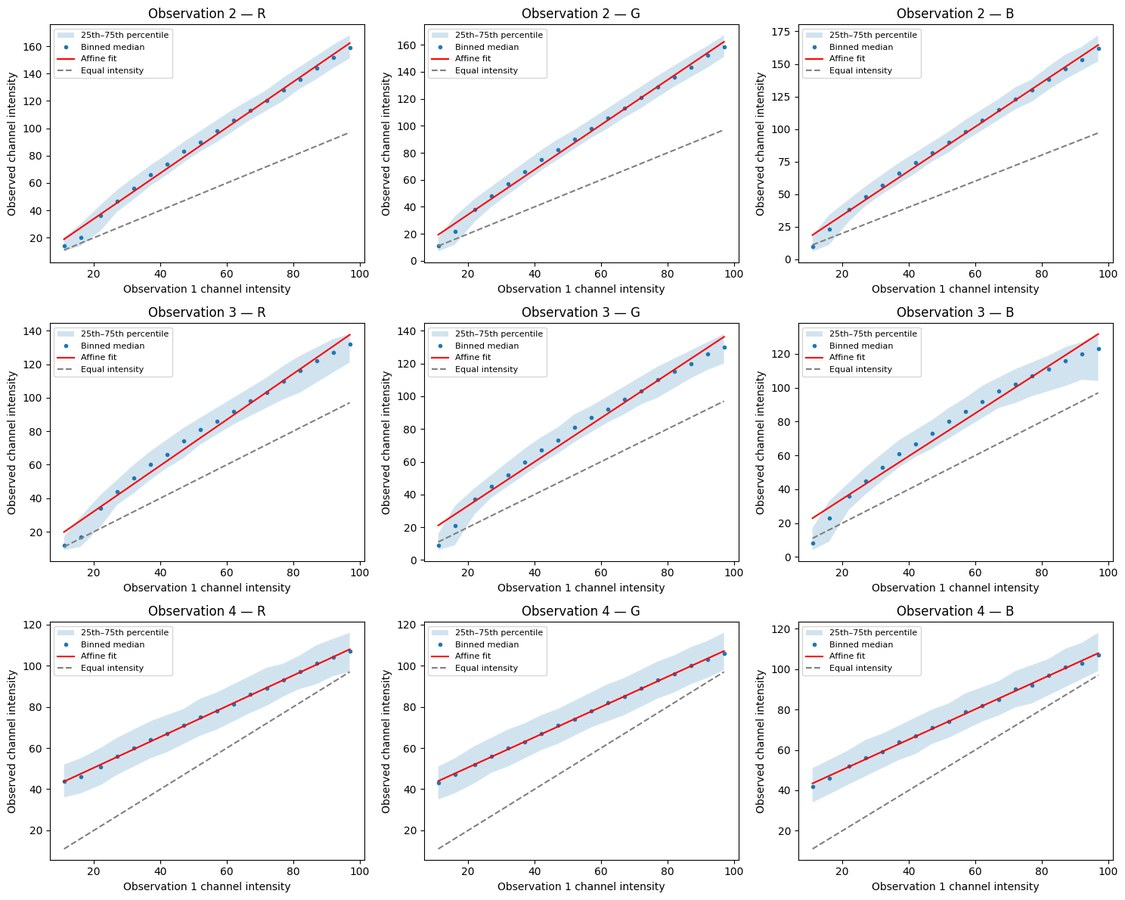

   observation channel  slope_a  offset_b  fitted_bin_MAE  fit_pixel_percent
0            2       R   1.6672    0.5461          2.5408            25.7147
1            2       G   1.6607    1.0944          2.6029            20.3636
2            2       B   1.6972   -0.0846          2.3886            17.0205
3            3       R   1.3687    4.7817          3.4463            26.0085
4            3       G   1.3389    6.4035          3.6533            20.4826
5            3       B   1.2662    8.9640          4.5675            16.8962
6            4       R   0.7472   35.5009          0.4843            26.0563
7            4       G   0.7344   35.8904          0.3984            20.7242
8            4       B   0.7496   35.1719          0.6910            17.4715

Models are stored in q2_rgb_affine_models.
Each model contains [slope, offset] for R, G, and B.
No correction has been applied.


In [ ]:
# Q2 — Estimate channel-wise affine relationships before correction

q2_rgb_affine_models = {}
rgb_fit_rows = []

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for row, observation_index in enumerate([1, 2, 3]):
    model = np.empty((3, 2), dtype=np.float64)

    for c, channel_name in enumerate(["R", "G", "B"]):
        reference_channel = q2_inputs[0][..., c].astype(np.float64)
        moving_channel = q2_inputs[observation_index][..., c].astype(
            np.float64
        )

        # Assess each channel separately and exclude endpoint values.
        valid = (
            (reference_channel > 0)
            & (reference_channel < 255)
            & (moving_channel > 0)
            & (moving_channel < 255)
        )

        bin_rows = []

        for lower in range(10, 100, 5):
            mask = (
                valid
                & (reference_channel >= lower)
                & (reference_channel < lower + 5)
            )
            count = int(mask.sum())

            if count < 100:
                continue

            values = moving_channel[mask]

            bin_rows.append({
                "x": float(np.median(reference_channel[mask])),
                "y": float(np.median(values)),
                "p25": float(np.percentile(values, 25)),
                "p75": float(np.percentile(values, 75)),
                "count": count,
            })

        bins = pd.DataFrame(bin_rows)

        if len(bins) < 3:
            raise ValueError(
                f"Insufficient bins for observation "
                f"{observation_index + 1}, channel {channel_name}."
            )

        x = bins["x"].to_numpy()
        y = bins["y"].to_numpy()

        design = np.column_stack([x, np.ones_like(x)])
        a, b = np.linalg.lstsq(design, y, rcond=None)[0]

        if not np.isfinite([a, b]).all() or a <= 0:
            raise ValueError("Invalid affine model.")

        model[c] = [a, b]

        rgb_fit_rows.append({
            "observation": observation_index + 1,
            "channel": channel_name,
            "slope_a": a,
            "offset_b": b,
            "fitted_bin_MAE": np.mean(np.abs(y - (a * x + b))),
            "fit_pixel_percent": (
                100 * bins["count"].sum() / reference_channel.size
            ),
        })

        ax = axes[row, c]
        ax.fill_between(
            x,
            bins["p25"].to_numpy(),
            bins["p75"].to_numpy(),
            alpha=0.2,
            label="25th–75th percentile",
        )
        ax.plot(x, y, "o", markersize=3, label="Binned median")
        ax.plot(x, a * x + b, color="red", label="Affine fit")
        ax.plot(x, x, "--", color="gray", label="Equal intensity")

        ax.set_title(
            f"Observation {observation_index + 1} — {channel_name}"
        )
        ax.set_xlabel("Observation 1 channel intensity")
        ax.set_ylabel("Observed channel intensity")
        ax.legend(fontsize=8)

    q2_rgb_affine_models[observation_index + 1] = model

plt.tight_layout()
plt.show()

q2_rgb_affine_summary = pd.DataFrame(rgb_fit_rows)
display(q2_rgb_affine_summary.round(4))

print("Models are stored in q2_rgb_affine_models.")
print("Each model contains [slope, offset] for R, G, and B.")
print("No correction has been applied.")

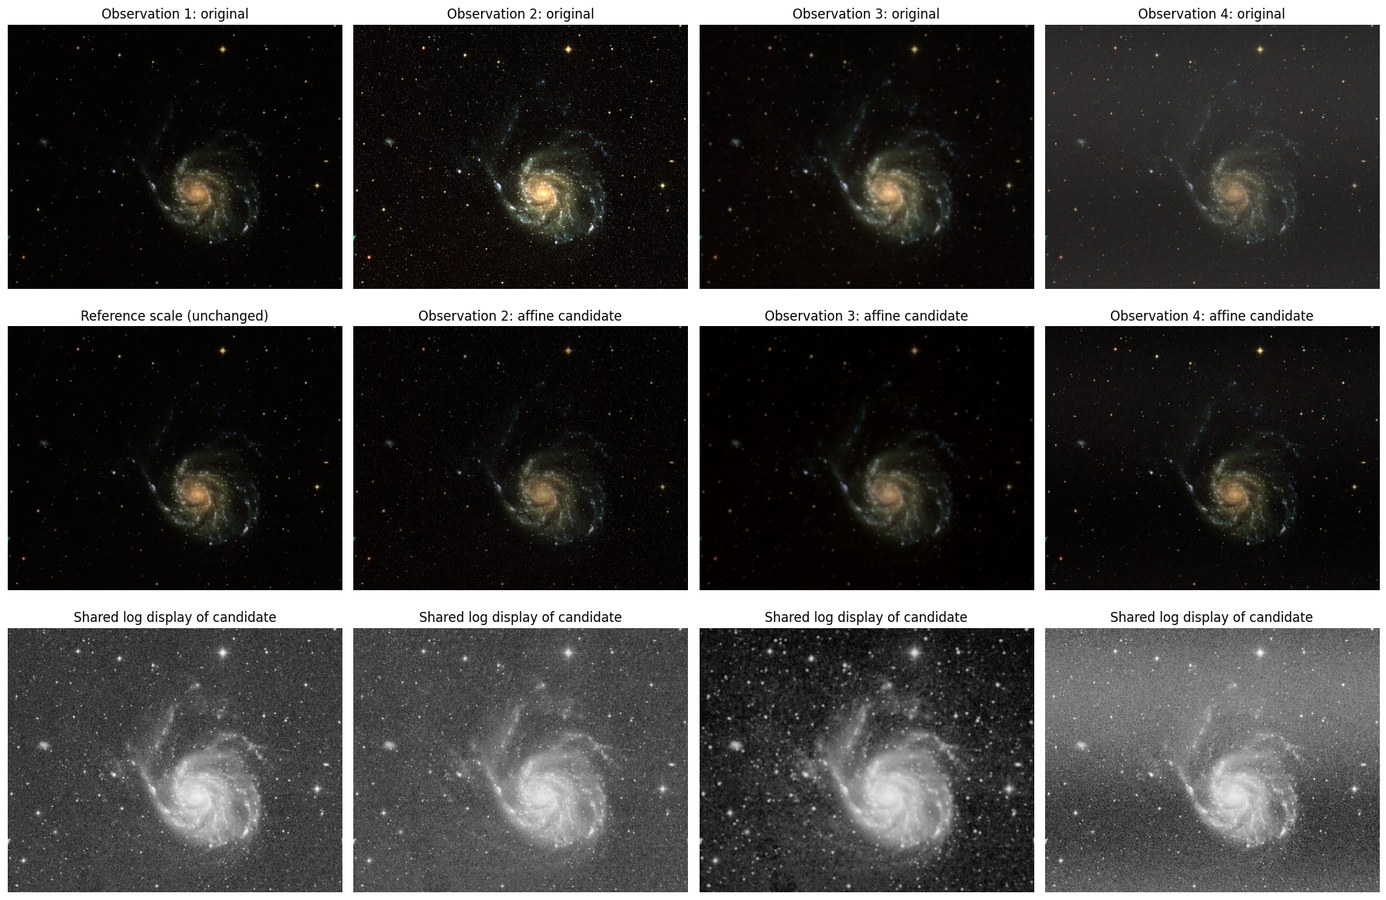

   observation channel  min_before_clipping  median_before_clipping  \
0            2       R              -0.3276                  6.8702   
1            2       G              -0.6590                  4.7605   
2            2       B               0.0498                  4.1744   
3            3       R              -3.4937                  4.5433   
4            3       G              -4.7829                  0.4455   
5            3       B              -7.0792                 -3.1305   
6            4       R             -47.5135                 11.3750   
7            4       G             -48.8707                  9.6809   
8            4       B             -46.9179                  7.7744   

   max_before_clipping  below_zero_percent  above_255_percent  
0             152.6252              1.0077             0.0000  
1             152.8930              4.7556             0.0000  
2             150.3006              0.0000             0.0000  
3             174.0508           

Candidates remain un-clipped floating-point arrays.
Observation 1 defines a provisional scale, not ground truth.
Observation 5 has not been corrected or discarded.
No final fusion has been performed.


In [ ]:
# Q2 — Apply candidate affine corrections without hiding out-of-range values

q2_affine_candidates = {
    1: q2_inputs[0].astype(np.float64).copy()
}
correction_rows = []

for observation_id in [2, 3, 4]:
    original = q2_inputs[observation_id - 1].astype(np.float64)
    model = q2_rgb_affine_models[observation_id]

    slopes = model[:, 0]
    offsets = model[:, 1]

    corrected = (
        original - offsets[None, None, :]
    ) / slopes[None, None, :]

    assert np.isfinite(corrected).all()
    q2_affine_candidates[observation_id] = corrected

    for c, channel_name in enumerate(["R", "G", "B"]):
        values = corrected[..., c]

        correction_rows.append({
            "observation": observation_id,
            "channel": channel_name,
            "min_before_clipping": values.min(),
            "median_before_clipping": np.median(values),
            "max_before_clipping": values.max(),
            "below_zero_percent": 100 * np.mean(values < 0),
            "above_255_percent": 100 * np.mean(values > 255),
        })

display(pd.DataFrame(correction_rows).round(4))

fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for col, observation_id in enumerate([1, 2, 3, 4]):
    original = q2_inputs[observation_id - 1]
    corrected = q2_affine_candidates[observation_id]

    # Clipping is for display only; stored candidates remain floating-point.
    display_rgb = np.clip(corrected, 0, 255) / 255.0

    display_gray = (
        np.clip(corrected, 0, 255)
        @ np.array([0.299, 0.587, 0.114])
    )
    display_log = np.log1p(display_gray) / np.log1p(255.0)

    axes[0, col].imshow(original)
    axes[0, col].set_title(f"Observation {observation_id}: original")

    axes[1, col].imshow(display_rgb)
    axes[1, col].set_title(
        "Reference scale (unchanged)"
        if observation_id == 1
        else f"Observation {observation_id}: affine candidate"
    )

    axes[2, col].imshow(
        display_log, cmap="gray", vmin=0, vmax=1
    )
    axes[2, col].set_title("Shared log display of candidate")

    for row in range(3):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

print("Candidates remain un-clipped floating-point arrays.")
print("Observation 1 defines a provisional scale, not ground truth.")
print("Observation 5 has not been corrected or discarded.")
print("No final fusion has been performed.")

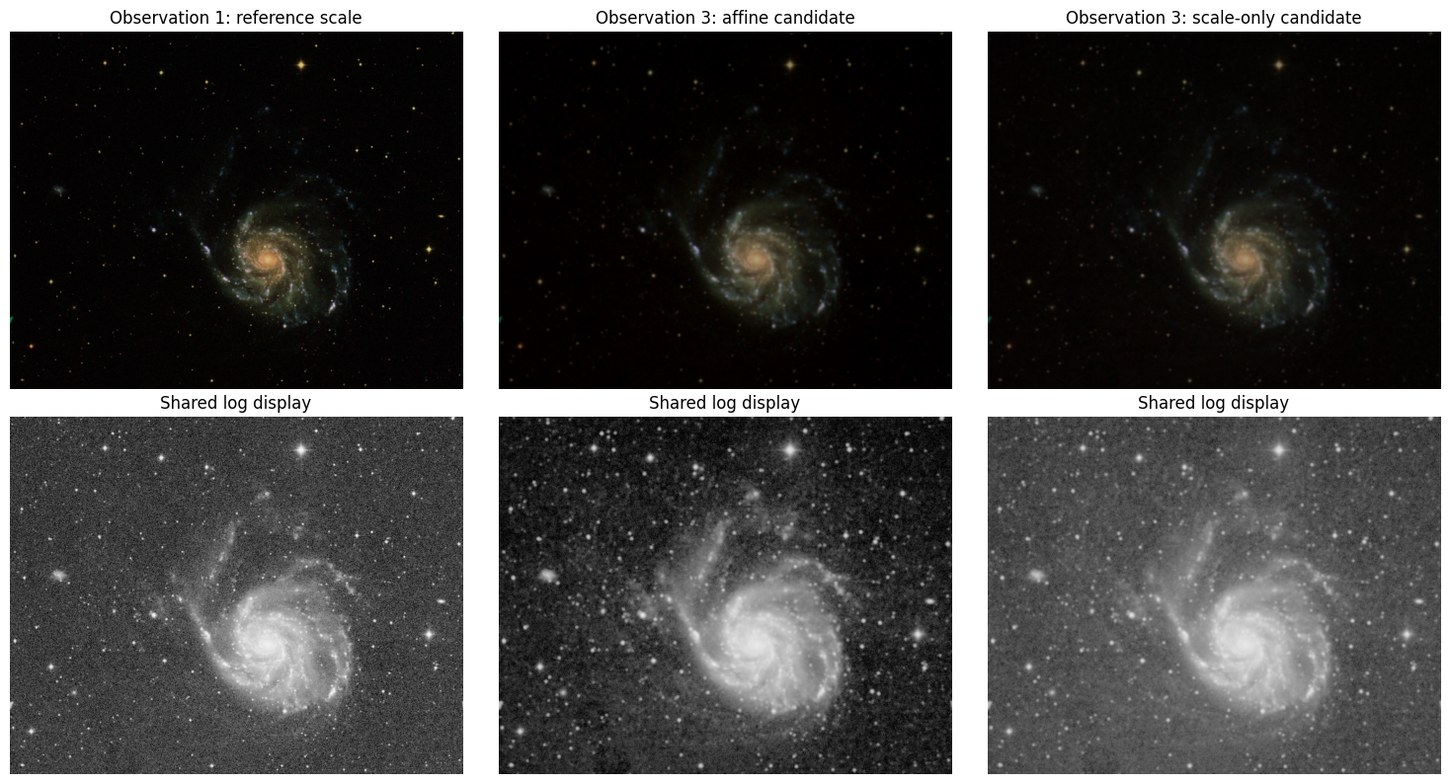

  channel  scale_only_slope  affine_bin_MAE  scale_only_bin_MAE
0       R            1.4401          3.4463              4.2317
1       G            1.4345          3.6533              4.7596
2       B            1.4002          4.5675              6.0658

Scale-only minimum by channel: [0. 0. 0.]
The affine candidate has not been overwritten.
Neither candidate corrects blur.


In [ ]:
# Q2 — Compare affine and scale-only correction for observation 3

scale_only_slopes = []
comparison_rows = []

for c, channel_name in enumerate(["R", "G", "B"]):
    x_image = q2_inputs[0][..., c].astype(np.float64)
    y_image = q2_inputs[2][..., c].astype(np.float64)

    valid = (
        (x_image > 0) & (x_image < 255)
        & (y_image > 0) & (y_image < 255)
    )

    x_points, y_points = [], []

    for lower in range(10, 100, 5):
        mask = valid & (x_image >= lower) & (x_image < lower + 5)

        if mask.sum() >= 100:
            x_points.append(np.median(x_image[mask]))
            y_points.append(np.median(y_image[mask]))

    x = np.asarray(x_points)
    y = np.asarray(y_points)

    assert len(x) >= 3

    # Least-squares slope with the intercept fixed at zero.
    slope = np.dot(x, y) / np.dot(x, x)
    assert np.isfinite(slope) and slope > 0

    scale_only_slopes.append(slope)

    affine_a, affine_b = q2_rgb_affine_models[3][c]

    comparison_rows.append({
        "channel": channel_name,
        "scale_only_slope": slope,
        "affine_bin_MAE": np.mean(
            np.abs(y - (affine_a * x + affine_b))
        ),
        "scale_only_bin_MAE": np.mean(
            np.abs(y - slope * x)
        ),
    })

q2_obs3_scale_only = (
    q2_inputs[2].astype(np.float64)
    / np.asarray(scale_only_slopes)[None, None, :]
)

display(pd.DataFrame(comparison_rows).round(4))

comparison_images = [
    ("Observation 1: reference scale",
     q2_inputs[0].astype(np.float64)),
    ("Observation 3: affine candidate",
     q2_affine_candidates[3]),
    ("Observation 3: scale-only candidate",
     q2_obs3_scale_only),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, (title, image) in enumerate(comparison_images):
    display_image = np.clip(image, 0, 255)

    axes[0, col].imshow(display_image / 255.0)
    axes[0, col].set_title(title)

    gray = display_image @ np.array([0.299, 0.587, 0.114])
    axes[1, col].imshow(
        np.log1p(gray) / np.log1p(255.0),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[1, col].set_title("Shared log display")

    for row in range(2):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

print("Scale-only minimum by channel:",
      q2_obs3_scale_only.min(axis=(0, 1)))
print("The affine candidate has not been overwritten.")
print("Neither candidate corrects blur.")

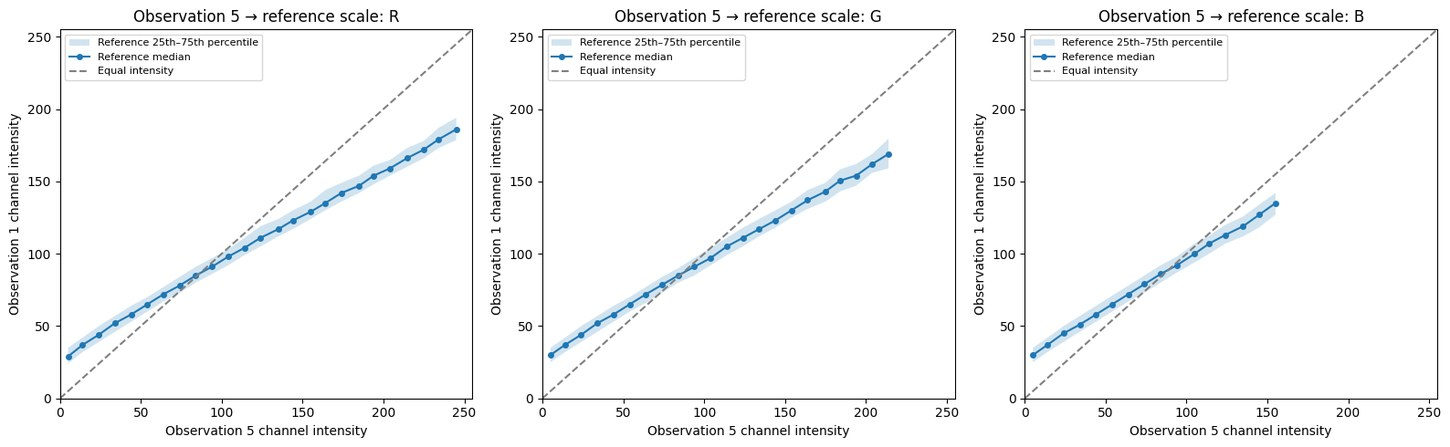

  channel  eligible_pixel_percent  retained_bin_count  \
0       R                  5.6146                  25   
1       G                  5.8707                  22   
2       B                  4.5240                  16   

   pixels_in_retained_bins  lowest_bin_median  highest_bin_median  
0                    46470                5.0               245.0  
1                    48444                5.0               214.0  
2                    37034                5.0               155.0  

Zero and saturated channel values were excluded.
Values from 250 to 254 were not included in the mapping bins.
No mapping has been applied to observation 5.
Observation 1 remains a provisional reference, not ground truth.


In [ ]:
# Q2 — Inspect the usable intensity mapping of observation 5

# Record the provisional scale-only choice for observation 3.
q2_working_candidates = {
    1: q2_affine_candidates[1].copy(),
    2: q2_affine_candidates[2].copy(),
    3: q2_obs3_scale_only.copy(),
    4: q2_affine_candidates[4].copy(),
}

q2_obs5_mapping_bins = {}
summary_rows = []

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for c, channel_name in enumerate(["R", "G", "B"]):
    observed = q2_inputs[4][..., c].astype(np.float64)
    reference = q2_inputs[0][..., c].astype(np.float64)

    # Endpoint exclusion is a screening rule, not proof of reliability.
    valid = (
        (observed > 0) & (observed < 255)
        & (reference > 0) & (reference < 255)
    )

    rows = []

    for lower in range(0, 250, 10):
        upper = lower + 10

        mask = (
            valid
            & (observed >= lower)
            & (observed < upper)
        )
        count = int(mask.sum())

        if count < 100:
            continue

        reference_values = reference[mask]

        rows.append({
            "observed_median": float(np.median(observed[mask])),
            "reference_median": float(np.median(reference_values)),
            "reference_p25": float(
                np.percentile(reference_values, 25)
            ),
            "reference_p75": float(
                np.percentile(reference_values, 75)
            ),
            "pixel_count": count,
        })

    bins = pd.DataFrame(rows)

    if len(bins) < 3:
        raise ValueError(
            f"Insufficient mapping bins for channel {channel_name}."
        )

    q2_obs5_mapping_bins[channel_name] = bins

    summary_rows.append({
        "channel": channel_name,
        "eligible_pixel_percent": 100 * valid.mean(),
        "retained_bin_count": len(bins),
        "pixels_in_retained_bins": int(bins["pixel_count"].sum()),
        "lowest_bin_median": bins["observed_median"].min(),
        "highest_bin_median": bins["observed_median"].max(),
    })

    x = bins["observed_median"].to_numpy()

    axes[c].fill_between(
        x,
        bins["reference_p25"].to_numpy(),
        bins["reference_p75"].to_numpy(),
        alpha=0.2,
        label="Reference 25th–75th percentile",
    )
    axes[c].plot(
        x,
        bins["reference_median"].to_numpy(),
        "o-",
        markersize=4,
        label="Reference median",
    )
    axes[c].plot(
        [0, 255], [0, 255],
        "--", color="gray", label="Equal intensity",
    )

    axes[c].set_xlim(0, 255)
    axes[c].set_ylim(0, 255)
    axes[c].set_title(f"Observation 5 → reference scale: {channel_name}")
    axes[c].set_xlabel("Observation 5 channel intensity")
    axes[c].set_ylabel("Observation 1 channel intensity")
    axes[c].legend(fontsize=8)

plt.tight_layout()
plt.show()

display(pd.DataFrame(summary_rows).round(4))

print("Zero and saturated channel values were excluded.")
print("Values from 250 to 254 were not included in the mapping bins.")
print("No mapping has been applied to observation 5.")
print("Observation 1 remains a provisional reference, not ground truth.")

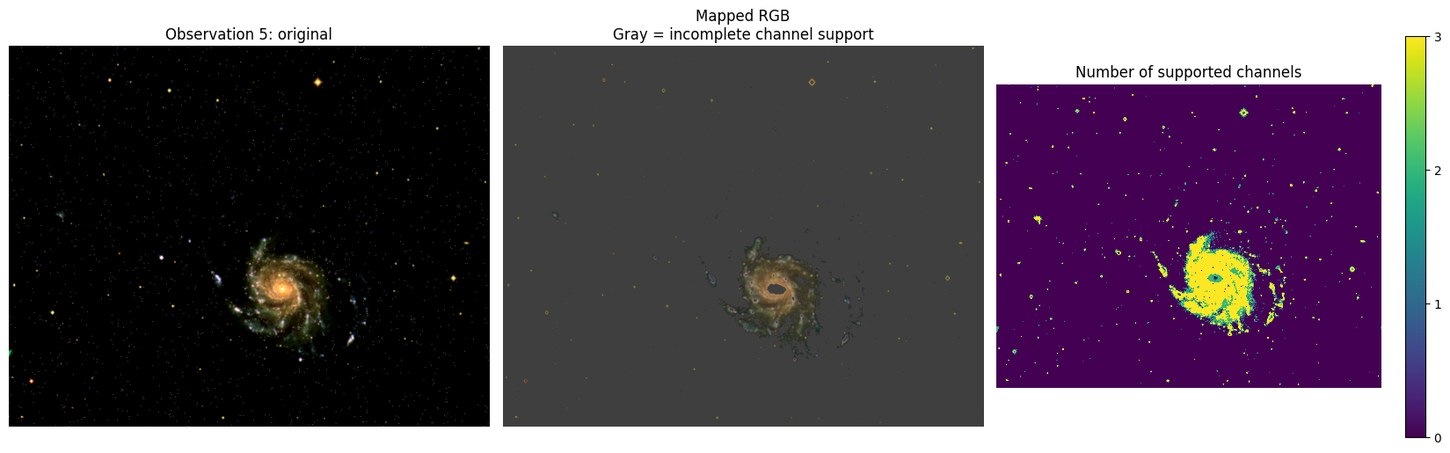

  channel  supported_min  supported_max  mapped_pixel_percent
0       R            5.0          245.0                5.1186
1       G            5.0          214.0                5.3467
2       B            5.0          155.0                4.0020

Pixels with all three channels supported: 3.6790%
Unsupported channel estimates remain NaN.
Validity indicates mapping support, not guaranteed accuracy.
No final fusion has been performed.


In [ ]:
# Q2 — Map observation 5 only within supported intensity ranges

obs5 = q2_inputs[4].astype(np.float64)

q2_obs5_mapped = np.full(obs5.shape, np.nan, dtype=np.float64)
q2_obs5_valid = np.zeros(obs5.shape, dtype=bool)

coverage_rows = []

for c, channel_name in enumerate(["R", "G", "B"]):
    bins = q2_obs5_mapping_bins[channel_name].sort_values(
        "observed_median"
    )

    x = bins["observed_median"].to_numpy()
    y = bins["reference_median"].to_numpy()

    assert np.all(np.diff(x) > 0)
    assert np.all(np.diff(y) >= 0), (
        f"Non-monotonic mapping for {channel_name}; inspect before use."
    )

    channel = obs5[..., c]

    valid = (
        (channel > 0)
        & (channel < 255)
        & (channel >= x[0])
        & (channel <= x[-1])
    )

    # Interpolate only supported values; do not extrapolate.
    q2_obs5_mapped[..., c][valid] = np.interp(
        channel[valid], x, y
    )
    q2_obs5_valid[..., c] = valid

    coverage_rows.append({
        "channel": channel_name,
        "supported_min": x[0],
        "supported_max": x[-1],
        "mapped_pixel_percent": 100 * valid.mean(),
    })

q2_working_candidates[5] = q2_obs5_mapped

display(pd.DataFrame(coverage_rows).round(4))

# A complete RGB display requires all three channels to be valid.
all_channels_valid = q2_obs5_valid.all(axis=2)

# Gray is a display placeholder, not reconstructed image content.
masked_preview = np.full(obs5.shape, 0.25, dtype=np.float64)
masked_preview[all_channels_valid] = (
    np.clip(q2_obs5_mapped[all_channels_valid], 0, 255) / 255.0
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].imshow(q2_inputs[4])
axes[0].set_title("Observation 5: original")

axes[1].imshow(masked_preview)
axes[1].set_title("Mapped RGB\nGray = incomplete channel support")

mask_plot = axes[2].imshow(
    q2_obs5_valid.sum(axis=2),
    cmap="viridis",
    vmin=0,
    vmax=3,
    interpolation="nearest",
)
axes[2].set_title("Number of supported channels")
fig.colorbar(mask_plot, ax=axes[2], ticks=[0, 1, 2, 3])

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print(
    "Pixels with all three channels supported:",
    f"{100 * all_channels_valid.mean():.4f}%",
)
print("Unsupported channel estimates remain NaN.")
print("Validity indicates mapping support, not guaranteed accuracy.")
print("No final fusion has been performed.")

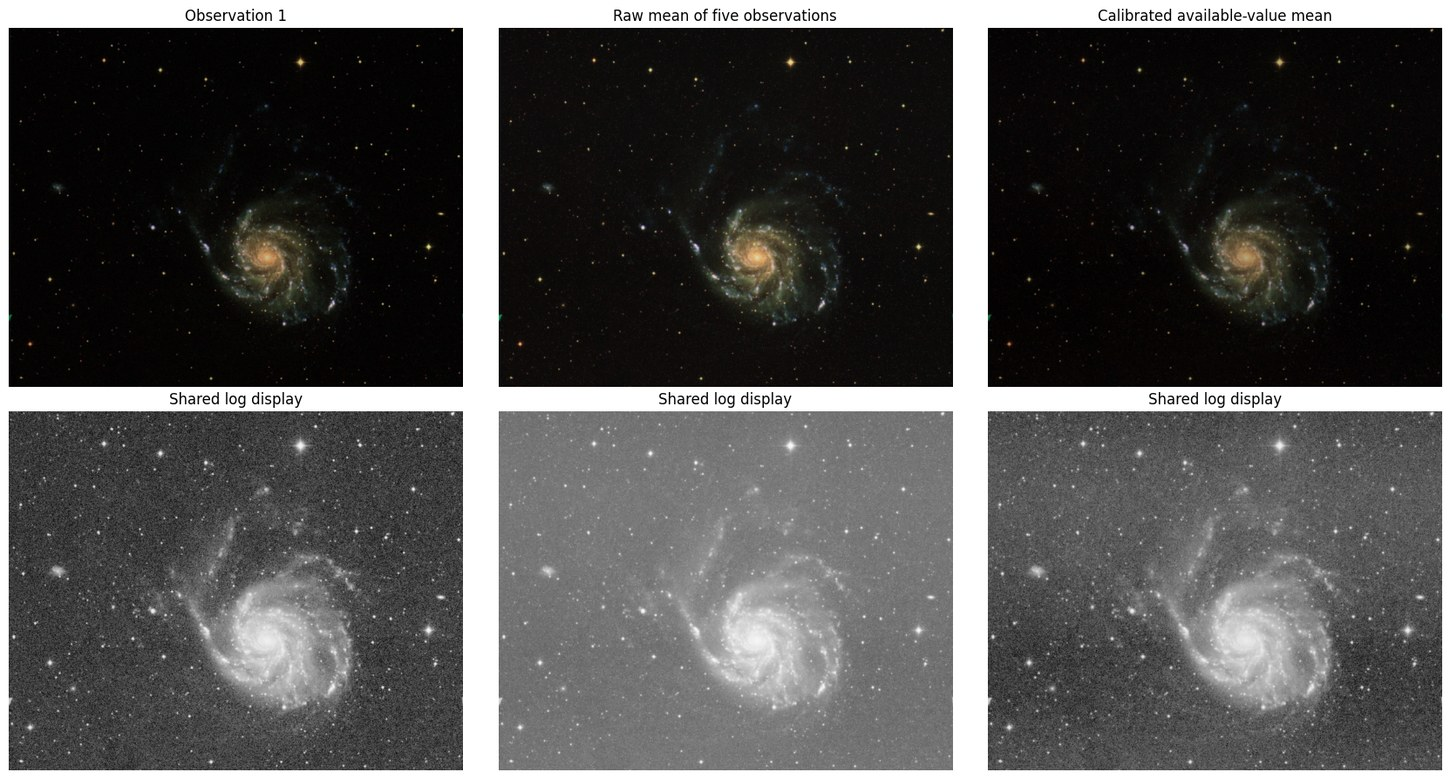

                            method  mean_gray_before_clipping  \
0                    Observation 1                     8.3517   
1    Raw mean of five observations                    17.7805   
2  Calibrated available-value mean                    10.1842   

   median_gray_before_clipping  negative_channel_value_percent  \
0                       4.1200                          0.0000   
1                      12.8326                          0.0000   
2                       6.1823                         10.1291   

   above_255_channel_value_percent  
0                              0.0  
1                              0.0  
2                              0.0  

   observation  mean_weight_percent
0            1              24.7589
1            2              24.7589
2            3              24.7589
3            4              24.7589
4            5               0.9645

Both fusion results remain un-clipped floating-point arrays.
Equal available weights are a baseline, not quality-based weights.
q2_final has not been assigned.


In [ ]:
# Q2 — Compare raw averaging with calibrated available-value averaging

raw_stack = np.stack(q2_inputs).astype(np.float64)
q2_raw_mean = raw_stack.mean(axis=0)

candidate_stack = np.stack([
    q2_working_candidates[i]
    for i in range(1, 6)
])

available = np.isfinite(candidate_stack)
available_count = available.sum(axis=0)

assert np.all(available_count > 0)

# Replace missing estimates with zero only in the numerator.
# The denominator counts available estimates, not all five observations.
candidate_sum = np.where(
    available, candidate_stack, 0.0
).sum(axis=0)

q2_calibrated_mean = candidate_sum / available_count

assert q2_calibrated_mean.shape == (810, 1024, 3)
assert np.isfinite(q2_calibrated_mean).all()

# Keep floating-point results without clipping for later analysis.
comparison_versions = [
    ("Observation 1", q2_inputs[0].astype(np.float64)),
    ("Raw mean of five observations", q2_raw_mean),
    ("Calibrated available-value mean", q2_calibrated_mean),
]

summary_rows = []

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for col, (name, image) in enumerate(comparison_versions):
    gray = image @ np.array([0.299, 0.587, 0.114])

    summary_rows.append({
        "method": name,
        "mean_gray_before_clipping": gray.mean(),
        "median_gray_before_clipping": np.median(gray),
        "negative_channel_value_percent": 100 * np.mean(image < 0),
        "above_255_channel_value_percent": 100 * np.mean(image > 255),
    })

    # Clip only for display.
    display_rgb = np.clip(image, 0, 255)
    display_gray = display_rgb @ np.array([0.299, 0.587, 0.114])

    axes[0, col].imshow(display_rgb / 255.0)
    axes[0, col].set_title(name)

    axes[1, col].imshow(
        np.log1p(display_gray) / np.log1p(255.0),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[1, col].set_title("Shared log display")

    for row in range(2):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

display(pd.DataFrame(summary_rows).round(4))

# Report the average normalized contribution across pixels and channels.
mean_contributions = (
    available.astype(np.float64) / available_count[None, ...]
).mean(axis=(1, 2, 3))

display(pd.DataFrame({
    "observation": np.arange(1, 6),
    "mean_weight_percent": 100 * mean_contributions,
}).round(4))

assert np.isclose(mean_contributions.sum(), 1.0)

print("Both fusion results remain un-clipped floating-point arrays.")
print("Equal available weights are a baseline, not quality-based weights.")
print("q2_final has not been assigned.")

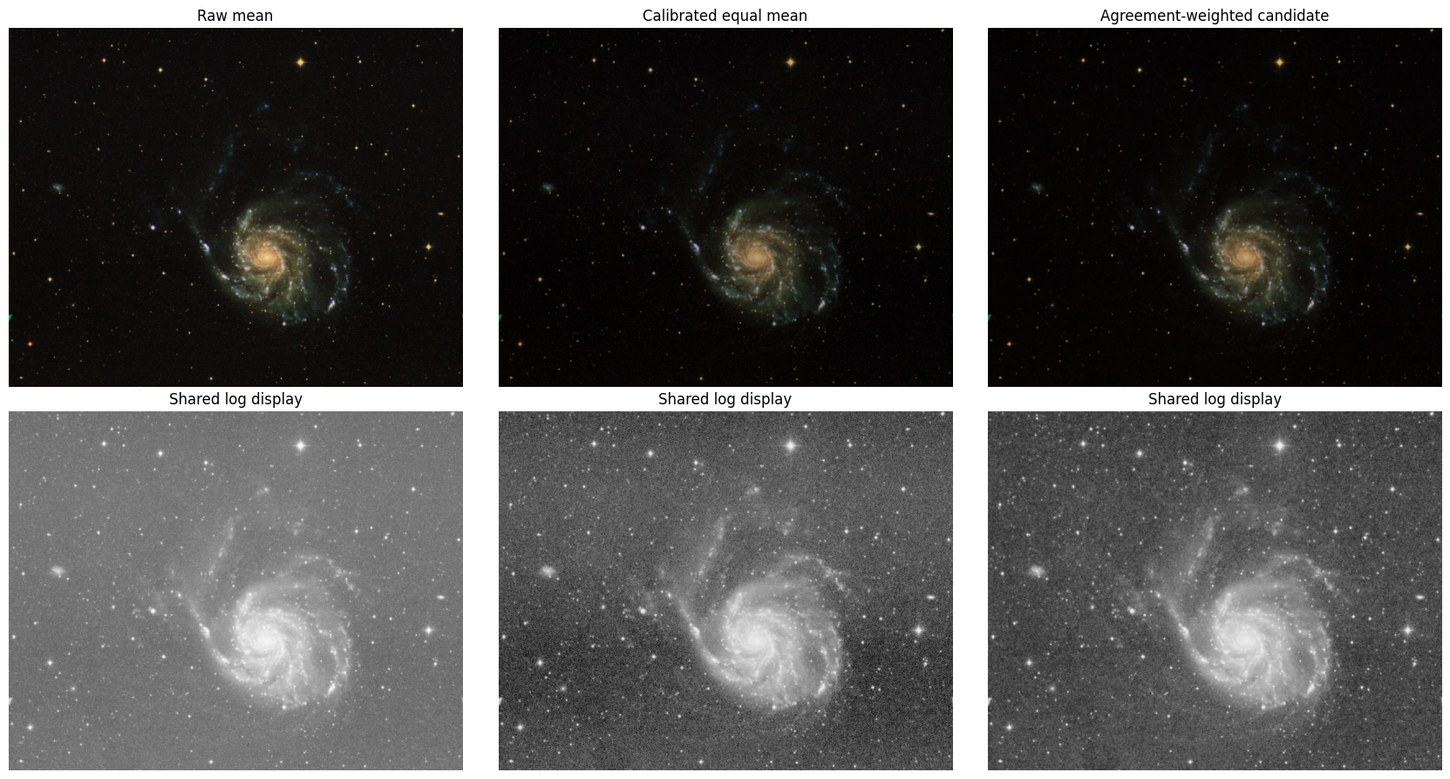

                         method  negative_channel_percent  \
0                      Raw mean                    0.0000   
1         Calibrated equal mean                   10.1291   
2  Agreement-weighted candidate                    0.5299   

   above_255_channel_percent  
0                        0.0  
1                        0.0  
2                        0.0  

   observation  mean_weight_percent
0            1              27.1596
1            2              29.6306
2            3              29.1508
3            4              12.9578
4            5               1.1012

Fallback channel-value percentage: 0.000000%
Weights measure agreement, not verified image quality.
q2_final has not been assigned.


In [ ]:
# Q2 — Compare equal averaging with agreement-weighted fusion

fusion_stack = np.stack([
    q2_working_candidates[i] for i in range(1, 6)
]).copy()

valid = np.isfinite(fusion_stack)

# Exclude original saturated channel values.
# Keep negative calibrated values during estimation.
for i in range(5):
    valid[i] &= q2_inputs[i] < 255

masked_stack = np.where(valid, fusion_stack, np.nan)

# Fall back to observation 1 only where every estimate is unavailable.
has_support = valid.any(axis=0)
masked_stack[0] = np.where(
    has_support,
    masked_stack[0],
    q2_inputs[0].astype(np.float64),
)

center = np.nanmedian(masked_stack, axis=0)
absolute_deviation = np.abs(masked_stack - center[None, ...])
mad = np.nanmedian(absolute_deviation, axis=0)

# A one-level floor prevents division by zero.
# This is an agreement scale, not a measured noise standard deviation.
agreement_scale = np.maximum(mad, 1.0)
tolerance = 2.5 * agreement_scale

residual = np.where(
    valid,
    np.abs(fusion_stack - center[None, ...]),
    0.0,
)

weights = np.where(
    valid,
    1.0 / (1.0 + (residual / tolerance[None, ...]) ** 2),
    0.0,
)

weight_sum = weights.sum(axis=0)
safe_values = np.where(valid, fusion_stack, 0.0)

q2_robust_candidate = np.divide(
    (weights * safe_values).sum(axis=0),
    weight_sum,
    out=q2_inputs[0].astype(np.float64).copy(),
    where=weight_sum > 0,
)

assert np.isfinite(q2_robust_candidate).all()

normalized_weights = np.divide(
    weights,
    weight_sum[None, ...],
    out=np.zeros_like(weights),
    where=weight_sum[None, ...] > 0,
)

versions = [
    ("Raw mean", q2_raw_mean),
    ("Calibrated equal mean", q2_calibrated_mean),
    ("Agreement-weighted candidate", q2_robust_candidate),
]

rows = []
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for col, (name, image) in enumerate(versions):
    rows.append({
        "method": name,
        "negative_channel_percent": 100 * np.mean(image < 0),
        "above_255_channel_percent": 100 * np.mean(image > 255),
    })

    shown = np.clip(image, 0, 255)
    gray = shown @ np.array([0.299, 0.587, 0.114])

    axes[0, col].imshow(shown / 255.0)
    axes[0, col].set_title(name)

    axes[1, col].imshow(
        np.log1p(gray) / np.log1p(255.0),
        cmap="gray", vmin=0, vmax=1,
    )
    axes[1, col].set_title("Shared log display")

    for row in range(2):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

display(pd.DataFrame(rows).round(4))

display(pd.DataFrame({
    "observation": np.arange(1, 6),
    "mean_weight_percent": (
        100 * normalized_weights.mean(axis=(1, 2, 3))
    ),
}).round(4))

print(
    "Fallback channel-value percentage:",
    f"{100 * np.mean(weight_sum == 0):.6f}%",
)
print("Weights measure agreement, not verified image quality.")
print("q2_final has not been assigned.")

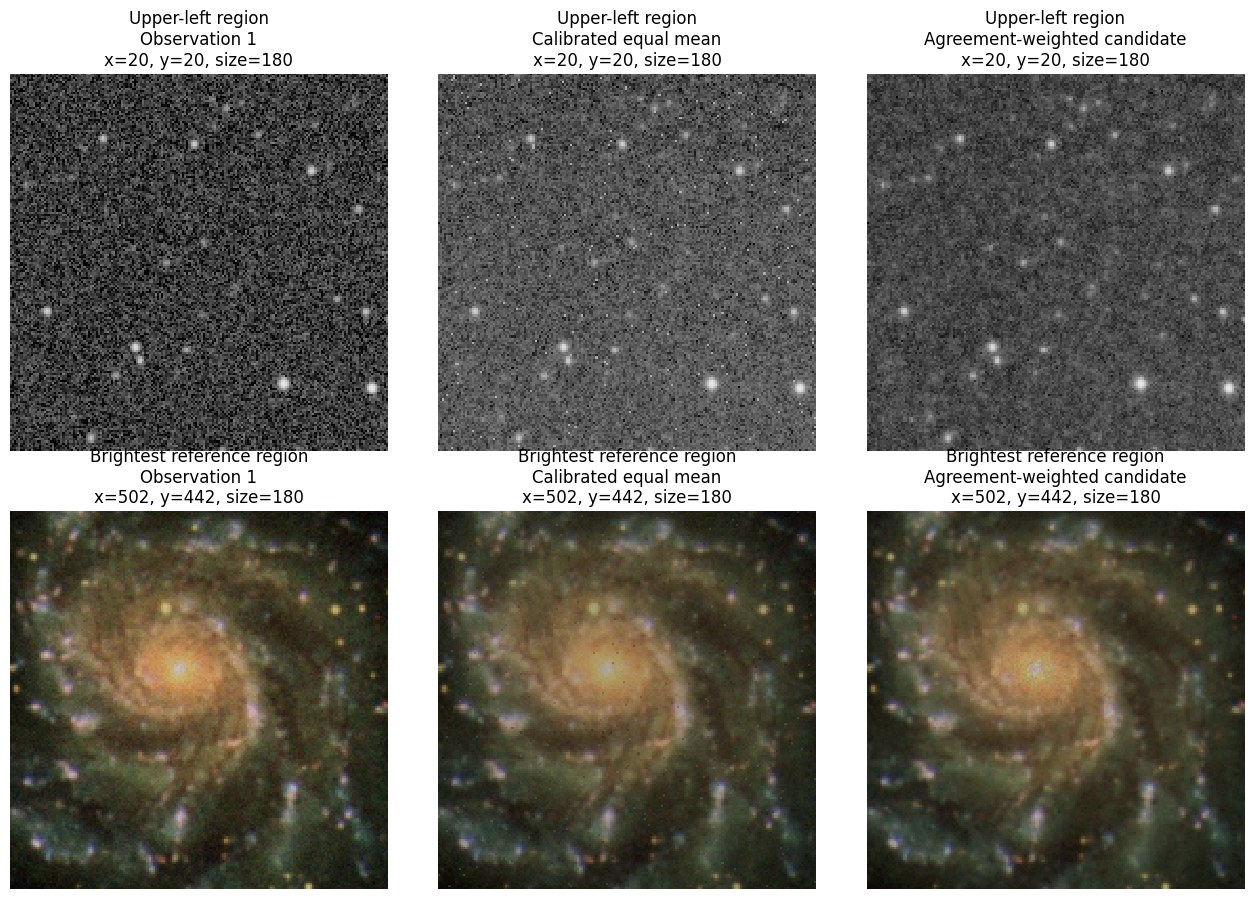

Top row: shared log grayscale display.
Bottom row: RGB display.
The upper-left region is not assumed to be noise-only.
No reconstruction values were changed.


In [ ]:
# Q2 — Inspect local structure before selecting the final reconstruction

height, width = q2_gray[0].shape
patch_size = 180

# Find the brightest 180 x 180 region in observation 1.
reference_gray = q2_gray[0]
integral = np.pad(
    reference_gray, ((1, 0), (1, 0)), mode="constant"
).cumsum(axis=0).cumsum(axis=1)

window_sums = (
    integral[patch_size:, patch_size:]
    - integral[:-patch_size, patch_size:]
    - integral[patch_size:, :-patch_size]
    + integral[:-patch_size, :-patch_size]
)

bright_y, bright_x = np.unravel_index(
    np.argmax(window_sums), window_sums.shape
)

regions = [
    ("Upper-left region", 20, 20),
    ("Brightest reference region", int(bright_x), int(bright_y)),
]

methods = [
    ("Observation 1", q2_inputs[0].astype(np.float64)),
    ("Calibrated equal mean", q2_calibrated_mean),
    ("Agreement-weighted candidate", q2_robust_candidate),
]

fig, axes = plt.subplots(2, 3, figsize=(13, 9))

for row, (region_name, x0, y0) in enumerate(regions):
    for col, (method_name, image) in enumerate(methods):
        crop = image[
            y0:y0 + patch_size,
            x0:x0 + patch_size,
        ]
        shown = np.clip(crop, 0, 255)

        if row == 0:
            # Shared log display reveals low-intensity variation.
            gray = shown @ np.array([0.299, 0.587, 0.114])
            axes[row, col].imshow(
                np.log1p(gray) / np.log1p(255.0),
                cmap="gray",
                vmin=0,
                vmax=1,
                interpolation="nearest",
            )
        else:
            axes[row, col].imshow(
                shown / 255.0,
                interpolation="nearest",
            )

        axes[row, col].set_title(
            f"{region_name}\n{method_name}\n"
            f"x={x0}, y={y0}, size={patch_size}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

print("Top row: shared log grayscale display.")
print("Bottom row: RGB display.")
print("The upper-left region is not assumed to be noise-only.")
print("No reconstruction values were changed.")

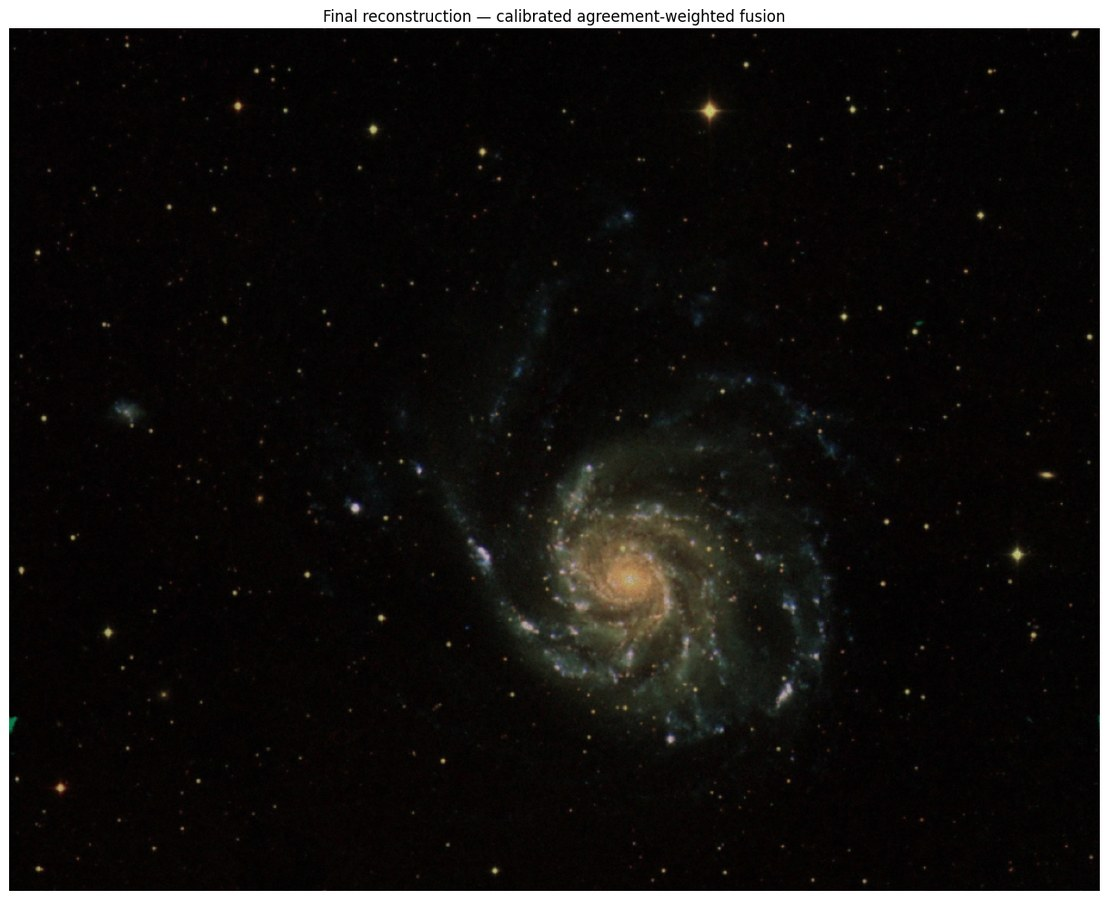

   observation  mean_weight_percent
0            1              27.1596
1            2              29.6306
2            3              29.1508
3            4              12.9578
4            5               1.1012

In [ ]:
# Q2 — Final reconstruction and output verification

assert q2_robust_candidate.shape == (810, 1024, 3)
assert np.isfinite(q2_robust_candidate).all()

# Convert to 8-bit RGB only after floating-point fusion is complete.
q2_final = np.clip(
    np.rint(q2_robust_candidate), 0, 255
).astype(np.uint8)

output_path = RESULTS / "q2" / "restored.png"
output_path.parent.mkdir(parents=True, exist_ok=True)
Image.fromarray(q2_final).save(output_path)

# Display the final result directly in the notebook.
fig, ax = plt.subplots(figsize=(13, 10))
ax.imshow(q2_final)
ax.set_title("Final reconstruction — calibrated agreement-weighted fusion")
ax.axis("off")
plt.tight_layout()
plt.show()

# Document the contribution of each observation.
q2_final_contributions = pd.DataFrame({
    "observation": np.arange(1, 6),
    "mean_weight_percent": (
        100 * normalized_weights.mean(axis=(1, 2, 3))
    ),
})
display(q2_final_contributions.round(4))

# Verify the actual saved file.
with Image.open(output_path) as saved:
    assert saved.size == (1024, 810)
    assert saved.mode == "RGB"
    assert np.array_equal(np.asarray(saved), q2_final)

print("Final array shape:", q2_final.shape)
print("Final data type:", q2_final.dtype)
print(
    "Negative channel values before rounding/clipping:",
    f"{100 * np.mean(q2_robust_candidate < 0):.4f}%",
)
print(
    "Channel values above 255 before rounding/clipping:",
    f"{100 * np.mean(q2_robust_candidate > 255):.4f}%",
)
print("Saved PNG matches the final array: True")
print("Final image saved to:", output_path)

### Q2 — Method, Results, and Limitations

#### Observation analysis

The five RGB observations have identical dimensions of 1024 × 810
pixels, but differ in intensity, apparent blur, and background variation.

Observation 1 is relatively dark. Observation 2 contains stronger
intensities and some saturated channel values. Observation 3 shows
broader point-like features, suggesting blur. Observation 4 has an
elevated background and substantial pixel variation. Approximately
93.41% of the pixels in Observation 5 are zero in all three channels,
so its dark regions cannot be treated as reliable zero-valued estimates
of the clean scene.

Original RGB images and a shared logarithmic grayscale display were
used for inspection. The logarithmic transform was used only for
visualization, not for reconstruction.

#### Geometric consistency

Normalized cross-correlation was used to screen for integer
translations within ±8 pixels relative to Observation 1. Observations
2, 3, and 4 had their highest sampled correlation at zero displacement.

The initial subsampled test suggested a one-pixel vertical offset for
Observation 5. This candidate was checked using all pixels within the
full interior and four quadrants, with Observations 1 and 2 as separate
references. All ten checks favored zero displacement, and the proposed
offset reduced correlation.

No spatial transformation was therefore applied. These tests support
retaining the original coordinates for this reconstruction, but do not
exclude subpixel displacement, rotation, or local geometric differences.

#### Intensity calibration

Observation 1 defined a provisional common intensity scale; it was not
treated as ground truth.

For Observations 2 and 4, channel-wise affine models were estimated
from binned median relationships over reference intensities from 10
to 100, excluding endpoint values. If an observed channel is modeled
as y = ax + b, the calibrated estimate is (y - b) / a.

An affine model was also tested for Observation 3. However, applying
its fitted offsets to dark pixels produced negative values in
approximately 41.95% of the green channel and 71.94% of the blue
channel. A scale-only model was selected instead. Although its
in-range fitting error was higher, it avoided subtracting an
insufficiently supported global offset from the dark regions.
Neither correction removes blur.

For Observation 5, channel-wise mappings were constructed from
paired observations at the same coordinates using binned reference
medians and piecewise linear interpolation. Mapping was restricted
to the supported intensity ranges: 5–245 for R, 5–214 for G, and
5–155 for B. Zero values, saturated values, and unsupported ranges
were excluded rather than extrapolated. Unsupported estimates were
stored as NaN and did not contribute to fusion.

#### Agreement-weighted fusion

Two baselines were compared: the raw mean of all five observations,
and an equal-weight mean of available calibrated estimates.

The selected method uses spatially varying, channel-wise agreement
weights. Original saturated channel values are excluded. At each
pixel and channel, the median of available calibrated estimates is
used as a provisional center, m.

The agreement scale is:

s = max(median(|z_i - m|), 1)

For each available estimate z_i, its unnormalized weight is:

w_i = 1 / (1 + (|z_i - m| / (2.5s))^2)

The reconstruction is the weighted sum divided by the sum of weights.
Thus, estimates farther from the local consensus receive less weight.
The scale floor prevents division by zero; it is not a measured noise
standard deviation. The factor 2.5 was a heuristic choice, not a
ground-truth-optimized parameter.

All processing was performed in floating point. Rounding and clipping
to [0, 255] were applied only when creating the final uint8 image.

#### Results and selection

The raw mean retained an elevated background. Calibration reduced
this effect, but the calibrated equal-weight mean still contained
negative channel values and visible background irregularities.

The selected candidate reduced the percentage of negative channel
values before output conversion from 10.1291% to 0.5299%. No channel
values exceeded 255 in the selected result. These are range diagnostics,
not reconstruction accuracy scores. The selected candidate differs
from the calibrated equal mean in both saturation handling and
agreement weighting, so the change cannot be attributed to weighting
alone.

Average normalized contributions across all pixels and channels were:

| Observation | Mean weight (%) |
|---|---:|
| 1 | 27.1596 |
| 2 | 29.6306 |
| 3 | 29.1508 |
| 4 | 12.9578 |
| 5 | 1.1012 |

All five observations contributed. Observation 5 contributed only
within its supported regions, explaining its smaller global average
weight. Weight percentages document participation, not proof that
each observation improves reconstruction accuracy. No fallback was
required.

Identical local crops were compared using shared display settings.
The selected result showed reduced fine background fluctuations
relative to Observation 1 and fewer isolated dark artifacts than the
calibrated equal mean. The galaxy's broad spiral structure remained
visible, although soft detail and background mottling remained.

#### Limitations

The intensity scale is anchored to a degraded observation, so absolute
brightness and color accuracy are uncertain. Calibration models are
approximate and may be less reliable outside their fitted ranges.
The Observation 5 mapping is also derived from degraded paired data,
not independently validated against a clean reference.

Agreement does not necessarily imply correctness: several observations
can share a bias or blur, and a valid feature appearing strongly in only
one observation may be downweighted. Independent channel weights may
also affect color consistency. The method does not explicitly recover
blurred detail, and remaining background variation is visible.

The clean image is unavailable, so reconstruction PSNR and SSIM were
not computed. Visual comparisons, calibration diagnostics, and
contribution statistics support the design choices but do not establish
optimal recovery of the hidden clean image.

#### Final output

The final reconstruction is displayed in the notebook and saved as
`restored.png`. It has dimensions of 1024 × 810 pixels and uses RGB
uint8 format. Reloading the saved PNG confirmed exact equality with
the final array.

## Q3 — Filtering and Edge Detection (10 points)

This section implements Gaussian convolution, Sobel gradients,
direction-quantized non-maximum suppression, and 8-connected hysteresis
using basic NumPy operations. Pillow handles image input/output and
Matplotlib handles visualization. No OpenCV or prebuilt filtering,
gradient, or edge-selection functions are used for Q3.

Smoothing and threshold comparisons support the final selection:
sigma = 1.6, low threshold = 2.0, and high threshold = 8.0.
The final output is a 900 × 900 single-channel binary edge map.

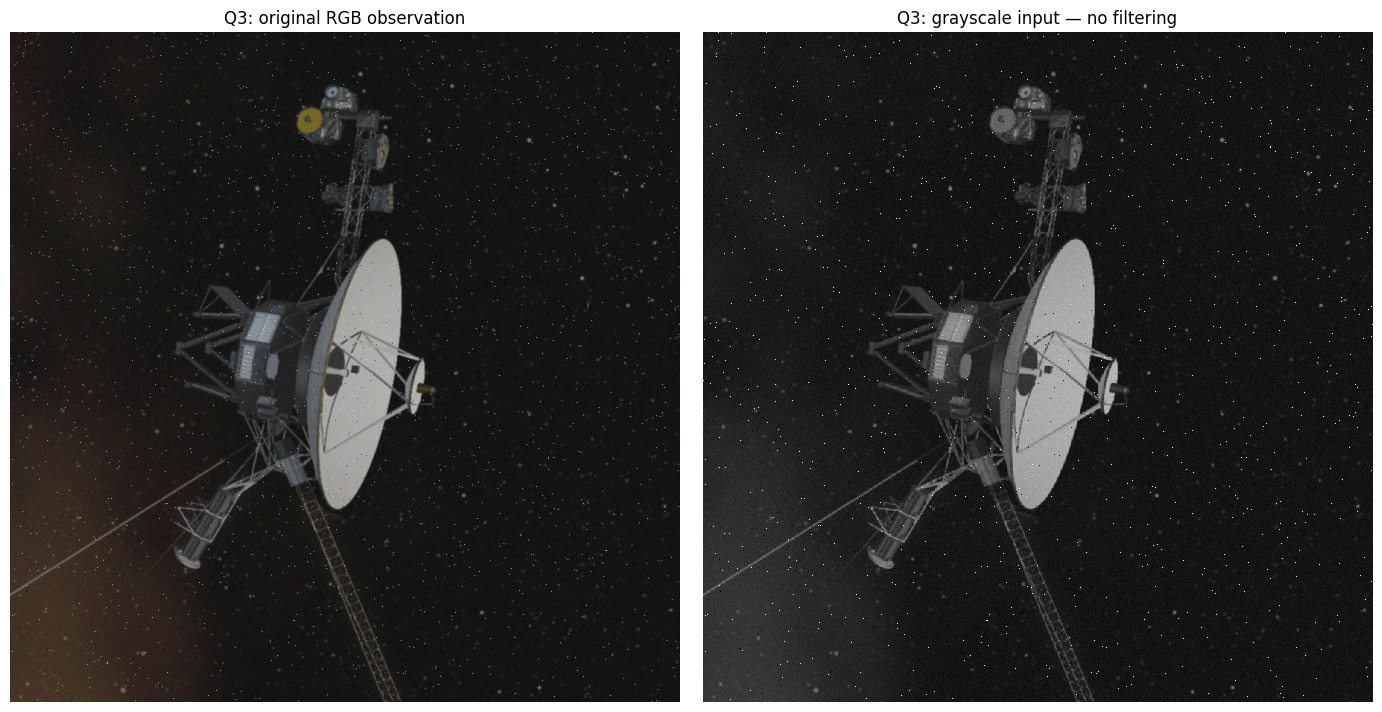

Original file mode: RGBA
RGB shape: (900, 900, 3)
Grayscale shape: (900, 900)
Grayscale data type: float64
Grayscale range: 0.0 to 255.0


In [ ]:
# Q3 — Load and inspect the input without filtering

q3_path = input_file("q3", "degraded_spacecraft.png")

with Image.open(q3_path) as image:
    original_mode = image.mode
    q3_input = np.array(image.convert("RGB"))

assert q3_input.shape == (900, 900, 3)
assert q3_input.dtype == np.uint8

# Convert to floating point before numerical processing.
q3_float = q3_input.astype(np.float64)

# Compute a grayscale intensity proxy using basic arithmetic.
q3_gray = (
    0.299 * q3_float[..., 0]
    + 0.587 * q3_float[..., 1]
    + 0.114 * q3_float[..., 2]
)

assert q3_gray.shape == (900, 900)
assert np.isfinite(q3_gray).all()

print("Original file mode:", original_mode)
print("RGB shape:", q3_input.shape)
print("Grayscale shape:", q3_gray.shape)
print("Grayscale data type:", q3_gray.dtype)
print(
    "Grayscale range:",
    float(q3_gray.min()),
    "to",
    float(q3_gray.max()),
)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(q3_input)
axes[0].set_title("Q3: original RGB observation")

axes[1].imshow(
    q3_gray,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest",
)
axes[1].set_title("Q3: grayscale input — no filtering")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

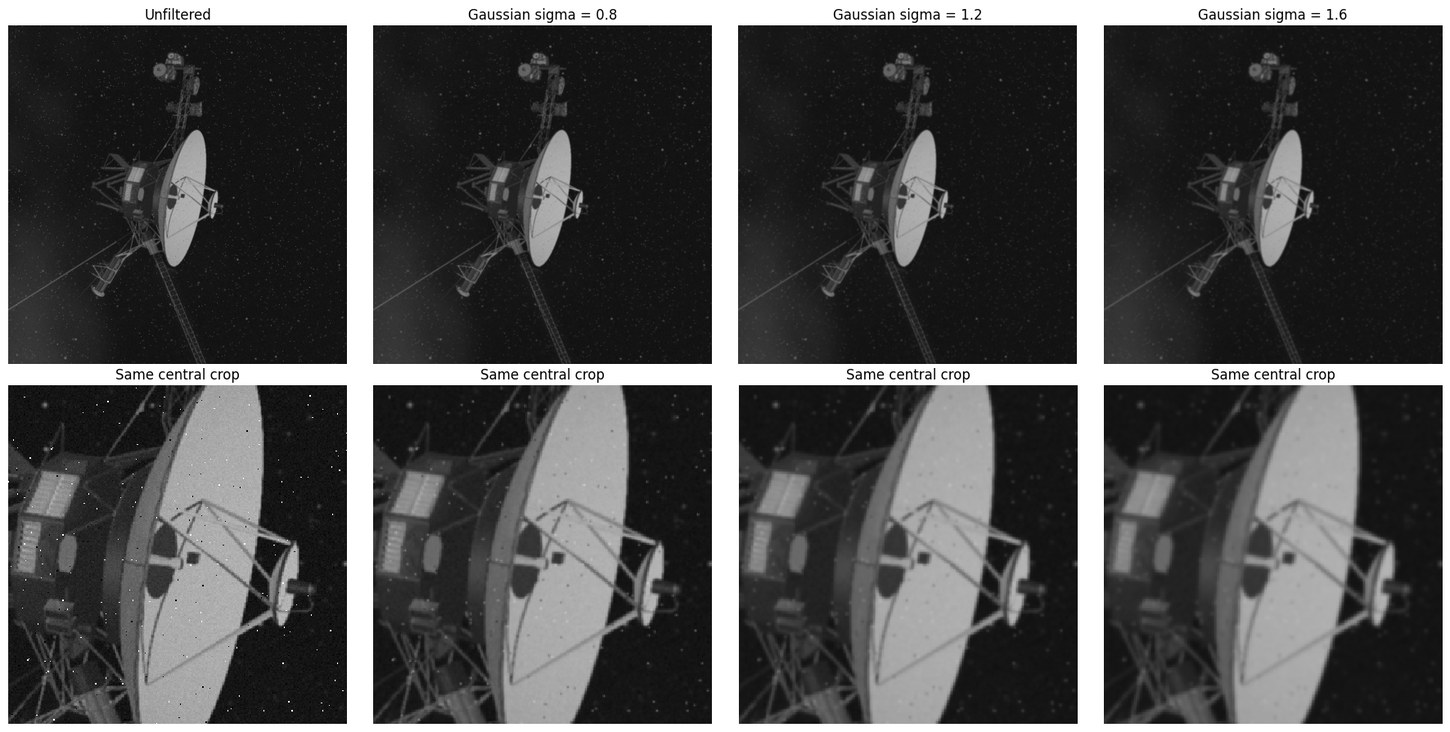

Alpha range: 255 to 255
Sigma 0.8: kernel shape = (7, 7)
Sigma 1.2: kernel shape = (9, 9)
Sigma 1.6: kernel shape = (11, 11)


No edge selection has been performed.


In [ ]:
# Q3 — Compare Gaussian smoothing implemented from basic operations

with Image.open(q3_path) as image:
    if "A" in image.getbands():
        alpha = np.asarray(image.getchannel("A"))
        print("Alpha range:", int(alpha.min()), "to", int(alpha.max()))
        assert np.all(alpha == 255), (
            "Non-opaque pixels found; inspect alpha handling before proceeding."
        )

def q3_gaussian_kernel(sigma):
    assert sigma > 0

    radius = int(np.ceil(3 * sigma))
    coordinates = np.arange(-radius, radius + 1, dtype=np.float64)
    yy, xx = np.meshgrid(coordinates, coordinates, indexing="ij")

    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return kernel / kernel.sum()


def q3_convolve(image, kernel):
    image = np.asarray(image, dtype=np.float64)
    kh, kw = kernel.shape
    assert kh % 2 == 1 and kw % 2 == 1

    padded = np.pad(
        image,
        ((kh // 2, kh // 2), (kw // 2, kw // 2)),
        mode="reflect",
    )

    flipped_kernel = kernel[::-1, ::-1]
    result = np.zeros_like(image, dtype=np.float64)
    height, width = image.shape

    for row in range(kh):
        for col in range(kw):
            result += (
                flipped_kernel[row, col]
                * padded[row:row + height, col:col + width]
            )

    return result


q3_sigmas = [0.8, 1.2, 1.6]
q3_smoothed_candidates = {}

for sigma in q3_sigmas:
    kernel = q3_gaussian_kernel(sigma)

    assert np.isclose(kernel.sum(), 1.0)
    assert np.all(kernel >= 0)

    q3_smoothed_candidates[sigma] = q3_convolve(q3_gray, kernel)
    print(f"Sigma {sigma}: kernel shape = {kernel.shape}")

versions = [("Unfiltered", q3_gray)] + [
    (f"Gaussian sigma = {sigma}", q3_smoothed_candidates[sigma])
    for sigma in q3_sigmas
]

# A fixed central crop is used only for display, not for edge selection.
height, width = q3_gray.shape
crop_size = 300
x0 = (width - crop_size) // 2
y0 = (height - crop_size) // 2

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for col, (title, image) in enumerate(versions):
    axes[0, col].imshow(
        image, cmap="gray", vmin=0, vmax=255
    )
    axes[0, col].set_title(title)

    axes[1, col].imshow(
        image[y0:y0 + crop_size, x0:x0 + crop_size],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    axes[1, col].set_title("Same central crop")

    for row in range(2):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

print("No edge selection has been performed.")

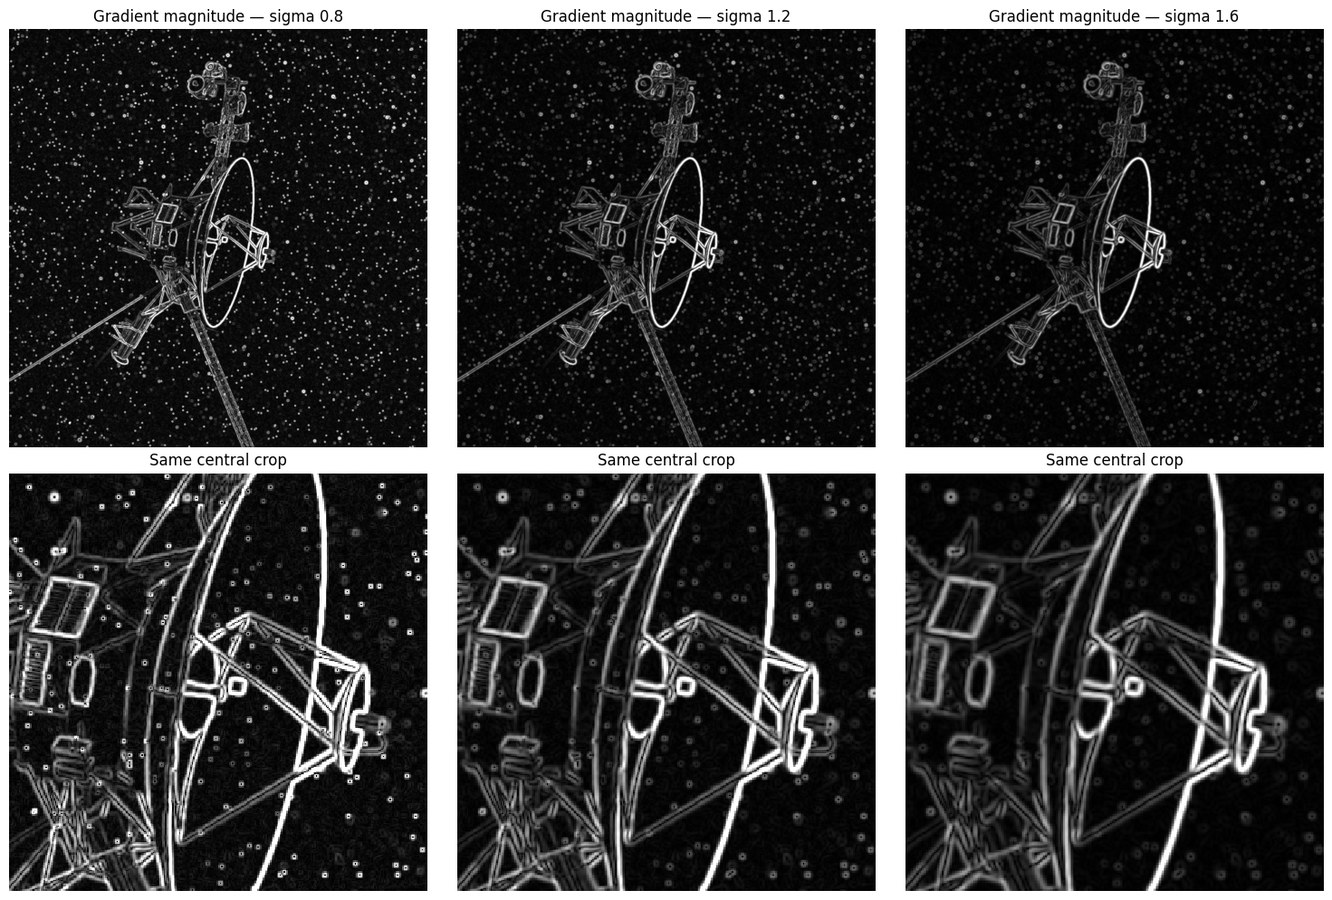

   sigma  median_magnitude  p95_magnitude  p99_magnitude  max_magnitude
0    0.8            1.1676         9.9941        20.6300        53.6130
1    1.2            0.7241         7.7624        14.8683        41.3073
2    1.6            0.5004         5.2885        12.4002        34.0784

All panels use the same gradient display scale.
Display saturation does not modify the gradient arrays.
These are continuous edge responses, not final binary edge maps.


In [ ]:
# Q3 — Compute Sobel gradients using the hand-written convolution

# These kernels are defined for true convolution, which flips the kernel.
# Positive gx follows increasing intensity to the right.
# Positive gy follows increasing intensity downward.
q3_sobel_x = np.array([
    [1, 0, -1],
    [2, 0, -2],
    [1, 0, -1],
], dtype=np.float64) / 8.0

q3_sobel_y = q3_sobel_x.T

q3_gradient_candidates = {}
gradient_rows = []

for sigma in q3_sigmas:
    smoothed = q3_smoothed_candidates[sigma]

    gx = q3_convolve(smoothed, q3_sobel_x)
    gy = q3_convolve(smoothed, q3_sobel_y)

    magnitude = np.sqrt(gx**2 + gy**2)
    direction = np.arctan2(gy, gx)

    assert np.isfinite(magnitude).all()
    assert magnitude.shape == (900, 900)

    q3_gradient_candidates[sigma] = {
        "gx": gx,
        "gy": gy,
        "magnitude": magnitude,
        "direction": direction,
    }

    gradient_rows.append({
        "sigma": sigma,
        "median_magnitude": np.median(magnitude),
        "p95_magnitude": np.percentile(magnitude, 95),
        "p99_magnitude": np.percentile(magnitude, 99),
        "max_magnitude": magnitude.max(),
    })

# Use one shared display limit across all candidates.
display_limit = max(
    np.percentile(
        q3_gradient_candidates[sigma]["magnitude"], 99.5
    )
    for sigma in q3_sigmas
)
display_limit = max(float(display_limit), 1e-12)

height, width = q3_gray.shape
crop_size = 300
x0 = (width - crop_size) // 2
y0 = (height - crop_size) // 2

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for col, sigma in enumerate(q3_sigmas):
    magnitude = q3_gradient_candidates[sigma]["magnitude"]

    axes[0, col].imshow(
        magnitude,
        cmap="gray",
        vmin=0,
        vmax=display_limit,
    )
    axes[0, col].set_title(f"Gradient magnitude — sigma {sigma}")

    axes[1, col].imshow(
        magnitude[y0:y0 + crop_size, x0:x0 + crop_size],
        cmap="gray",
        vmin=0,
        vmax=display_limit,
        interpolation="nearest",
    )
    axes[1, col].set_title("Same central crop")

    for row in range(2):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

display(pd.DataFrame(gradient_rows).round(4))

print("All panels use the same gradient display scale.")
print("Display saturation does not modify the gradient arrays.")
print("These are continuous edge responses, not final binary edge maps.")

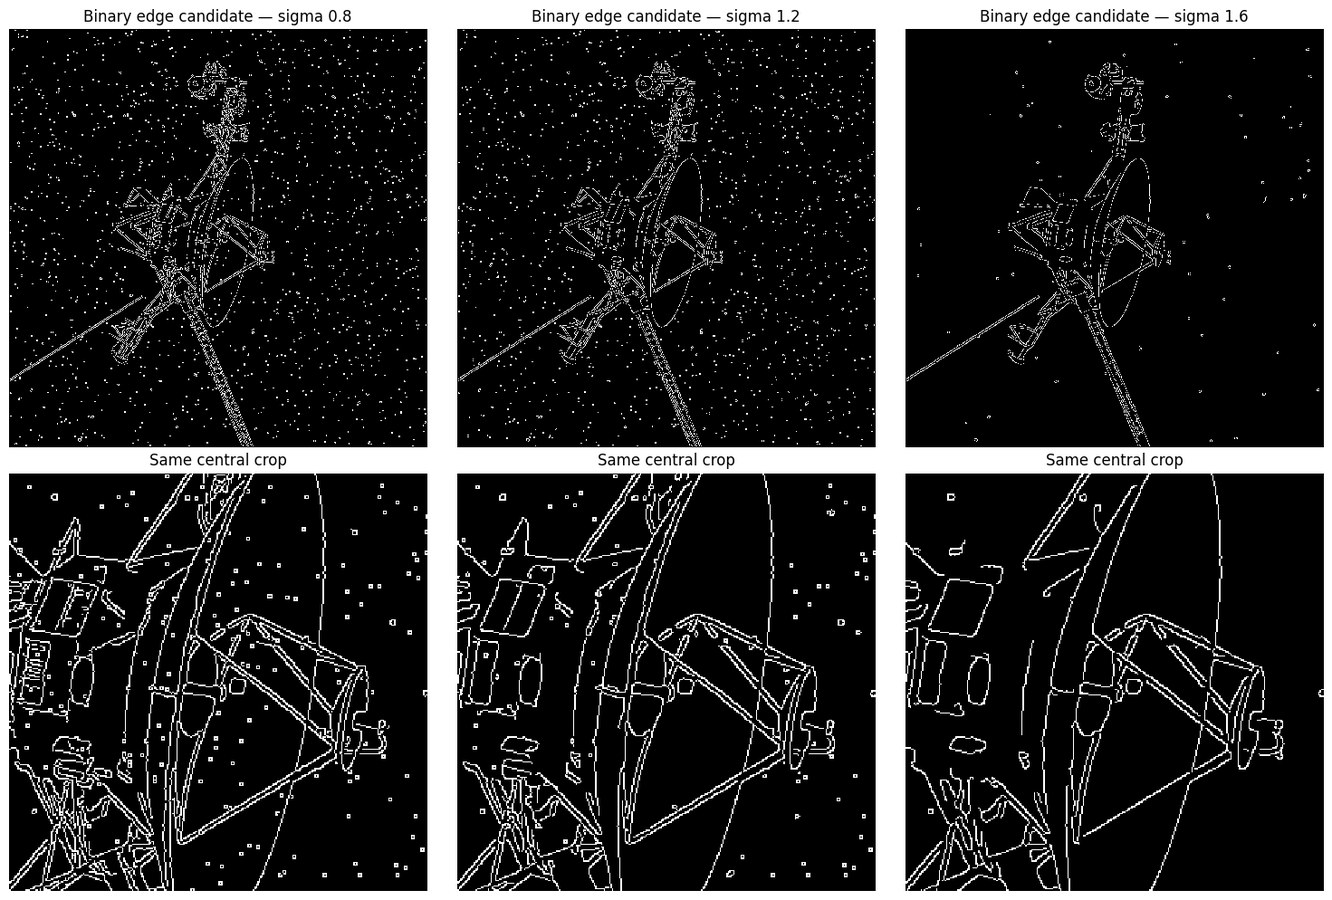

   sigma  low_threshold  high_threshold  strong_seed_pixels  \
0    0.8            3.2             8.0               27458   
1    1.2            3.2             8.0               20599   
2    1.6            3.2             8.0                7759   

   final_edge_pixels  edge_percent  
0              31795        3.9253  
1              27895        3.4438  
2              13310        1.6432  

Directions are quantized into four comparison orientations.
The outermost image border is set to zero during suppression.
All candidates satisfy the required binary output format.
No final candidate has been selected.


In [ ]:
# Q3 — Hand-written non-maximum suppression and hysteresis

def q3_nonmax_suppression(magnitude, direction):
    result = np.zeros_like(magnitude)

    center = magnitude[1:-1, 1:-1]
    angle = np.degrees(direction[1:-1, 1:-1]) % 180.0

    # Image coordinates: x increases rightward, y increases downward.
    comparisons = [
        (
            (angle < 22.5) | (angle >= 157.5),
            magnitude[1:-1, :-2],
            magnitude[1:-1, 2:],
        ),
        (
            (angle >= 22.5) & (angle < 67.5),
            magnitude[:-2, :-2],
            magnitude[2:, 2:],
        ),
        (
            (angle >= 67.5) & (angle < 112.5),
            magnitude[:-2, 1:-1],
            magnitude[2:, 1:-1],
        ),
        (
            (angle >= 112.5) & (angle < 157.5),
            magnitude[:-2, 2:],
            magnitude[2:, :-2],
        ),
    ]

    keep = np.zeros(center.shape, dtype=bool)

    for direction_mask, neighbor_a, neighbor_b in comparisons:
        keep |= (
            direction_mask
            & (center > 0)
            & (center >= neighbor_a)
            & (center >= neighbor_b)
        )

    result[1:-1, 1:-1] = np.where(keep, center, 0.0)
    return result


def q3_hysteresis(response, low, high):
    assert 0 < low <= high

    eligible = response >= low
    accepted = response >= high

    stack = list(zip(*np.nonzero(accepted)))
    height, width = response.shape

    while stack:
        y, x = stack.pop()

        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                if dy == 0 and dx == 0:
                    continue

                ny, nx = y + dy, x + dx

                if (
                    0 <= ny < height
                    and 0 <= nx < width
                    and eligible[ny, nx]
                    and not accepted[ny, nx]
                ):
                    accepted[ny, nx] = True
                    stack.append((ny, nx))

    return accepted.astype(np.uint8) * 255


# Fixed thresholds allow an initial comparison across smoothing scales.
# These are trial values, not validated optimal thresholds.
Q3_TRIAL_HIGH = 8.0
Q3_TRIAL_LOW = 3.2

q3_nms_candidates = {}
q3_binary_candidates = {}
edge_rows = []

for sigma in q3_sigmas:
    gradients = q3_gradient_candidates[sigma]

    response = q3_nonmax_suppression(
        gradients["magnitude"],
        gradients["direction"],
    )
    edges = q3_hysteresis(
        response, Q3_TRIAL_LOW, Q3_TRIAL_HIGH
    )

    assert edges.shape == (900, 900)
    assert edges.dtype == np.uint8
    assert set(np.unique(edges)).issubset({0, 255})

    q3_nms_candidates[sigma] = response
    q3_binary_candidates[sigma] = edges

    edge_rows.append({
        "sigma": sigma,
        "low_threshold": Q3_TRIAL_LOW,
        "high_threshold": Q3_TRIAL_HIGH,
        "strong_seed_pixels": int(
            np.count_nonzero(response >= Q3_TRIAL_HIGH)
        ),
        "final_edge_pixels": int(np.count_nonzero(edges)),
        "edge_percent": 100 * np.mean(edges > 0),
    })

height, width = q3_gray.shape
crop_size = 300
x0 = (width - crop_size) // 2
y0 = (height - crop_size) // 2

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for col, sigma in enumerate(q3_sigmas):
    edges = q3_binary_candidates[sigma]

    axes[0, col].imshow(
        edges, cmap="gray", vmin=0, vmax=255,
        interpolation="nearest",
    )
    axes[0, col].set_title(f"Binary edge candidate — sigma {sigma}")

    axes[1, col].imshow(
        edges[y0:y0 + crop_size, x0:x0 + crop_size],
        cmap="gray", vmin=0, vmax=255,
        interpolation="nearest",
    )
    axes[1, col].set_title("Same central crop")

    for row in range(2):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

display(pd.DataFrame(edge_rows).round(4))

print("Directions are quantized into four comparison orientations.")
print("The outermost image border is set to zero during suppression.")
print("All candidates satisfy the required binary output format.")
print("No final candidate has been selected.")

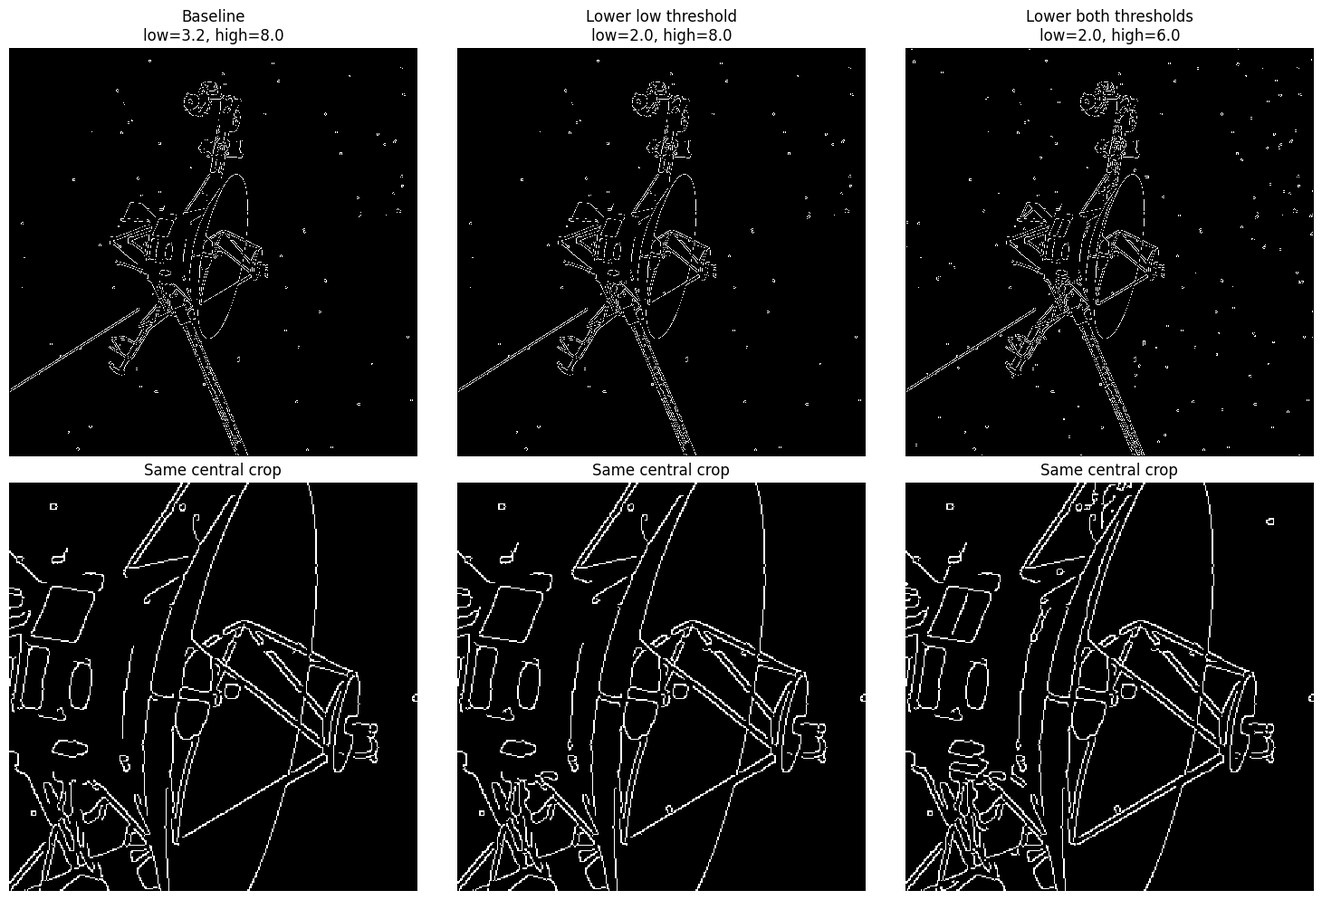

                 setting  sigma  low_threshold  high_threshold  \
0               Baseline    1.6            3.2             8.0   
1    Lower low threshold    1.6            2.0             8.0   
2  Lower both thresholds    1.6            2.0             6.0   

   strong_seed_pixels  edge_pixels  edge_percent  
0                7759        13310        1.6432  
1                7759        13887        1.7144  
2               12095        16981        2.0964  

Only hysteresis thresholds changed; smoothing and NMS are fixed.
More edge pixels do not necessarily mean better boundary recovery.


In [ ]:
# Q3 — Compare a small set of hysteresis thresholds at sigma 1.6

q3_selected_sigma = 1.6
response = q3_nms_candidates[q3_selected_sigma]

threshold_settings = [
    ("Baseline", 3.2, 8.0),
    ("Lower low threshold", 2.0, 8.0),
    ("Lower both thresholds", 2.0, 6.0),
]

q3_threshold_candidates = {}
threshold_rows = []

height, width = response.shape
crop_size = 300
x0 = (width - crop_size) // 2
y0 = (height - crop_size) // 2

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for col, (name, low, high) in enumerate(threshold_settings):
    edges = q3_hysteresis(response, low, high)

    assert edges.shape == (900, 900)
    assert set(np.unique(edges)).issubset({0, 255})

    q3_threshold_candidates[(low, high)] = edges

    threshold_rows.append({
        "setting": name,
        "sigma": q3_selected_sigma,
        "low_threshold": low,
        "high_threshold": high,
        "strong_seed_pixels": int(np.count_nonzero(response >= high)),
        "edge_pixels": int(np.count_nonzero(edges)),
        "edge_percent": 100 * np.mean(edges > 0),
    })

    axes[0, col].imshow(
        edges,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    axes[0, col].set_title(
        f"{name}\nlow={low}, high={high}"
    )

    axes[1, col].imshow(
        edges[y0:y0 + crop_size, x0:x0 + crop_size],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    axes[1, col].set_title("Same central crop")

    for row in range(2):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

display(pd.DataFrame(threshold_rows).round(4))

print("Only hysteresis thresholds changed; smoothing and NMS are fixed.")
print("More edge pixels do not necessarily mean better boundary recovery.")

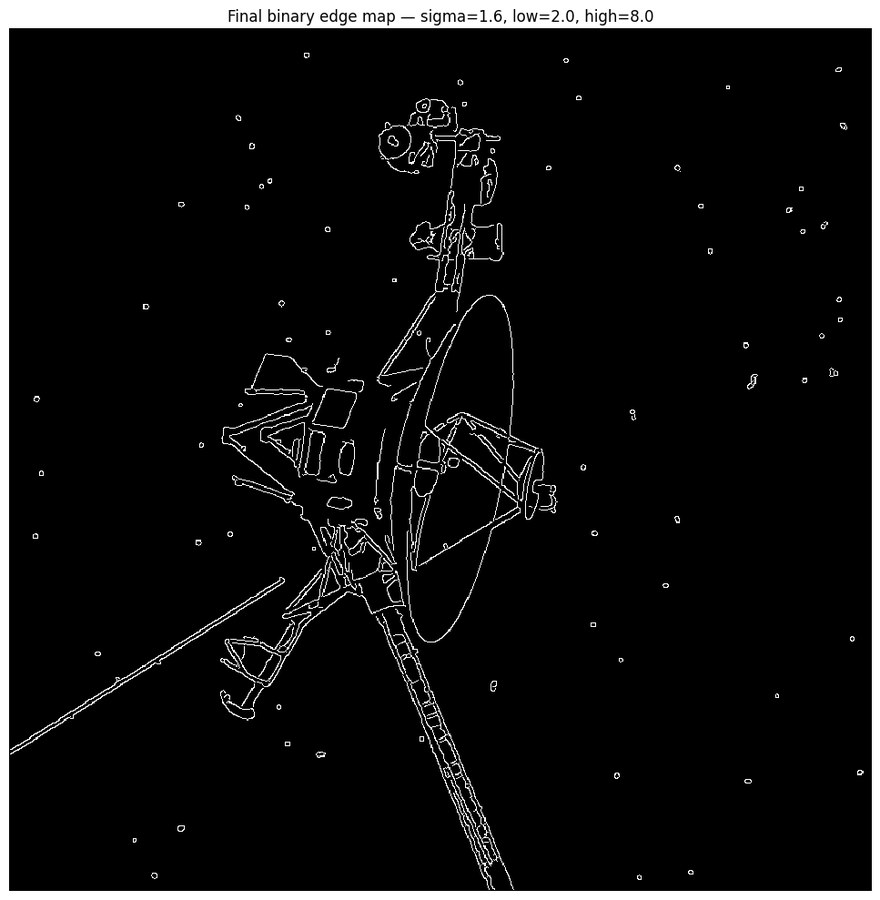

In [ ]:
# Q3 — Final binary edge map

q3_final = q3_threshold_candidates[(2.0, 8.0)].copy()

assert q3_final.shape == (900, 900)
assert q3_final.dtype == np.uint8
assert np.all(np.isin(q3_final, [0, 255]))

q3_output_dir = RESULTS / "q3"
q3_output_dir.mkdir(parents=True, exist_ok=True)
q3_saved_path = q3_output_dir / "edges.png"

Image.fromarray(q3_final).save(q3_saved_path)

with Image.open(q3_saved_path) as image:
    q3_saved = np.array(image)

assert np.array_equal(q3_saved, q3_final)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(
    q3_final,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest",
)
ax.set_title(
    "Final binary edge map — sigma=1.6, low=2.0, high=8.0"
)
ax.axis("off")
plt.tight_layout()
plt.show()

print("Final shape:", q3_final.shape)
print("Final data type:", q3_final.dtype)
print("Unique values:", np.unique(q3_final))
print("Edge pixels:", np.count_nonzero(q3_final))
print(f"Edge percentage: {100 * np.mean(q3_final > 0):.4f}%")
print("Saved PNG matches final array:", np.array_equal(q3_saved, q3_final))
print("Saved to:", q3_saved_path)

### Q3 — Method, Results, and Limitations

#### Input analysis

The input is a 900 × 900 image of the Voyager spacecraft against a
star field. It contains curved boundaries, thin supports, and faint
structural elements, together with blur and noise. Background stars
also produce strong local intensity changes and can therefore appear
in an edge map.

The original image uses RGBA format, but its alpha channel is fully
opaque. The RGB channels were converted to floating-point grayscale
using 0.299R + 0.587G + 0.114B, retaining the intensity scale from
0 to 255.

#### Filtering and gradient computation

The filtering and edge-detection procedure was implemented from
scratch using basic NumPy operations. No OpenCV or prebuilt filtering,
gradient, or edge-selection functions were used. Pillow handled image
input and output, and Matplotlib handled visualization.

Gaussian smoothing was applied before gradient computation. Each
kernel extended to ceil(3σ) pixels on either side and was normalized
to sum to one. Convolution used reflection padding to reduce artificial
intensity discontinuities at the image boundary.

Horizontal and vertical gradients were computed using Sobel kernels
divided by 8. Gradient magnitude was calculated as
sqrt(gx² + gy²), and gradient direction as atan2(gy, gx).

#### Edge selection

Non-maximum suppression compared each gradient magnitude with its
neighbors along one of four quantized gradient orientations:
0°, 45°, 90°, and 135°. Positive responses that were at least as large
as both comparison neighbors were retained. The outermost image
border was set to zero.

Hysteresis used a high threshold to identify strong edge seeds and a
low threshold to identify eligible weak responses. Weak responses
were retained only when connected to a strong seed through an
8-connected path of eligible pixels.

#### Parameter comparison and results

Gaussian standard deviations of 0.8, 1.2, and 1.6 were compared using
shared display scales and identical local crops. Smaller values
preserved more fine structure but also retained many responses around
background stars. A standard deviation of 1.6 was selected as a
compromise between spacecraft boundary recovery and background
suppression.

With σ fixed at 1.6, three hysteresis settings were compared:

| Low threshold | High threshold | Strong seed pixels | Edge pixels | Edge percentage |
|---:|---:|---:|---:|---:|
| 3.2 | 8.0 | 7,759 | 13,310 | 1.6432% |
| 2.0 | 8.0 | 7,759 | 13,887 | 1.7144% |
| 2.0 | 6.0 | 12,095 | 16,981 | 2.0964% |

The final setting was σ = 1.6, low = 2.0, and high = 8.0.
Lowering only the low threshold retained 577 additional connected
weak-response pixels without changing the strong seeds. Visual
inspection showed some additional structural continuity without a
large increase in background responses.

Lowering the high threshold to 6.0 admitted additional spacecraft
detail but also more background star responses. The middle setting
was therefore selected based on the visual comparison.

The threshold values apply to the gradient scale produced by Sobel
kernels divided by 8. Edge percentage describes sparsity, not detection
accuracy; fewer edge pixels do not necessarily indicate a better result.

#### Visual assessment and limitations

The final map preserves much of the curved dish boundary, major
supports, and long thin structures while suppressing many background
responses. However, some faint structures remain fragmented, and
some stars still produce small closed contours.

Gaussian smoothing can remove genuine fine detail together with
noise. Quantizing gradient directions can also affect edge localization,
and hysteresis cannot recover weak boundaries that have no eligible
connection to a strong seed.

The reference edge map is unavailable, so accuracy against the hidden
reference was not measured. The parameter comparisons support a
tradeoff between boundary recovery, false responses, and sparsity,
but do not establish that the selected parameters are optimal.

#### Final output

The final edge map is displayed in the notebook and saved as
`edges.png`. It is a 900 × 900 single-channel uint8 image containing
only 0 and 255, with 13,887 edge pixels (1.7144%).

Reloading the saved PNG confirmed exact equality with the selected
final array.

## Q4 — Template Matching (10 points)

This section compares grayscale and detail-based normalized correlation
searches, verifies candidate agreement across four regions, and applies
a common acceptance rule. Queries are resized to 180 × 180; rotation
and more general geometric transformations are not explicitly searched.

The search treats the panorama as periodic horizontally, with no
vertical wrapping. Computed coordinates describe the top-left corner
of a 180 × 180 region in the original 6000 × 3000 panorama.
The final Markdown coordinate table and programmatically annotated
panorama are included below.

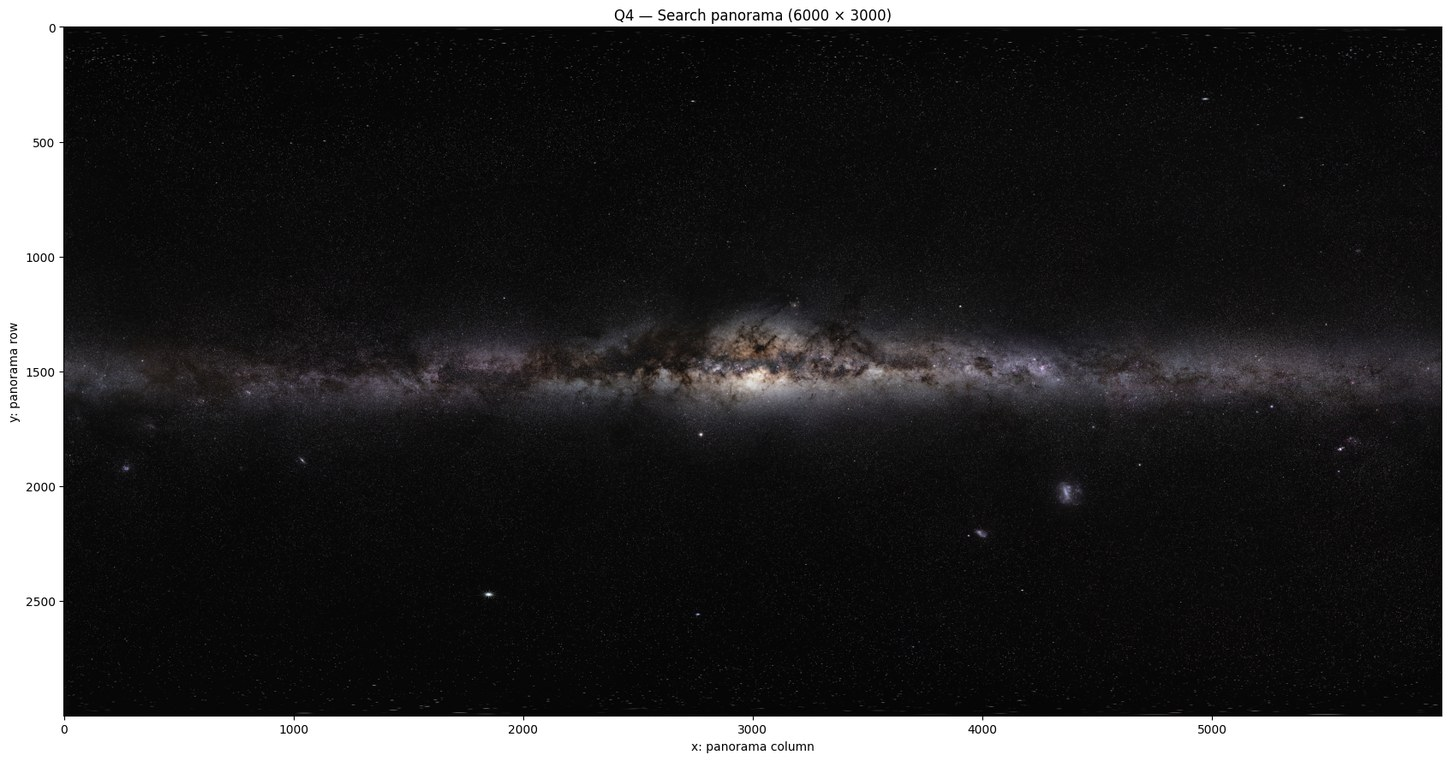

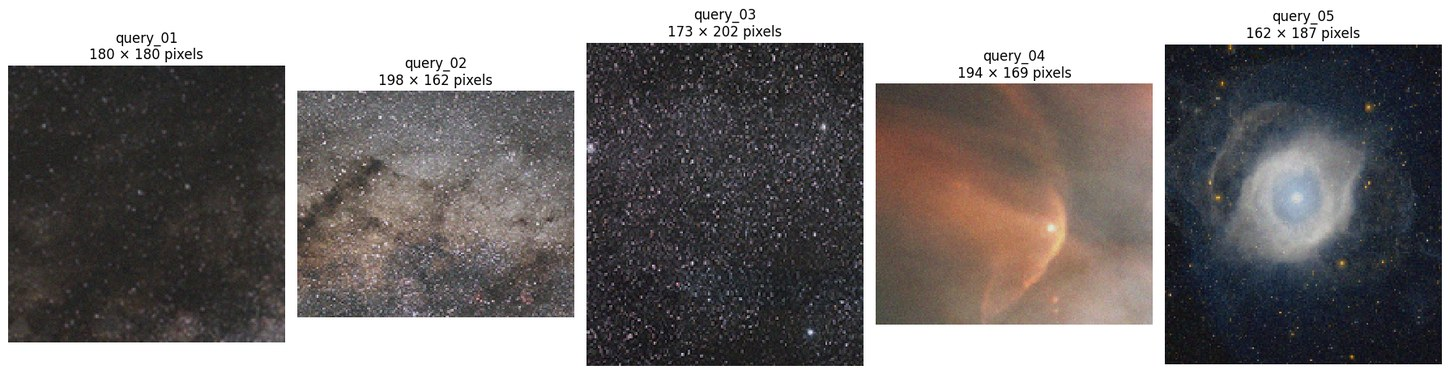

          image  width  height  channels  dtype  minimum  maximum
0  search_scene   6000    3000         3  uint8        0      255
1      query_01    180     180         3  uint8       18      140
2      query_02    198     162         3  uint8       26      245
3      query_03    173     202         3  uint8        0      230
4      query_04    194     169         3  uint8       34      240
5      query_05    162     187         3  uint8        2      224

Target region size in the original panorama: 180 × 180
Horizontal wrapping is allowed; vertical wrapping is not.
No matching or presence/absence decisions have been made.


In [ ]:
# Q4 — Load and inspect the panorama and query images

q4_scene = load_rgb(input_file("q4", "search_scene.jpg"))
q4_queries = {
    f"query_{i:02d}": load_rgb(
        input_file("q4", f"query_{i:02d}.png")
    )
    for i in range(1, 6)
}

assert q4_scene.shape == (3000, 6000, 3)
assert len(q4_queries) == 5

input_rows = []

for name, image in [("search_scene", q4_scene), *q4_queries.items()]:
    assert image.ndim == 3 and image.shape[2] == 3
    assert image.dtype == np.uint8

    input_rows.append({
        "image": name,
        "width": image.shape[1],
        "height": image.shape[0],
        "channels": image.shape[2],
        "dtype": str(image.dtype),
        "minimum": int(image.min()),
        "maximum": int(image.max()),
    })

display(pd.DataFrame(input_rows))

fig, ax = plt.subplots(figsize=(18, 9))
ax.imshow(q4_scene)
ax.set_title("Q4 — Search panorama (6000 × 3000)")
ax.set_xlabel("x: panorama column")
ax.set_ylabel("y: panorama row")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, (query_id, query) in zip(axes, q4_queries.items()):
    ax.imshow(query, interpolation="nearest")
    ax.set_title(
        f"{query_id}\n"
        f"{query.shape[1]} × {query.shape[0]} pixels"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


def panorama_patch(scene, x, y, size=180):
    """Extract a patch with horizontal wrapping only."""
    height, width = scene.shape[:2]

    assert isinstance(x, (int, np.integer))
    assert isinstance(y, (int, np.integer))
    assert 0 < size <= min(height, width)
    assert 0 <= x < width
    assert 0 <= y <= height - size

    columns = (np.arange(size) + x) % width
    return scene[y:y + size, columns]


q4_results = None

print("Target region size in the original panorama: 180 × 180")
print("Horizontal wrapping is allowed; vertical wrapping is not.")
print("No matching or presence/absence decisions have been made.")

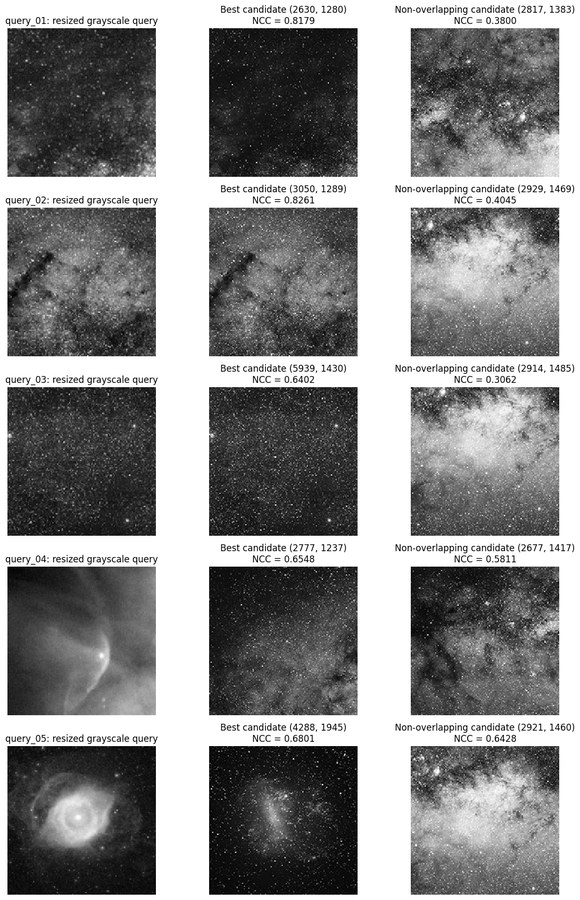

Finished baseline search for query_01
Finished baseline search for query_02
Finished baseline search for query_03
Finished baseline search for query_04
Finished baseline search for query_05


   query_id  candidate_x  candidate_y  best_NCC  second_nonoverlapping_NCC  \
0  query_01         2630         1280    0.8179                     0.3800   
1  query_02         3050         1289    0.8261                     0.4045   
2  query_03         5939         1430    0.6402                     0.3062   
3  query_04         2777         1237    0.6548                     0.5811   
4  query_05         4288         1945    0.6801                     0.6428   

   score_gap  crosses_seam  
0     0.4379         False  
1     0.4217         False  
2     0.3341          True  
3     0.0737         False  
4     0.0373         False  

Matching used the original panorama resolution.
Query resizing is a baseline assumption, not verified geometry.
Panels use independent grayscale display normalization.
Candidate coordinates are not final detections.
No presence/absence decisions have been made.


In [ ]:
# Q4 — Resize-only normalized correlation baseline

import cv2

Q4_PATCH_SIZE = 180


def q4_to_gray(rgb):
    rgb_float = rgb.astype(np.float32)
    return (
        0.299 * rgb_float[..., 0]
        + 0.587 * rgb_float[..., 1]
        + 0.114 * rgb_float[..., 2]
    )


q4_scene_gray = q4_to_gray(q4_scene)
q4_scene_extended = np.concatenate(
    [
        q4_scene_gray,
        q4_scene_gray[:, :Q4_PATCH_SIZE - 1],
    ],
    axis=1,
)

q4_baseline_candidates = {}
q4_baseline_rows = []

scene_height, scene_width = q4_scene_gray.shape

fig, axes = plt.subplots(
    len(q4_queries), 3, figsize=(12, 17)
)

for row, (query_id, query) in enumerate(q4_queries.items()):
    query_gray = q4_to_gray(query)

    # This baseline tests independent resizing of width and height.
    template = cv2.resize(
        query_gray,
        (Q4_PATCH_SIZE, Q4_PATCH_SIZE),
        interpolation=cv2.INTER_LINEAR,
    )

    assert float(template.std()) > 1e-6

    response = cv2.matchTemplate(
        q4_scene_extended,
        template,
        cv2.TM_CCOEFF_NORMED,
    )

    assert response.shape == (
        scene_height - Q4_PATCH_SIZE + 1,
        scene_width,
    )
    assert np.isfinite(response).all()

    best_y, best_x = np.unravel_index(
        np.argmax(response), response.shape
    )
    best_x, best_y = int(best_x), int(best_y)
    best_score = float(response[best_y, best_x])

    # Exclude overlapping candidate windows around the best match.
    # Horizontal distance respects the panorama seam.
    remaining = response.copy()
    columns = np.arange(scene_width)
    horizontal_distance = np.abs(columns - best_x)
    horizontal_distance = np.minimum(
        horizontal_distance,
        scene_width - horizontal_distance,
    )

    excluded_columns = horizontal_distance < Q4_PATCH_SIZE
    excluded_y_start = max(0, best_y - Q4_PATCH_SIZE + 1)
    excluded_y_end = min(
        response.shape[0], best_y + Q4_PATCH_SIZE
    )

    remaining[
        excluded_y_start:excluded_y_end,
        excluded_columns,
    ] = -np.inf

    second_y, second_x = np.unravel_index(
        np.argmax(remaining), remaining.shape
    )
    second_x, second_y = int(second_x), int(second_y)
    second_score = float(response[second_y, second_x])

    q4_baseline_candidates[query_id] = {
        "x": best_x,
        "y": best_y,
        "score": best_score,
        "second_x": second_x,
        "second_y": second_y,
        "second_score": second_score,
    }

    q4_baseline_rows.append({
        "query_id": query_id,
        "candidate_x": best_x,
        "candidate_y": best_y,
        "best_NCC": best_score,
        "second_nonoverlapping_NCC": second_score,
        "score_gap": best_score - second_score,
        "crosses_seam": best_x + Q4_PATCH_SIZE > scene_width,
    })

    best_patch = panorama_patch(
        q4_scene, best_x, best_y, Q4_PATCH_SIZE
    )
    second_patch = panorama_patch(
        q4_scene, second_x, second_y, Q4_PATCH_SIZE
    )

    panels = [
        (
            template,
            f"{query_id}: resized grayscale query",
        ),
        (
            q4_to_gray(best_patch),
            f"Best candidate ({best_x}, {best_y})\n"
            f"NCC = {best_score:.4f}",
        ),
        (
            q4_to_gray(second_patch),
            f"Non-overlapping candidate ({second_x}, {second_y})\n"
            f"NCC = {second_score:.4f}",
        ),
    ]

    for ax, (panel, title) in zip(axes[row], panels):
        # Independent display normalization helps compare structure.
        # It does not change the arrays used for matching.
        ax.imshow(
            panel,
            cmap="gray",
            vmin=float(panel.min()),
            vmax=float(panel.max()),
            interpolation="nearest",
        )
        ax.set_title(title)
        ax.axis("off")

    print(f"Finished baseline search for {query_id}", flush=True)

plt.tight_layout()
plt.show()

q4_baseline_table = pd.DataFrame(q4_baseline_rows)
display(q4_baseline_table.round(4))

print("Matching used the original panorama resolution.")
print("Query resizing is a baseline assumption, not verified geometry.")
print("Panels use independent grayscale display normalization.")
print("Candidate coordinates are not final detections.")
print("No presence/absence decisions have been made.")

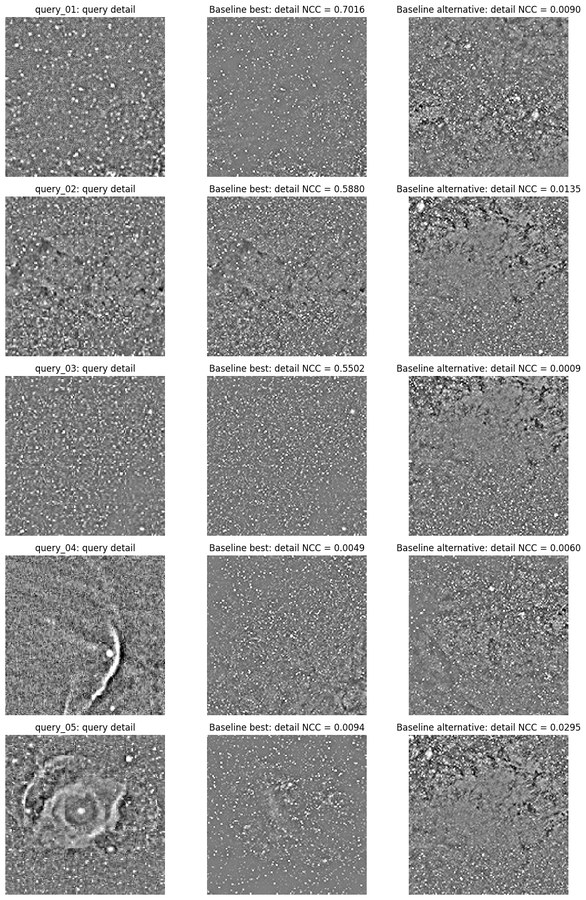

   query_id  best_raw_NCC  best_detail_NCC  alternative_detail_NCC
0  query_01        0.8179           0.7016                  0.0090
1  query_02        0.8261           0.5880                  0.0135
2  query_03        0.6402           0.5502                  0.0009
3  query_04        0.6548           0.0049                  0.0060
4  query_05        0.6801           0.0094                  0.0295

Candidate locations were not changed.
Detail scores use the interior 156 × 156 pixels.
The alternative is the raw-NCC alternative, not a new detail search.
Display limits do not alter the arrays used for scoring.
This diagnostic does not establish presence or absence.


In [ ]:
# Q4 — Check local structure at the baseline candidate locations

def q4_detail_response(gray, sigma=3.0):
    gray = np.asarray(gray, dtype=np.float32)
    background = cv2.GaussianBlur(
        gray,
        (0, 0),
        sigmaX=sigma,
        sigmaY=sigma,
        borderType=cv2.BORDER_REFLECT_101,
    )
    return gray - background


def q4_array_ncc(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)

    a = a - a.mean()
    b = b - b.mean()

    denominator = np.sqrt(
        np.sum(a * a) * np.sum(b * b)
    )

    if denominator <= 1e-12:
        return np.nan

    return float(np.sum(a * b) / denominator)


q4_detail_rows = []
fig, axes = plt.subplots(5, 3, figsize=(12, 17))

# Exclude patch borders to reduce filtering boundary effects.
margin = 12
interior = np.s_[margin:-margin, margin:-margin]

for row, (query_id, query) in enumerate(q4_queries.items()):
    candidate = q4_baseline_candidates[query_id]

    template = cv2.resize(
        q4_to_gray(query),
        (180, 180),
        interpolation=cv2.INTER_LINEAR,
    )

    best_patch = q4_to_gray(
        panorama_patch(
            q4_scene, candidate["x"], candidate["y"]
        )
    )
    second_patch = q4_to_gray(
        panorama_patch(
            q4_scene,
            candidate["second_x"],
            candidate["second_y"],
        )
    )

    query_detail = q4_detail_response(template)[interior]
    best_detail = q4_detail_response(best_patch)[interior]
    second_detail = q4_detail_response(second_patch)[interior]

    best_detail_ncc = q4_array_ncc(query_detail, best_detail)
    second_detail_ncc = q4_array_ncc(query_detail, second_detail)

    q4_detail_rows.append({
        "query_id": query_id,
        "best_raw_NCC": candidate["score"],
        "best_detail_NCC": best_detail_ncc,
        "alternative_detail_NCC": second_detail_ncc,
    })

    panels = [
        (query_detail, f"{query_id}: query detail"),
        (
            best_detail,
            f"Baseline best: detail NCC = {best_detail_ncc:.4f}",
        ),
        (
            second_detail,
            f"Baseline alternative: detail NCC = "
            f"{second_detail_ncc:.4f}",
        ),
    ]

    for ax, (panel, title) in zip(axes[row], panels):
        limit = max(float(np.percentile(np.abs(panel), 99)), 1e-6)
        ax.imshow(
            panel,
            cmap="gray",
            vmin=-limit,
            vmax=limit,
            interpolation="nearest",
        )
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.show()

q4_detail_table = pd.DataFrame(q4_detail_rows)
display(q4_detail_table.round(4))

print("Candidate locations were not changed.")
print("Detail scores use the interior 156 × 156 pixels.")
print("The alternative is the raw-NCC alternative, not a new detail search.")
print("Display limits do not alter the arrays used for scoring.")
print("This diagnostic does not establish presence or absence.")

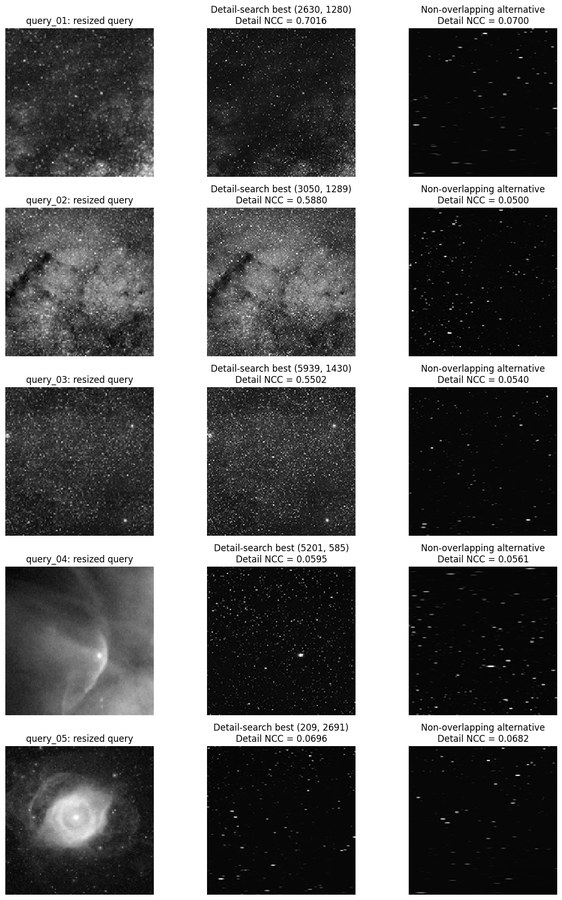

Finished global detail search for query_01
Finished global detail search for query_02
Finished global detail search for query_03
Finished global detail search for query_04
Finished global detail search for query_05


   query_id  candidate_x  candidate_y  best_detail_NCC  second_detail_NCC  \
0  query_01         2630         1280           0.7016             0.0700   
1  query_02         3050         1289           0.5880             0.0500   
2  query_03         5939         1430           0.5502             0.0540   
3  query_04         5201          585           0.0595             0.0561   
4  query_05          209         2691           0.0696             0.0682   

   detail_gap  dx_from_raw  dy_from_raw  crosses_seam  
0      0.6315            0            0         False  
1      0.5380            0            0         False  
2      0.4962            0            0          True  
3      0.0034         2424         -652         False  
4      0.0014         1921          746         False  

Coordinates refer to full 180 × 180 regions.
Matching uses interior detail; figures show full grayscale patches.
Horizontal filtering and extraction respect the panorama seam.
Only resize-based geometry has been tested.
No final presence/absence decisions have been made.


In [ ]:
# Q4 — Global detail-NCC search with horizontal wrapping

Q4_DETAIL_MARGIN = 12
Q4_DETAIL_SIGMA = 3.0
size = Q4_PATCH_SIZE
margin = Q4_DETAIL_MARGIN

height, width = q4_scene_gray.shape

# Add periodic horizontal context before filtering.
# Vertical filtering uses reflection, not wrapping.
periodic_columns = np.arange(-margin, width + margin) % width
scene_padded = q4_scene_gray[:, periodic_columns]

background_padded = cv2.GaussianBlur(
    scene_padded,
    (2 * margin + 1, 2 * margin + 1),
    sigmaX=Q4_DETAIL_SIGMA,
    sigmaY=Q4_DETAIL_SIGMA,
    borderType=cv2.BORDER_REFLECT_101,
)

scene_detail = (
    scene_padded - background_padded
)[:, margin:margin + width]

detail_extended = np.concatenate(
    [scene_detail, scene_detail[:, :size - 1]],
    axis=1,
)

# Each response index remains the top-left corner of a full 180 × 180 patch.
detail_search = np.ascontiguousarray(
    detail_extended[margin:-margin, margin:-margin]
)

q4_global_detail_candidates = {}
global_detail_rows = []

fig, axes = plt.subplots(5, 3, figsize=(12, 17))

for row, (query_id, query) in enumerate(q4_queries.items()):
    template = cv2.resize(
        q4_to_gray(query),
        (size, size),
        interpolation=cv2.INTER_LINEAR,
    )

    template_detail = np.ascontiguousarray(
        q4_detail_response(template, Q4_DETAIL_SIGMA)[
            margin:-margin, margin:-margin
        ]
    )

    assert float(template_detail.std()) > 1e-6

    response = cv2.matchTemplate(
        detail_search,
        template_detail,
        cv2.TM_CCOEFF_NORMED,
    )

    assert response.shape == (height - size + 1, width)
    assert np.isfinite(response).all()

    best_y, best_x = np.unravel_index(
        np.argmax(response), response.shape
    )
    best_x, best_y = int(best_x), int(best_y)
    best_score = float(response[best_y, best_x])

    # Find the strongest alternative whose full patch does not overlap.
    remaining = response.copy()
    distance_x = np.abs(np.arange(width) - best_x)
    distance_x = np.minimum(distance_x, width - distance_x)

    remaining[
        max(0, best_y - size + 1):min(
            response.shape[0], best_y + size
        ),
        distance_x < size,
    ] = -np.inf

    second_y, second_x = np.unravel_index(
        np.argmax(remaining), remaining.shape
    )
    second_x, second_y = int(second_x), int(second_y)
    second_score = float(response[second_y, second_x])

    previous = q4_baseline_candidates[query_id]
    shift_x = (best_x - previous["x"] + width // 2) % width - width // 2
    shift_y = best_y - previous["y"]

    q4_global_detail_candidates[query_id] = {
        "x": best_x,
        "y": best_y,
        "score": best_score,
        "second_x": second_x,
        "second_y": second_y,
        "second_score": second_score,
    }

    global_detail_rows.append({
        "query_id": query_id,
        "candidate_x": best_x,
        "candidate_y": best_y,
        "best_detail_NCC": best_score,
        "second_detail_NCC": second_score,
        "detail_gap": best_score - second_score,
        "dx_from_raw": int(shift_x),
        "dy_from_raw": int(shift_y),
        "crosses_seam": best_x + size > width,
    })

    best_patch = panorama_patch(q4_scene, best_x, best_y)
    second_patch = panorama_patch(q4_scene, second_x, second_y)

    panels = [
        (template, f"{query_id}: resized query"),
        (
            q4_to_gray(best_patch),
            f"Detail-search best ({best_x}, {best_y})\n"
            f"Detail NCC = {best_score:.4f}",
        ),
        (
            q4_to_gray(second_patch),
            f"Non-overlapping alternative\n"
            f"Detail NCC = {second_score:.4f}",
        ),
    ]

    for ax, (panel, title) in zip(axes[row], panels):
        ax.imshow(
            panel,
            cmap="gray",
            vmin=float(panel.min()),
            vmax=float(panel.max()),
            interpolation="nearest",
        )
        ax.set_title(title)
        ax.axis("off")

    print(f"Finished global detail search for {query_id}", flush=True)

plt.tight_layout()
plt.show()

q4_global_detail_table = pd.DataFrame(global_detail_rows)
display(q4_global_detail_table.round(4))

print("Coordinates refer to full 180 × 180 regions.")
print("Matching uses interior detail; figures show full grayscale patches.")
print("Horizontal filtering and extraction respect the panorama seam.")
print("Only resize-based geometry has been tested.")
print("No final presence/absence decisions have been made.")

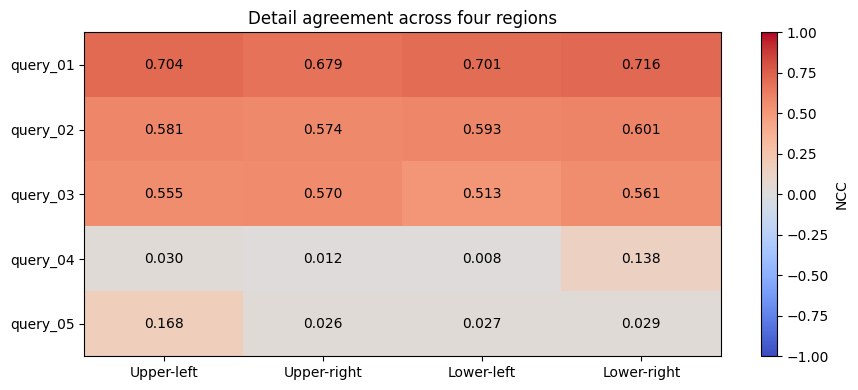

   query_id  candidate_x  candidate_y  global_detail_NCC  upper_left  \
0  query_01         2630         1280             0.7016      0.7036   
1  query_02         3050         1289             0.5880      0.5807   
2  query_03         5939         1430             0.5502      0.5548   
3  query_04         5201          585             0.0595      0.0295   
4  query_05          209         2691             0.0696      0.1677   

   upper_right  lower_left  lower_right  minimum_region_NCC  median_region_NCC  
0       0.6788      0.7006       0.7160              0.6788             0.7021  
1       0.5744      0.5930       0.6011              0.5744             0.5868  
2       0.5703      0.5130       0.5611              0.5130             0.5579  
3       0.0119      0.0080       0.1380              0.0080             0.0207  
4       0.0258      0.0275       0.0295              0.0258             0.0285  

Each region contains 78 × 78 pixels.
Candidate locations were not changed.
Regional scores are consistency checks, not independent tests.
Low regional agreement can also result from noise or misalignment.
No final presence/absence decisions have been made.


In [ ]:
# Q4 — Verify detail agreement across four spatial regions

margin = Q4_DETAIL_MARGIN
size = Q4_PATCH_SIZE
inner_size = size - 2 * margin
half = inner_size // 2

regions = {
    "upper_left": (slice(0, half), slice(0, half)),
    "upper_right": (slice(0, half), slice(half, inner_size)),
    "lower_left": (slice(half, inner_size), slice(0, half)),
    "lower_right": (
        slice(half, inner_size),
        slice(half, inner_size),
    ),
}

q4_spatial_rows = []

for query_id, query in q4_queries.items():
    candidate = q4_global_detail_candidates[query_id]
    x, y = candidate["x"], candidate["y"]

    template = cv2.resize(
        q4_to_gray(query),
        (size, size),
        interpolation=cv2.INTER_LINEAR,
    )

    query_detail = q4_detail_response(
        template, Q4_DETAIL_SIGMA
    )[margin:-margin, margin:-margin]

    # Use the same panorama detail representation as the global search.
    candidate_detail = panorama_patch(
        scene_detail, x, y, size
    )[margin:-margin, margin:-margin]

    region_scores = {
        name: q4_array_ncc(
            query_detail[region],
            candidate_detail[region],
        )
        for name, region in regions.items()
    }

    scores = np.array(list(region_scores.values()), dtype=float)

    q4_spatial_rows.append({
        "query_id": query_id,
        "candidate_x": x,
        "candidate_y": y,
        "global_detail_NCC": candidate["score"],
        **region_scores,
        "minimum_region_NCC": float(np.min(scores)),
        "median_region_NCC": float(np.median(scores)),
    })

q4_spatial_table = pd.DataFrame(q4_spatial_rows)
display(q4_spatial_table.round(4))

region_matrix = q4_spatial_table[
    list(regions)
].to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(9, 4))
plot = ax.imshow(
    region_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto",
)

ax.set_xticks(
    np.arange(4),
    ["Upper-left", "Upper-right", "Lower-left", "Lower-right"],
)
ax.set_yticks(
    np.arange(len(q4_spatial_table)),
    q4_spatial_table["query_id"],
)

for row in range(region_matrix.shape[0]):
    for col in range(region_matrix.shape[1]):
        ax.text(
            col,
            row,
            f"{region_matrix[row, col]:.3f}",
            ha="center",
            va="center",
            color="black",
        )

ax.set_title("Detail agreement across four regions")
fig.colorbar(plot, ax=ax, label="NCC")
plt.tight_layout()
plt.show()

print(f"Each region contains {half} × {half} pixels.")
print("Candidate locations were not changed.")
print("Regional scores are consistency checks, not independent tests.")
print("Low regional agreement can also result from noise or misalignment.")
print("No final presence/absence decisions have been made.")

In [ ]:
# Q4 — Apply a common acceptance rule to every query

Q4_MIN_DETAIL_NCC = 0.30
Q4_MIN_DETAIL_GAP = 0.15
Q4_MIN_REGION_NCC = 0.20

spatial_lookup = q4_spatial_table.set_index("query_id")

q4_decision_rows = []
q4_results = []

for query_id in q4_queries:
    candidate = q4_global_detail_candidates[query_id]
    regional = spatial_lookup.loc[query_id]

    best_score = float(candidate["score"])
    detail_gap = best_score - float(candidate["second_score"])
    minimum_region = float(regional["minimum_region_NCC"])

    measurements = np.array(
        [best_score, detail_gap, minimum_region],
        dtype=float,
    )

    passes_score = bool(best_score >= Q4_MIN_DETAIL_NCC)
    passes_gap = bool(detail_gap >= Q4_MIN_DETAIL_GAP)
    passes_regions = bool(minimum_region >= Q4_MIN_REGION_NCC)

    accepted = bool(
        np.isfinite(measurements).all()
        and passes_score
        and passes_gap
        and passes_regions
    )

    q4_decision_rows.append({
        "query_id": query_id,
        "best_detail_NCC": best_score,
        "detail_gap": detail_gap,
        "minimum_region_NCC": minimum_region,
        "passes_score": passes_score,
        "passes_gap": passes_gap,
        "passes_regions": passes_regions,
        "accepted": accepted,
    })

    q4_results.append({
        "query_id": query_id,
        "x": int(candidate["x"]) if accepted else -1,
        "y": int(candidate["y"]) if accepted else -1,
    })

q4_decision_table = pd.DataFrame(q4_decision_rows)
display(q4_decision_table.round(4))

# Generate the required three-column table from computed decisions.
q4_coordinate_table = pd.DataFrame(
    q4_results,
    columns=["query_id", "x", "y"],
)

assert len(q4_coordinate_table) == 5
assert q4_coordinate_table["query_id"].is_unique

q4_coordinate_markdown = (
    "| query_id | x | y |\n"
    "|---|---:|---:|\n"
    + "\n".join(
        f"| {row.query_id} | {row.x} | {row.y} |"
        for row in q4_coordinate_table.itertuples(index=False)
    )
)

display(Markdown(q4_coordinate_markdown))

print("The same acceptance rule was applied to all five queries.")
print("Thresholds are heuristic and informed by the observed diagnostics.")
print("Rejection means insufficient evidence under the tested model.")
print("Rotation and more general geometric changes were not searched.")

   query_id  best_detail_NCC  detail_gap  minimum_region_NCC  passes_score  \
0  query_01           0.7016      0.6315              0.6788          True   
1  query_02           0.5880      0.5380              0.5744          True   
2  query_03           0.5502      0.4962              0.5130          True   
3  query_04           0.0595      0.0034              0.0080         False   
4  query_05           0.0696      0.0014              0.0258         False   

   passes_gap  passes_regions  accepted  
0        True            True      True  
1        True            True      True  
2        True            True      True  
3       False           False     False  
4       False           False     False  

| query_id | x | y |
|---|---:|---:|
| query_01 | 2630 | 1280 |
| query_02 | 3050 | 1289 |
| query_03 | 5939 | 1430 |
| query_04 | -1 | -1 |
| query_05 | -1 | -1 |

The same acceptance rule was applied to all five queries.
Thresholds are heuristic and informed by the observed diagnostics.
Rejection means insufficient evidence under the tested model.
Rotation and more general geometric changes were not searched.


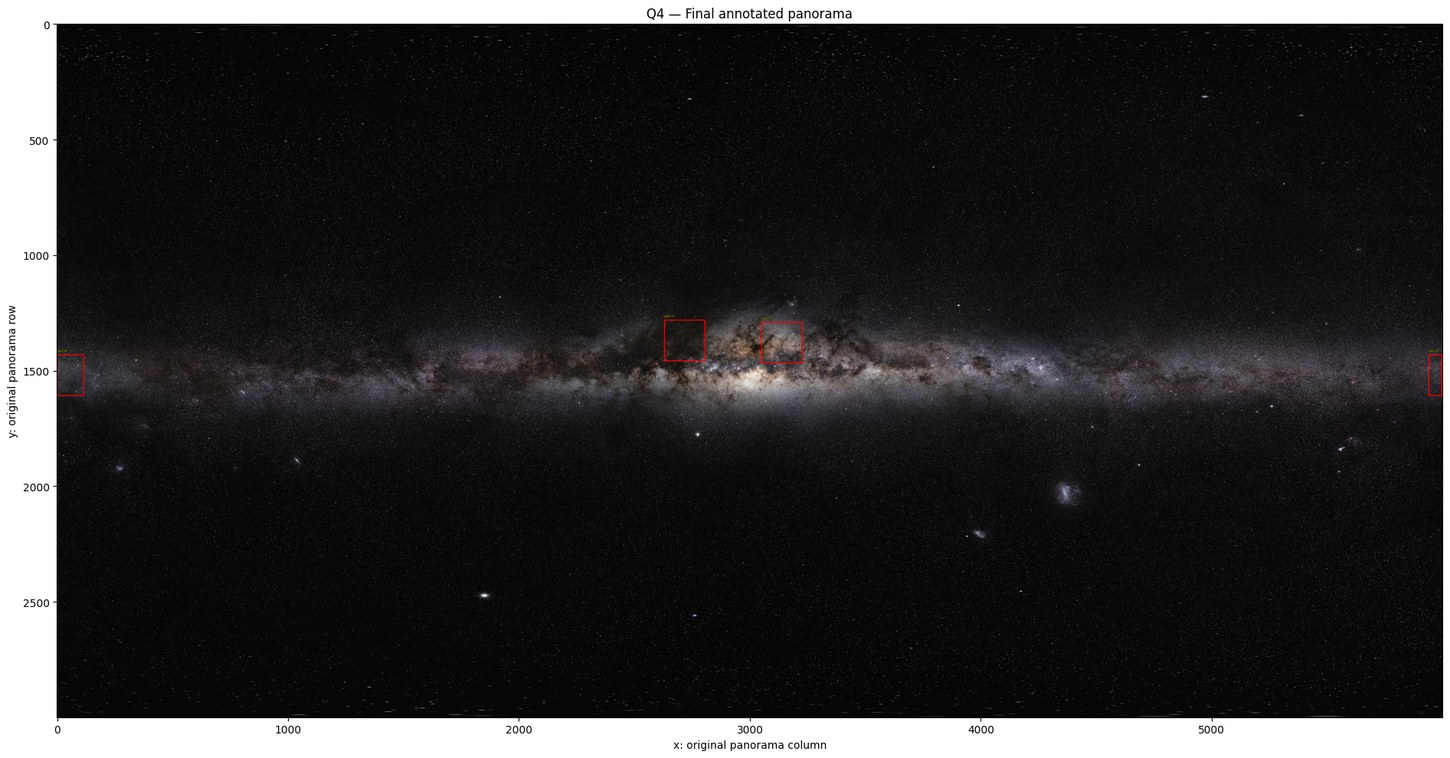

| query_id | x | y |
|---|---:|---:|
| query_01 | 2630 | 1280 |
| query_02 | 3050 | 1289 |
| query_03 | 5939 | 1430 |
| query_04 | -1 | -1 |
| query_05 | -1 | -1 |

   query_id  part_x  part_y  part_width  part_height
0  query_01    2630    1280         180          180
1  query_02    3050    1289         180          180
2  query_03    5939    1430          61          180
3  query_03       0    1430         119          180

In [ ]:
# Q4 — Export the annotated panorama and computed coordinate table

from PIL import ImageDraw, ImageFont

q4_output_dir = RESULTS / "q4"
q4_output_dir.mkdir(parents=True, exist_ok=True)

q4_table = pd.DataFrame(
    q4_results, columns=["query_id", "x", "y"]
)

assert q4_scene.shape == (3000, 6000, 3)
assert len(q4_table) == 5
assert q4_table["query_id"].is_unique
assert set(q4_table["query_id"]) == set(q4_queries)

canvas = Image.fromarray(q4_scene.copy())
draw = ImageDraw.Draw(canvas)

# Use a readable font at the original panorama resolution.
try:
    font = ImageFont.truetype("DejaVuSans.ttf", 28)
except OSError:
    font = ImageFont.load_default()

box_size = 180
width, height = canvas.size
q4_box_parts = []

for row in q4_table.itertuples(index=False):
    x, y = row.x, row.y

    assert isinstance(x, (int, np.integer))
    assert isinstance(y, (int, np.integer))

    if x == -1 and y == -1:
        continue

    assert 0 <= x < width
    assert 0 <= y <= height - box_size

    # Inclusive drawing coordinates preserve a 180-pixel extent.
    right_part_width = min(box_size, width - x)
    parts = [(x, y, right_part_width, box_size)]

    if right_part_width < box_size:
        parts.append(
            (0, y, box_size - right_part_width, box_size)
        )

    assert sum(part[2] for part in parts) == box_size

    for left, top, part_width, part_height in parts:
        draw.rectangle(
            (
                left,
                top,
                left + part_width - 1,
                top + part_height - 1,
            ),
            outline="red",
            width=4,
        )

        label_bounds = draw.textbbox(
            (0, 0), row.query_id, font=font
        )
        label_width = label_bounds[2] - label_bounds[0]
        label_height = label_bounds[3] - label_bounds[1]

        label_x = max(0, min(left, width - label_width - 8))
        label_y = max(0, top - label_height - 12)

        draw.text(
            (label_x, label_y),
            row.query_id,
            font=font,
            fill="yellow",
            stroke_width=1,
            stroke_fill="black",
        )

        q4_box_parts.append({
            "query_id": row.query_id,
            "part_x": left,
            "part_y": top,
            "part_width": part_width,
            "part_height": part_height,
        })

q4_annotated = np.array(canvas)
assert q4_annotated.shape == q4_scene.shape

q4_image_path = q4_output_dir / "annotated_panorama.png"
canvas.save(q4_image_path)

with Image.open(q4_image_path) as image:
    saved_annotation = np.array(image)

assert np.array_equal(saved_annotation, q4_annotated)

q4_table.to_csv(
    q4_output_dir / "coordinates.csv", index=False
)

q4_coordinate_markdown = (
    "| query_id | x | y |\n"
    "|---|---:|---:|\n"
    + "\n".join(
        f"| {row.query_id} | {row.x} | {row.y} |"
        for row in q4_table.itertuples(index=False)
    )
)

(q4_output_dir / "coordinates.md").write_text(
    q4_coordinate_markdown,
    encoding="utf-8",
)

fig, ax = plt.subplots(figsize=(20, 10))
ax.imshow(q4_annotated)
ax.set_title("Q4 — Final annotated panorama")
ax.set_xlabel("x: original panorama column")
ax.set_ylabel("y: original panorama row")
plt.tight_layout()
plt.show()

display(Markdown(q4_coordinate_markdown))
display(pd.DataFrame(q4_box_parts))

print("Saved panorama size (width, height):", canvas.size)
print("Saved PNG matches annotated array:", True)
print("Saved to:", q4_image_path)

### Q4 — Coordinate Table

| query_id | x | y |
|---|---:|---:|
| query_01 | 2630 | 1280 |
| query_02 | 3050 | 1289 |
| query_03 | 5939 | 1430 |
| query_04 | -1 | -1 |
| query_05 | -1 | -1 |

### Q4 — Method, Results, and Limitations

#### Input analysis

The search panorama has dimensions of 6000 × 3000 pixels.
The five query images have different dimensions, ranging from
162 to 198 pixels in width and 162 to 202 pixels in height.

Each query was converted to grayscale and resized to 180 × 180
for matching. This tests independent resizing of width and height
as an approximate geometric model. It does not establish that
resizing is the only transformation applied to the queries.

All searches used the original panorama resolution. Reported
coordinates refer to the top-left corner of a 180 × 180 region
in that panorama.

#### Baseline matching

A baseline search used zero-mean normalized cross-correlation
(NCC) between each resized grayscale query and all valid panorama
regions. This reduces sensitivity to uniform brightness offsets
and positive contrast scaling.

For each query, the highest-scoring position and the strongest
non-overlapping alternative were recorded. A high score alone
was not treated as sufficient evidence of presence.

The baseline produced relatively high scores even for candidates
whose fine structures did not match the query. This motivated
a comparison based on local detail.

#### Detail matching and spatial verification

A detail representation was formed by subtracting a Gaussian-smoothed
image, with σ = 3.0, from the grayscale image. This reduces slowly
varying brightness patterns while retaining smaller structures,
including both useful features and noise.

First, detail NCC was measured at the baseline candidate locations.
Then a new global search was performed using detail NCC throughout
the panorama. A 12-pixel margin was excluded from each side of the
query, leaving a 156 × 156 comparison region. Search indices were
arranged so that the reported coordinates still described the full
180 × 180 region.

For each global detail candidate, the comparison region was divided
into four 78 × 78 quadrants. NCC was measured separately in each
quadrant to check whether agreement was spatially distributed.
These regional measurements are related consistency checks, not
independent statistical tests.

#### Horizontal seam handling

The panorama was treated as periodic horizontally. Filtering used
wrapped horizontal context, and search extraction included columns
from the left edge after the right edge. Vertical coordinates were
restricted so that the full region remained inside the image;
no vertical wrapping was used.

The selected query_03 region begins at x = 5939. Its 180-pixel width
consists of 61 columns at the right edge and 119 columns at the
left edge. Both visible parts were annotated with the same query ID.

#### Acceptance and rejection

The same three conditions were applied to every query:

- Best detail NCC ≥ 0.30.
- Difference from the strongest non-overlapping alternative ≥ 0.15.
- Minimum NCC across the four quadrants ≥ 0.20.

All three conditions had to pass for a detection to be accepted.
Otherwise, the output coordinates were set to (-1, -1).

These thresholds were heuristic choices informed by the observed
diagnostics. They were not specified by the instructor or calibrated
using ground-truth labels. The rule combines candidate similarity,
separation from alternative locations, and spatial consistency.

#### Results

| Query | Best detail NCC | Detail gap | Minimum quadrant NCC | Decision |
|---|---:|---:|---:|---|
| query_01 | 0.7016 | 0.6315 | 0.6788 | Accepted |
| query_02 | 0.5880 | 0.5380 | 0.5744 | Accepted |
| query_03 | 0.5502 | 0.4962 | 0.5130 | Accepted |
| query_04 | 0.0595 | 0.0034 | 0.0080 | Rejected |
| query_05 | 0.0696 | 0.0014 | 0.0258 | Rejected |

For queries 01–03, the grayscale and global detail searches selected
the same coordinates. Their detail scores were clearly separated
from non-overlapping alternatives, and all four quadrants showed
positive agreement above 0.51.

Queries 04 and 05 had low global detail scores, small gaps between
competing locations, and weak agreement in most quadrants.
They were rejected by the common decision rule.

#### Limitations

Only resizing-based geometry was searched. Rotation, shear,
perspective changes, and other geometric transformations were not
explicitly estimated. A present query requiring such transformations
could therefore be missed.

Noise, blur, and resampling can reduce detail correlation. Subtracting
a smooth background also removes potentially useful broad structure
and does not distinguish noise from genuine features.

The acceptance thresholds were selected after inspecting the
diagnostics and have not been validated on a separate dataset.
Rejection indicates insufficient matching evidence under the tested
model, rather than proof of absence under every possible transformation.

#### Final output

The coordinate table was generated from the computed candidates and
acceptance decisions. The generated table was copied into a Markdown
cell without manually changing its coordinates.

The annotated panorama retains its original dimensions of
6000 × 3000 pixels. Accepted detections have axis-aligned 180 × 180
regions and query labels, with the seam-crossing region drawn in
two parts. Rejected queries have no bounding boxes.

The panorama was saved as `annotated_panorama.png`. Reloading the
saved PNG confirmed exact equality with the annotated array.

## AI Use Disclosure

### Tool and scope of assistance

I used OpenAI Codex to assist with Questions 1–4. The assistance
included interpreting the assignment requirements, generating the
initial notebook structure, drafting and revising code cells,
explaining algorithms and diagnostic measurements, interpreting
executed outputs, and drafting Markdown discussions.

The assistance was substantial and included implementation code,
parameter suggestions, and method-selection advice. It was not
limited to proofreading or formatting.

### My participation and verification

I executed the proposed cells in Google Colab and shared their
outputs for review. I asked follow-up questions about the methods,
measurements, intermediate results, and submission requirements.

I requested explanations before proceeding when the reasoning was
unclear to me. For example, I asked what the NCC scores measured,
how candidate locations were selected, how checking fixed candidates
differed from searching the full panorama, and why subtracting a
smooth background changes the comparison. These follow-up questions
were part of my effort to understand the method rather than rely
only on the displayed scores.

I corrected the output directory to match my Google Drive project
location and requested consistent Markdown formatting across the
four questions. I also asked which obsolete cells should be removed
to prevent them from overwriting the selected results.

The executed checks included image dimensions, data types, binary
values for Q3, saved-image equality, and the dimensions and horizontal
seam handling of the Q4 annotations. These checks verify specific
implementation and output properties; they do not establish accuracy
against the hidden reference data.

### Assistance by question

- **Q1:** Codex helped implement and compare upper-endpoint and
  midpoint histogram matching, interpret RGB histograms and CDF
  measurements, verify the saved output, and explain the limitations
  of recovering information from histograms.

- **Q2:** Codex helped analyze the five observations, check geometric
  consistency, compare intensity calibration models, implement
  supported-value mapping and agreement-weighted fusion, interpret
  diagnostics, and document the selected reconstruction.

- **Q3:** Codex helped implement Gaussian convolution, Sobel gradients,
  non-maximum suppression, and hysteresis using basic numerical
  operations. It also suggested parameter comparisons and helped
  interpret the tradeoff between structural edges and background
  responses.

- **Q4:** Codex helped implement grayscale and detail-based template
  matching, horizontal seam handling, regional consistency checks,
  heuristic acceptance criteria, and programmatic coordinate and
  annotation outputs.

### Question chain

The following are my prompts and follow-up
questions. Related repeated requests to review executed outputs are grouped together.

1. Help me interpret the assignment requirements and organize my work in an IPython/Colab notebook.
2. Correct the results directory to
   `results`.
3. Review the Q1 restoration, histogram, and CDF results.
4. Check whether the saved Q1 image matches the selected result and
   explain whether the verification cell should be retained.
5. Clarify whether Q1–Q4 are submitted through the notebook and whether
   the results remain visible inside it.
6. Explain Q2 and guide me through its cells step by step.
7. Review the observation statistics, geometric checks, intensity
   relationships, calibration candidates, and fusion comparisons.
8. Explain how much work remains for Q2 and help finalize its output.
9. Explain Q3 according to the instructor's requirements and help me understand the purpose of each implementation step.
10. Review smoothing, gradient, and binary-edge comparisons and help
    select the final parameters.
11. Identify obsolete Q3 cells that could overwrite the selected result.
12. Draft the Q3 Markdown discussion and check it against the assignment.
13. Inspect my updated notebook and match the discussion format used
    in Q1 and Q2.
14. Explain Q4 according to the PDF and help me understand the matching pipeline step by step.
15. Explain the NCC table columns and the meaning of the candidate
    scores.
16. Explain the difference between checking fixed candidates and
    searching the whole panorama using detail responses.
17. Explain where the candidates come from and what subtracting a
    smooth background means.
18. Continue with regional verification, acceptance decisions, and
    programmatic panorama annotation.
19. Review the Q4 outputs and draft a discussion consistent with the
    preceding questions.
20. Help prepare this AI-use disclosure and question-chain summary.

### Responsibility and limitations

AI suggestions were used to develop the submitted approach, but they
do not provide ground-truth validation. Some parameters and acceptance
thresholds were selected heuristically after examining the diagnostics.

I remain responsible for reviewing the submitted code, results, and
explanations, including any errors or unsupported conclusions.

## Submission Checks

The following checks cover selected output dimensions, Q3 binary values,
and the existence of the Q4 export. Additional checks in the final output
cells verify saved-image equality and output properties.

These checks do not measure accuracy against the hidden references or
verify external sharing permissions. Before submission, confirm both
team members' names and NetIDs, the Markdown discussions and coordinate
table, and the AI-use disclosure. Restart the Colab runtime, run all
cells in order, save the executed outputs, and submit the accessible
Colab link through the course's Brightspace submission interface.

In [ ]:
checks = {
    'Q1 same dimensions': q1_final.shape == q1_input.shape,
    'Q2 final assigned, correct dimensions': q2_final is not None and q2_final.shape[:2] == (810, 1024),
    'Q3 binary single channel': q3_final.shape == (900, 900) and set(np.unique(q3_final)).issubset({0, 255}),
    'Q4 result exported': q4_results is not None and (RESULTS / 'q4/annotated_panorama.png').exists(),
}
for name, ok in checks.items():
    print(('PASS' if ok else 'TODO'), name)
print('Manual review: complete all discussions, the Q4 Markdown table, names/NetIDs, and AI question history.')
print('Restart runtime -> Run all -> Save outputs -> Enable link sharing -> Submit the Colab link on Brightspace.')

PASS Q1 same dimensions
PASS Q2 final assigned, correct dimensions
PASS Q3 binary single channel
PASS Q4 result exported
Manual review: complete all discussions, the Q4 Markdown table, names/NetIDs, and AI question history.
Restart runtime -> Run all -> Save outputs -> Enable link sharing -> Submit the Colab link on Brightspace.
